# NASA PACE OCI Bio-Optical TSS Inversion — Case 3b (`RF_Full_WithD2`) Overfitting, Generalization & Dual-Uncertainty Pipeline (*Remote Sensing of Environment* Edition)

**Selected Regime:** **Case 3b** (`InSitu_Strict_QCGood_TSS` + `PACE117_Option1_Marginal_LogNormal` with 80/20 Stratified-$\log_{10}(\mathrm{TSS})$ Random Holdout)  
**Selected Model:** **`RF_Full_WithD2`** (`496` Bio-Optical & Hyperspectral Features: `117` Savitzky–Golay Smoothed $R_{\mathrm{rs}}$ + `117` $L_2$-Normalized + `117` $d^1$ + `117` $d^2$ + `28` Bio-Optical Ratios/QAA/IOPs)  
**Journal-Grade Additions:**
1. **RSE Overfitting & Generalization Suite:** Train vs. OOB vs. 5-Fold Stratified CV vs. Holdout (including **In-Situ-only vs. Simulated-only** holdout breakdown), Learning Curves, Regularized vs. Unregularized Ablation, Multi-Seed Stability, **Spatial GroupKFold** cross-domain stress test on in-situ water bodies, **Y-Randomization** permutation null test, Turbidity-Regime Stratified Errors, and Held-Out Permutation Feature Importance.
2. **Dual-Method Uncertainty Quantification (UQ) Pipeline:**
   - **Method 1 (`UQ1_TreeEnsemble`):** Epistemic inter-tree dispersion across all `300` RF trees ($\sigma_{\mathrm{tree},\log}$ and empirical 68% / 95% quantiles).
   - **Method 2 (`UQ2_Conformal`):** Distribution-free Locally-Weighted Out-of-Fold Conformal Prediction intervals calibrated **exclusively on In-Situ out-of-fold residuals** to guarantee tight empirical 68% and 95% coverage on real in-situ and matchup observations.
3. **PACE OCI & SoRad Matchups with Uncertainty Error Bars:** 2x2 RSE vector PDF scatter plots with asymmetric error bars for both UQ methods + Station-wise transects with uncertainty ribbons.
4. **Global In-Situ Regional Generalization & Spectral Peak Maps:**
   - **Figure 1:** Global map of in-situ test data across **North America**, **Europe**, **North Pacific**, and **Southern Hemisphere** with regional performance scatter plots (solid regression line, dashed 1:1 line).
   - **Figure 2:** Global map of all in-situ $R_{\mathrm{rs}}$ + TSS stations colored by dominant $R_{\mathrm{rs}}$ spectral peak wavelength.

> **Execution Note:** Run cells sequentially from top to bottom (**Run $\rightarrow$ Run All Cells**). All outputs are saved into a dedicated, self-contained folder `RF_Case3b_D2_TSS_Uncertainty_RSE/`.
- **Unified Figure Preservation**: Retains all figures from both prior pipeline versions (including both linear-tick and $\log_{10}(\mathrm{TSS})$ spectral envelope PDFs, linear TSS histograms, overfitting/generalization suite, dual-UQ calibration, error-barred matchups, and global regional/peak maps).
- **Offline Vector Coastlines & Land/Ocean Boundaries**: All global and satellite maps render crisp vector land polygons, ocean fill, coastlines, and country borders using a 3-tier vector basemap engine (`Cartopy` $\rightarrow$ `GeoPandas` $\rightarrow$ embedded offline Natural Earth 110m vector polygons) so coastlines never fail to render.
- **Step 12 & Step 13 — Model Saving & PACE OCI L2 `.nc` Satellite Inference**: Saves the trained `RF_Full_WithD2` + `StandardScaler` + In-Situ conformal UQ bundle and applies it step-by-step to SNAP `gpt`-subsetted or NASA OB.DAAC PACE OCI Level-2 `.nc` files (e.g., `PACE_OCI.20241202T061144.L2.OC_AOP.V3_2_subset.nc`) with `l2_flags` masking, gap-aware spectral alignment, vectorized 496-feature extraction, Dual-UQ mapping, and NetCDF export.


## Step 1: Standalone Folder Hierarchy, CPU Threading, Regularized RF Config & RSE Journal Styling

### Why & How
1. **Separate Output Folder (`RF_Case3b_D2_TSS_Uncertainty_RSE/`):** Isolates all Case 3b (`RF_Full_WithD2`) datasets, overfitting/generalization audits, dual-uncertainty tables, and error-barred matchup figures from earlier multi-case runs across 7 numbered subfolders (`01` through `07`).
2. **Identical Regularized Random Forest Setup:** Preserves the exact hyperparameters from `RF_PACE117_TSS_BioOptical_RSE_v2.ipynb` (`RF_N_ESTIMATORS = 300`, `RF_MAX_DEPTH = 16`, `RF_MIN_SAMPLES_LEAF = 4`, `RF_MIN_SAMPLES_SPLIT = 8`, `RF_MAX_FEATURES = 0.25`, `RF_MAX_SAMPLES = 0.80`, `RF_CCP_ALPHA = 1e-4`, `SEED = 42`) so model architecture and regularization are 100% consistent.
3. **RSE Vector PDF Configuration:** Configures `pdf.fonttype = 42` (editable TrueType text in Illustrator), inward ticks on all 4 axes, and colorblind-safe Okabe–Ito colors.

In [1]:
# ==============================================================================
# STEP 1: STANDALONE FOLDER TREE, MULTI-CORE THREADING & RSE JOURNAL STYLING
# ==============================================================================
import os
import time
import platform
import warnings
from datetime import datetime
warnings.filterwarnings("ignore")

# Pin OpenMP / BLAS threads to performance CPU cores for deterministic speed
P_CORES = min(10, os.cpu_count() or 10)
os.environ["OMP_NUM_THREADS"] = str(P_CORES)
os.environ["MKL_NUM_THREADS"] = str(P_CORES)
os.environ["OPENBLAS_NUM_THREADS"] = str(P_CORES)
os.environ["VECLIB_MAXIMUM_THREADS"] = str(P_CORES)

import numpy as np
import pandas as pd
from scipy.signal import savgol_filter
from scipy.ndimage import gaussian_filter
from scipy.stats import linregress, spearmanr, pearsonr

from sklearn.model_selection import (
    GroupKFold,
    StratifiedKFold,
    RepeatedStratifiedKFold,
    train_test_split,
)
from sklearn.preprocessing import StandardScaler
from sklearn.ensemble import RandomForestRegressor
from sklearn.inspection import permutation_importance
from sklearn.metrics import r2_score, mean_squared_error

import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.collections import LineCollection
from matplotlib.colors import Normalize, LogNorm
from matplotlib.ticker import FixedLocator, FuncFormatter, LogLocator, NullFormatter


def _format_plain_log_tick(val, pos=None):
    """Formats positive log-scale ticks as plain decimal numbers (e.g., 0.01, 0.1, 1, 10, 100)."""
    if not np.isfinite(val) or val <= 0:
        return ""
    if val >= 1.0:
        return f"{int(round(val))}" if np.isclose(val, round(val), rtol=1e-9, atol=1e-12) else f"{val:g}"
    decimals = max(0, int(np.ceil(-np.log10(val))) + 2)
    return f"{val:.{min(decimals, 8)}f}".rstrip("0").rstrip(".")


def apply_plain_log_ticks(ax, axis="both"):
    """Applies plain decimal major tick labels (no 10^x notation) and hides minor tick labels on log axes."""
    fmt = FuncFormatter(_format_plain_log_tick)
    if axis in ("x", "both"):
        ax.xaxis.set_major_locator(LogLocator(base=10.0, numticks=12))
        ax.xaxis.set_major_formatter(fmt)
        ax.xaxis.set_minor_formatter(NullFormatter())
    if axis in ("y", "both"):
        ax.yaxis.set_major_locator(LogLocator(base=10.0, numticks=12))
        ax.yaxis.set_major_formatter(fmt)
        ax.yaxis.set_minor_formatter(NullFormatter())
from matplotlib.cm import ScalarMappable

try:
    from IPython.display import display
except ImportError:
    def display(obj):
        print(obj.to_string() if hasattr(obj, "to_string") else obj)

# ------------------------------------------------------------------------------
# REGULARIZED RANDOM FOREST HYPERPARAMETERS (IDENTICAL TO v2 NOTEBOOK)
# ------------------------------------------------------------------------------
RF_N_ESTIMATORS         = 300    # Ensemble size for low variance & stable 300-tree UQ quantiles
RF_MAX_DEPTH            = 16     # Caps tree depth to prevent memorization of single-station noise
RF_MIN_SAMPLES_LEAF     = 4      # Minimum 4 observations per terminal leaf
RF_MIN_SAMPLES_SPLIT    = 8      # Minimum 8 observations before splitting an internal node
RF_MAX_FEATURES         = 0.25   # Subsamples 25% of 496 features per split to decorrelate 2.5 nm bands
RF_MAX_SAMPLES          = 0.80   # Sub-bagging fraction with bootstrap=True & oob_score=True
RF_CCP_ALPHA            = 1e-4   # Minimal cost-complexity pruning against noisy leaf splits
CV_FOLDS                = 5      # 5-fold StratifiedKFold / Spatial GroupKFold cross-validation
RASTERIZE_DENSE_SCATTER = False  # True vector PDFs: keep all scatter markers editable in Illustrator

# ------------------------------------------------------------------------------
# REMOTE SENSING OF ENVIRONMENT (RSE) MATPLOTLIB CONFIGURATION
# ------------------------------------------------------------------------------
mpl.rcParams.update({
    "pdf.fonttype": 42,          # Embed TrueType fonts (editable text in Adobe Illustrator)
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
    "axes.linewidth": 0.9,
    "xtick.direction": "in",     # Inward ticks on all 4 axes per Elsevier/RSE style
    "ytick.direction": "in",
    "xtick.top": True,
    "ytick.right": True,
    "xtick.major.width": 0.8,
    "ytick.major.width": 0.8,
    "xtick.minor.width": 0.6,
    "ytick.minor.width": 0.6,
    "legend.frameon": True,
    "legend.edgecolor": "#888888",
})

# Colorblind-Safe Okabe-Ito Palette
OKABE_ITO = [
    "#0072B2",  # 0: Blue       -> RF_Full_WithD2 / UQ Method 1
    "#D55E00",  # 1: Vermillion -> UQ Method 2 / OLS Fit
    "#009E73",  # 2: Teal       -> 5-Fold CV / In-Situ
    "#CC79A7",  # 3: Purple     -> SoRad
    "#56B4E9",  # 4: Sky Blue   -> Train
    "#E69F00",  # 5: Amber      -> OOB
]

SEED = 42
np.random.seed(SEED)
RUN_TS = datetime.now().strftime("%Y%m%d_%H%M%S")

# ------------------------------------------------------------------------------
# SEPARATE STANDALONE DIRECTORY HIERARCHY FOR CASE 3B + UQ
# ------------------------------------------------------------------------------
CWD = os.getcwd()
FOLDER_NAME = "RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2"
if os.path.basename(CWD) == FOLDER_NAME:
    OUT_ROOT = CWD
    BASE_WORK_DIR = os.path.dirname(CWD)
else:
    OUT_ROOT = os.path.join(CWD, FOLDER_NAME)
    BASE_WORK_DIR = CWD

DIR_CLEAN_DATA     = os.path.join(OUT_ROOT, "01_reprocessed_master_datasets")
DIR_SPECTRA_FIG    = os.path.join(OUT_ROOT, "02_spectral_and_tss_distributions")
DIR_CASE3B_MODEL   = os.path.join(OUT_ROOT, "03_case3b_d2_model_and_matchups")
DIR_OVERFIT_GEN    = os.path.join(OUT_ROOT, "04_overfitting_and_generalization_tests")
DIR_UQ_PIPELINE    = os.path.join(OUT_ROOT, "05_uncertainty_quantification_pipelines")
DIR_MATCHUP_UQ_FIG = os.path.join(OUT_ROOT, "06_matchups_with_uncertainty_errorbars")
DIR_SUMMARY        = os.path.join(OUT_ROOT, "07_master_summary_tables_and_figures")
DIR_SAVED_MODEL    = os.path.join(OUT_ROOT, "08_saved_model_bundle")
DIR_L2_INFERENCE   = os.path.join(OUT_ROOT, "09_pace_l2_nc_inference_and_maps")

for d in [
    OUT_ROOT, DIR_CLEAN_DATA, DIR_SPECTRA_FIG, DIR_CASE3B_MODEL,
    DIR_OVERFIT_GEN, DIR_UQ_PIPELINE, DIR_MATCHUP_UQ_FIG, DIR_SUMMARY, DIR_SAVED_MODEL
]:
    os.makedirs(d, exist_ok=True)


def resolve_data_file(candidate_names):
    """Searches working directories, Final_data, and reprocessed_pace117_datasets for CSV files."""
    if isinstance(candidate_names, str):
        candidate_names = [candidate_names]
    search_dirs = [
        CWD,
        BASE_WORK_DIR,
        os.path.join(CWD, "Final_data"),
        os.path.join(BASE_WORK_DIR, "Final_data"),
        os.path.join(CWD, "reprocessed_pace117_datasets"),
        os.path.join(BASE_WORK_DIR, "reprocessed_pace117_datasets"),
        "/Users/masud/OneDrive02/09Nov26_TSS/Final_data",
        "/Users/masud/OneDrive02/09Nov26_TSS",
    ]
    for fname in candidate_names:
        for base in search_dirs:
            full_p = os.path.join(base, fname)
            if os.path.exists(full_p):
                return full_p
    raise FileNotFoundError(f"Could not find any of {candidate_names} in {search_dirs}")


# Resolve the 4 Updated PACE 117-Band CSV Datasets
SORAD_MASTER_FILE = resolve_data_file([
    "07_SoRad_Matchups_PACE117Bands_20261118_172240.csv",
])
PACE_MASTER_FILE = resolve_data_file([
    "08_PACE_OCI_Matchups_PACE117Bands_20261118_172240.csv",
])
INSITU_QCGOOD_TSS_FILE = resolve_data_file([
    "InSitu_Strict_QCGood_TSS_PACE_OCI_117_20261119_182408.csv",
])
SIM_MARGINAL_LOGNORM_FILE = resolve_data_file([
    "PACE117_Option1_Marginal_LogNormal.csv",
])

MODEL_NAME  = "RF_Full_WithD2"  # Selected Case 3b Model (496 features with 2nd derivative)
TARGET_COL  = "TSS"
TARGET_NAME = "TSS"
UNIT_TEX    = r"$\mathrm{mg\ l^{-1}}$"

# Canonical 117 NASA PACE OCI Wavelengths (403-718 nm, preserving 588-613 nm dichroic gap)
PACE_117_WAVELENGTHS = np.array([
    403, 405, 408, 410, 413, 415, 418, 420, 423, 425, 428, 430, 433, 435, 438,
    440, 443, 445, 448, 450, 453, 455, 458, 460, 463, 465, 468, 470, 473, 475,
    478, 480, 483, 485, 488, 490, 493, 495, 498, 500, 503, 505, 508, 510, 513,
    515, 518, 520, 523, 525, 528, 530, 533, 535, 538, 540, 543, 545, 548, 550,
    553, 555, 558, 560, 563, 565, 568, 570, 573, 575, 578, 580, 583, 585, 588,
    613, 615, 618, 620, 623, 625, 628, 630, 633, 635, 638, 640, 643, 645, 648,
    650, 653, 655, 658, 660, 663, 665, 668, 670, 673, 675, 678, 680, 683, 685,
    688, 690, 693, 695, 698, 700, 703, 705, 708, 710, 713, 718
], dtype=float)
RRS_COLS  = [f"Rrs_{int(w)}" for w in PACE_117_WAVELENGTHS]
BLUE_MASK = PACE_117_WAVELENGTHS <= 588.0   # 75 Blue-Green bands (403-588 nm)
RED_MASK  = PACE_117_WAVELENGTHS >= 613.0   # 42 Red-NIR bands (613-718 nm)

print(f"[STEP 1 READY] Machine: {platform.machine()} | CPU Cores: {P_CORES}")
print(f"  -> Output Root : {OUT_ROOT}")
print(f"  -> Regime/Model: Case 3b (Combined In-Situ + Simulated, Random Holdout) | {MODEL_NAME} (496 feats)")
print(f"  -> Anti-Overfit: max_depth={RF_MAX_DEPTH}, min_samples_leaf={RF_MIN_SAMPLES_LEAF}, "
      f"max_features={RF_MAX_FEATURES}, max_samples={RF_MAX_SAMPLES}, ccp_alpha={RF_CCP_ALPHA}")


[STEP 1 READY] Machine: arm64 | CPU Cores: 10
  -> Output Root : /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2
  -> Regime/Model: Case 3b (Combined In-Situ + Simulated, Random Holdout) | RF_Full_WithD2 (496 feats)
  -> Anti-Overfit: max_depth=16, min_samples_leaf=4, max_features=0.25, max_samples=0.8, ccp_alpha=0.0001


## Step 2: Load Updated 4 PACE 117-Band Datasets, Harmonize `TSS` & Tag Domain Provenance

### Why & How
1. **Identical Harmonization (`harmonize_tss_dataset`):** Maps all 117 spectral columns (`Rrs_403` ... `Rrs_718`), harmonizes `TSS` (> 0 mg/L), assigns `Spatial_Group` (from `lake_name`, `Sim_Source`, or $0.5^\circ$ lat/lon bins) for downstream spatial stress testing, and creates 10-bin `LogTSS_Stratum` labels for balanced 80/20 stratified partitioning.
2. **Domain Provenance Tag (`Data_Source`):** Explicitly tags each row as `InSitu` vs. `Simulated` so that in Step 7 and Step 8 we can audit Case 3b's holdout accuracy and uncertainty coverage **separately** on held-out In-Situ vs. Simulated samples (a key reviewer check for combined-data models).

In [2]:
# ==============================================================================
# STEP 2: LOAD UPDATED 4 PACE 117-BAND DATASETS & HARMONIZE TSS / GROUPS
# ==============================================================================
if "PACE_117_WAVELENGTHS" not in globals():
    raise RuntimeError("Please run Step 1 first, or click 'Run -> Run All Cells'.")

t0 = time.time()


def harmonize_tss_dataset(df, dataset_tag, require_valid_tss=True):
    """Harmonizes Rrs_403..Rrs_718 spectral columns, TSS target, Spatial_Group, and LogTSS_Stratum."""
    out = df.copy()

    # Map spectral columns to canonical Rrs_<wl> names if needed
    col_lower_map = {c.lower().strip(): c for c in out.columns}
    for w in PACE_117_WAVELENGTHS:
        wi = int(w)
        canon = f"Rrs_{wi}"
        if canon not in out.columns:
            for cand in [f"rrs_{wi}", f"rrs{wi}", f"rrs_{wi}.0", str(wi), f"{wi}.0", f"{wi}nm"]:
                if cand in col_lower_map:
                    out[canon] = pd.to_numeric(out[col_lower_map[cand]], errors="coerce")
                    break
        else:
            out[canon] = pd.to_numeric(out[canon], errors="coerce")

    missing_rrs = [c for c in RRS_COLS if c not in out.columns]
    if missing_rrs:
        raise KeyError(f"[{dataset_tag}] Missing {len(missing_rrs)} Rrs bands: {missing_rrs[:5]}...")

    # Harmonize TSS target column
    if "TSS" not in out.columns:
        for alt in ["tss", "TSS_mg_L", "TSS_mgL", "SPM", "Minerals_mg_L", "TSM"]:
            if alt in out.columns:
                out["TSS"] = pd.to_numeric(out[alt], errors="coerce")
                break
    if "TSS" not in out.columns:
        out["TSS"] = np.nan
    else:
        out["TSS"] = pd.to_numeric(out["TSS"], errors="coerce")
        out.loc[out["TSS"] <= 0, "TSS"] = np.nan

    out = out.dropna(subset=RRS_COLS).copy()
    if require_valid_tss:
        out = out[np.isfinite(out["TSS"]) & (out["TSS"] > 0)].copy()
    out = out.reset_index(drop=True)

    # Assign Spatial_Group for spatial cross-validation stress tests
    lat_col = next((c for c in ["Latitude", "latitude", "Lat", "lat"] if c in out.columns), None)
    lon_col = next((c for c in ["Longitude", "longitude", "Lon", "lon"] if c in out.columns), None)
    if lat_col is not None and lon_col is not None:
        lat_bin = np.floor(pd.to_numeric(out[lat_col], errors="coerce").fillna(0) * 2.0) / 2.0
        lon_bin = np.floor(pd.to_numeric(out[lon_col], errors="coerce").fillna(0) * 2.0) / 2.0
        geo_grp = lat_bin.astype(str) + "_" + lon_bin.astype(str)
    else:
        geo_grp = pd.Series(np.arange(len(out)) // 15, index=out.index).astype(str).radd(f"{dataset_tag}_")

    if "lake_name" in out.columns:
        lake_str = out["lake_name"].fillna("").astype(str).str.strip()
        out["Spatial_Group"] = np.where((lake_str != "") & (lake_str.str.lower() != "nan"), lake_str, geo_grp)
    elif "Sim_Source" in out.columns:
        out["Spatial_Group"] = out["Sim_Source"].fillna("Unknown").astype(str).radd("SIM_")
    else:
        out["Spatial_Group"] = geo_grp.to_numpy()

    # Assign 10-bin log10(TSS) strata for balanced random splits & StratifiedKFold
    valid_tss = out["TSS"].notna() & (out["TSS"] > 0)
    out["LogTSS_Stratum"] = 0
    if valid_tss.sum() >= 20:
        lt = np.log10(out.loc[valid_tss, "TSS"])
        out.loc[valid_tss, "LogTSS_Stratum"] = pd.qcut(lt, q=10, labels=False, duplicates="drop").astype(int)

    out["Data_Source"] = dataset_tag
    return out


def load_all_four_datasets(save_snapshots=True):
    """Loads and harmonizes all 4 PACE 117-band CSV datasets."""
    _df_qc    = harmonize_tss_dataset(pd.read_csv(INSITU_QCGOOD_TSS_FILE, low_memory=False), "InSitu", require_valid_tss=True)
    _df_sim   = harmonize_tss_dataset(pd.read_csv(SIM_MARGINAL_LOGNORM_FILE, low_memory=False), "Simulated", require_valid_tss=True)
    _df_pace  = harmonize_tss_dataset(pd.read_csv(PACE_MASTER_FILE, low_memory=False), "PACE_OCI", require_valid_tss=False)
    _df_sorad = harmonize_tss_dataset(pd.read_csv(SORAD_MASTER_FILE, low_memory=False), "SoRad", require_valid_tss=False)

    for _df_m in [_df_pace, _df_sorad]:
        if "St" not in _df_m.columns:
            for alt_st in ["Station", "station", "Station_ID", "ID"]:
                if alt_st in _df_m.columns:
                    _df_m["St"] = _df_m[alt_st]
                    break
            else:
                _df_m["St"] = np.arange(1, len(_df_m) + 1)

    if save_snapshots:
        _df_sim.to_csv(os.path.join(DIR_CLEAN_DATA, f"01_PACE117_Marginal_LogNormal_{RUN_TS}.csv"), index=False)
        _df_qc.to_csv(os.path.join(DIR_CLEAN_DATA, f"02_InSitu_Strict_QCGood_TSS_{RUN_TS}.csv"), index=False)
        _df_pace.to_csv(os.path.join(DIR_CLEAN_DATA, f"03_PACE_OCI_Matchups_{RUN_TS}.csv"), index=False)
        _df_sorad.to_csv(os.path.join(DIR_CLEAN_DATA, f"04_SoRad_Matchups_{RUN_TS}.csv"), index=False)

    return _df_qc, _df_sim, _df_pace, _df_sorad


df_qc, df_sim, df_pace, df_sorad = load_all_four_datasets(save_snapshots=True)

print(f"[STEP 2 DONE in {time.time() - t0:.2f}s]")
print(f"  -> 1. Simulated Marginal LogNormal : {len(df_sim):,} rows | TSS: [{df_sim['TSS'].min():.3f}, {df_sim['TSS'].max():.1f}] mg/L")
print(f"  -> 2. In-Situ Strict QC-Good TSS   : {len(df_qc):,} rows | TSS: [{df_qc['TSS'].min():.3f}, {df_qc['TSS'].max():.1f}] mg/L | Spatial Groups: {df_qc['Spatial_Group'].nunique()}")
print(f"  -> 3. PACE OCI Matchups            : {len(df_pace):,} rows (valid TSS: {df_pace['TSS'].notna().sum()})")
print(f"  -> 4. SoRad Matchups               : {len(df_sorad):,} rows (valid TSS: {df_sorad['TSS'].notna().sum()})")

[STEP 2 DONE in 0.48s]
  -> 1. Simulated Marginal LogNormal : 6,000 rows | TSS: [0.003, 1194.1] mg/L
  -> 2. In-Situ Strict QC-Good TSS   : 4,582 rows | TSS: [0.100, 2626.8] mg/L | Spatial Groups: 404
  -> 3. PACE OCI Matchups            : 10 rows (valid TSS: 10)
  -> 4. SoRad Matchups               : 10 rows (valid TSS: 10)


## Step 3: Four-Dataset Hyperspectral Envelope (Linear-Labeled Log TSS Colorbar, Gap-Free PACE OCI) & Linear TSS Histograms

1. **Spectra Figure**: Uses a log-scaled colorbar (`LogNorm`) with **linear TSS tick labels** (`0.1, 1, 12, 100, 1000 mg/L`) so real TSS concentrations are immediately readable. For **PACE OCI**, spectra are continuously interpolated across the 588–613 nm dichroic gap without visual gaps.
2. **Linear TSS Histogram Figure**: Separate 1×2 figure comparing **In-Situ** and **Simulated** linear TSS distributions (`mg/L`) with expanded summary statistics (`N`, `Min`, `Q05`, `Q25`, `Median`, `Mean`, `SD`, `Q75`, `Q95`, `IQR`, `Max`, `CV%`, `Skewness`).

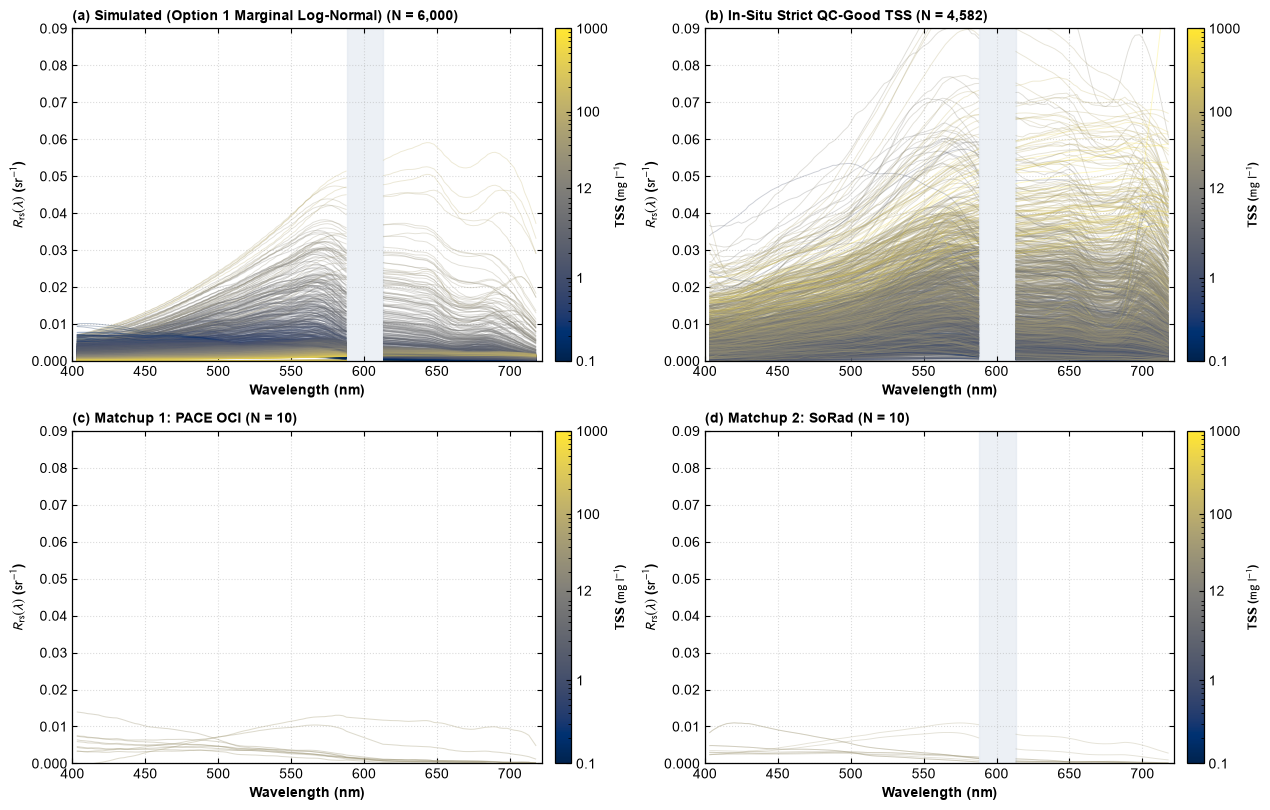

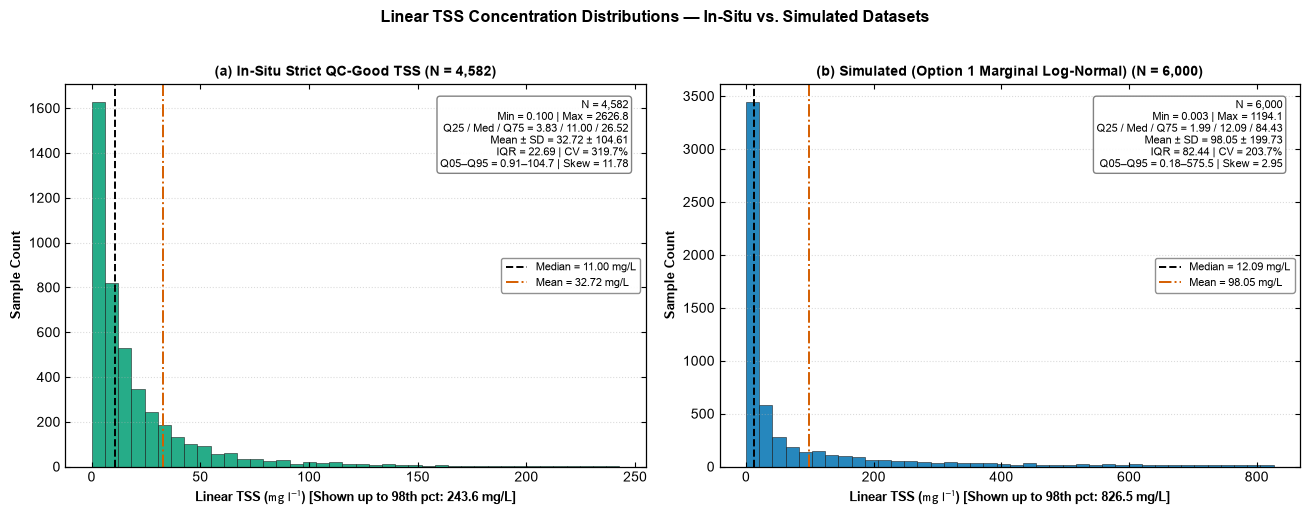

[STEP 3 DONE in 1.66s]
  -> Spectra PDF           : /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/02_spectral_and_tss_distributions/Four_Datasets_Rrs_Spectra_ColoredByTSS_LinearTicks_20261121_235611.pdf
  -> Linear Histograms PDF : /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/02_spectral_and_tss_distributions/InSitu_vs_Simulated_Linear_TSS_Histograms_20261121_235611.pdf


,Dataset,N,Min_mg_L,Q05_mg_L,Q25_mg_L,Median_mg_L,Mean_mg_L,SD_mg_L,Q75_mg_L,Q95_mg_L,IQR_mg_L,Max_mg_L,CV_pct,Skewness
0,(a) In-Situ Strict QC-Good TSS,4582,0.100000,0.910250,3.833308,11.00000,32.722577,104.606014,26.522500,104.692000,22.689192,2626.820000,319.675358,11.779598
1,(b) Simulated (Option 1 Marginal Log-Normal),6000,0.003186,0.181521,1.989629,12.09451,98.052576,199.725922,84.425732,575.466099,82.436103,1194.133476,203.692682,2.954832


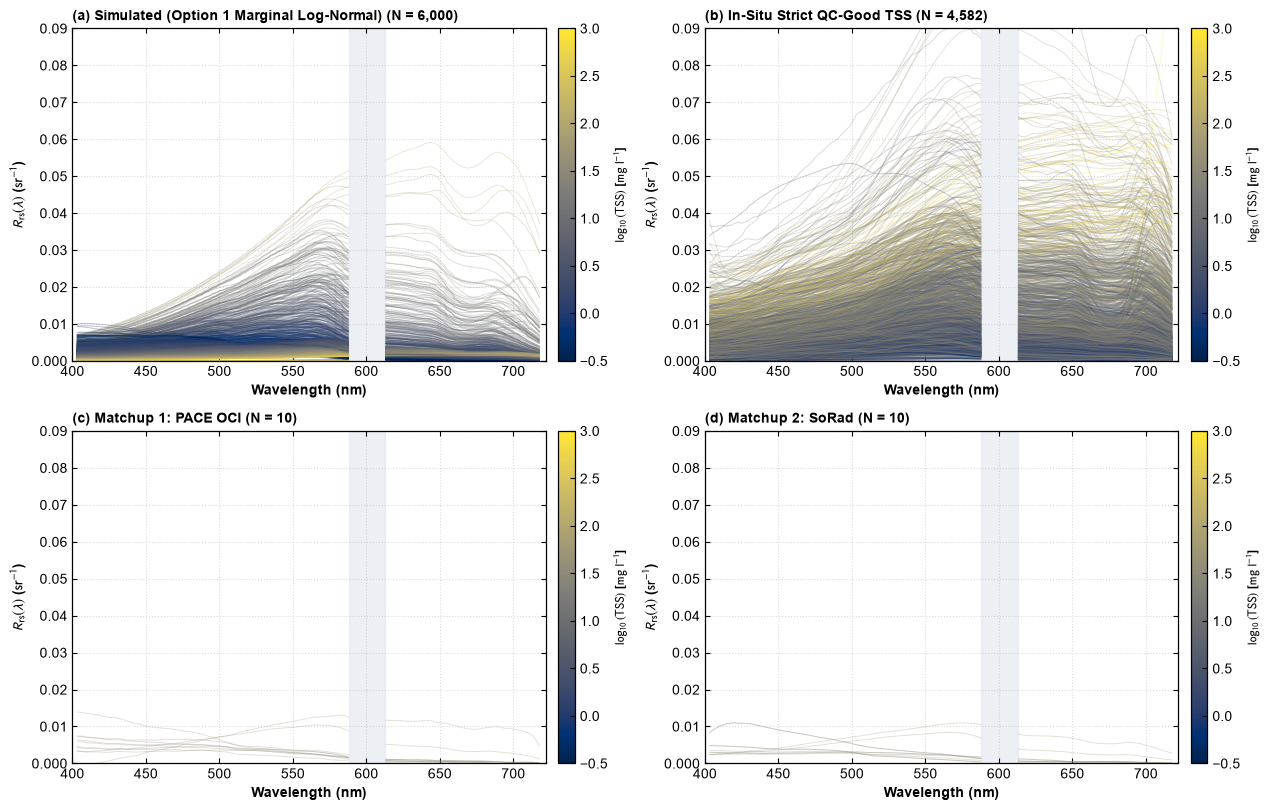

[STEP 3 DONE in 0.99s] Saved vector PDF -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/02_spectral_and_tss_distributions/Four_Datasets_Rrs_Spectra_ColoredByLog10TSS_20261121_235611.pdf


,Dataset,N_valid_TSS,Min_mg_L,Q25_mg_L,Median_mg_L,Mean_mg_L,Q75_mg_L,IQR_mg_L,Max_mg_L
0,Simulated (Option 1 Marginal Log-Normal),6000,0.003186,1.989629,12.09451,98.052576,84.425732,82.436103,1194.133476
1,In-Situ Strict QC-Good TSS,4582,0.100000,3.833308,11.00000,32.722577,26.522500,22.689192,2626.820000
2,Matchup 1: PACE OCI,10,34.770000,36.340000,36.56500,37.893667,38.041667,1.701667,46.800000
3,Matchup 2: SoRad,10,34.433333,35.557500,36.40000,37.553667,37.875000,2.317500,46.800000


In [3]:
# ==============================================================================
# STEP 3: FOUR-DATASET SPECTRAL ENVELOPE & SEPARATE LINEAR TSS HISTOGRAMS
# ==============================================================================
from scipy.stats import skew

if any(v not in globals() for v in ["df_qc", "df_sim", "df_pace", "df_sorad"]):
    df_qc, df_sim, df_pace, df_sorad = load_all_four_datasets(save_snapshots=True)

t0 = time.time()

datasets_dict = {
    "Simulated (Option 1 Marginal Log-Normal)": df_sim,
    "In-Situ Strict QC-Good TSS":               df_qc,
    "Matchup 1: PACE OCI":                      df_pace,
    "Matchup 2: SoRad":                         df_sorad,
}

fig, axes = plt.subplots(2, 2, figsize=(12.8, 8.2))
axes = axes.ravel()
cmap = plt.get_cmap("cividis")
# Log color scale with linear TSS bounds (0.1 to 1000 mg/L)
norm = LogNorm(vmin=0.1, vmax=1000.0)

wl_blue = PACE_117_WAVELENGTHS[BLUE_MASK]
wl_red  = PACE_117_WAVELENGTHS[RED_MASK]
wl_interp_pace = np.arange(403.0, 718.5, 2.5)  # Continuous gap-free grid for PACE OCI

stats_rows = []
for idx, (label, df) in enumerate(datasets_dict.items()):
    ax = axes[idx]
    R = df[RRS_COLS].to_numpy(dtype=float)
    tss = pd.to_numeric(df["TSS"], errors="coerce").to_numpy(dtype=float)

    step = max(1, len(R) // 1400)
    sub_idx = np.arange(0, len(R), step)
    R_sub = R[sub_idx]
    tss_sub = tss[sub_idx]

    colors = [
        cmap(norm(np.clip(v, 0.1, 1000.0))) if (np.isfinite(v) and v > 0) else (0.58, 0.64, 0.72, 0.30)
        for v in tss_sub
    ]

    if "PACE OCI" in label:
        # Interpolate PACE OCI spectra continuously across the 588-613 nm gap (no gaps)
        segs_full = []
        for row in R_sub:
            valid_w = np.isfinite(row)
            if valid_w.sum() >= 2:
                r_cont = np.interp(wl_interp_pace, PACE_117_WAVELENGTHS[valid_w], row[valid_w])
                segs_full.append(np.column_stack([wl_interp_pace, r_cont]))
        if segs_full:
            ax.add_collection(LineCollection(segs_full, colors=colors[:len(segs_full)], alpha=0.35, linewidths=0.75))
    else:
        segs_blue = [np.column_stack([wl_blue, row[BLUE_MASK]]) for row in R_sub]
        segs_red  = [np.column_stack([wl_red,  row[RED_MASK]])  for row in R_sub]
        ax.add_collection(LineCollection(segs_blue, colors=colors, alpha=0.28, linewidths=0.68))
        ax.add_collection(LineCollection(segs_red,  colors=colors, alpha=0.28, linewidths=0.68))
        ax.axvspan(588, 613, color="#E2E8F0", alpha=0.65, label="OCI Dichroic Gap")

    ax.set_title(f"({chr(97 + idx)}) {label} (N = {len(df):,})", loc="left", fontsize=10.0, fontweight="bold")
    ax.set_xlabel("Wavelength (nm)", fontweight="bold")
    ax.set_ylabel(r"$R_{\mathrm{rs}}(\lambda)$ ($\mathrm{sr^{-1}}$)", fontweight="bold")
    ax.set_xlim(400, 722)
    # Fixed y-axis range (0.000 - 0.09 sr^-1) across all spectra panels for direct visual comparison
    ax.set_ylim(0.000, 0.09)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.3f}" if np.isclose(y, 0.0) else f"{y:g}"))
    ax.grid(True, linestyle=":", alpha=0.45)

    # Add a separate TSS colorbar to each spectra subplot individually
    sm_panel = ScalarMappable(cmap=cmap, norm=norm)
    sm_panel.set_array([])
    cbar_p = fig.colorbar(sm_panel, ax=ax, orientation="vertical", fraction=0.042, pad=0.025)
    cbar_p.locator = FixedLocator([0.1, 1, 12, 100, 1000])
    cbar_p.formatter = FuncFormatter(lambda x, pos: f"{x:g}")
    cbar_p.update_ticks()
    cbar_p.set_label(r"TSS ($\mathrm{mg\ l^{-1}}$)", fontsize=8.5, fontweight="bold")

    fin_tss = tss[np.isfinite(tss) & (tss > 0)]
    if len(fin_tss) > 0:

        stats_rows.append({
            "Dataset": label, "N_valid_TSS": len(fin_tss),
            "Min_mg_L": np.min(fin_tss),
            "Q05_mg_L": np.percentile(fin_tss, 5),
            "Q25_mg_L": np.percentile(fin_tss, 25),
            "Median_mg_L": np.median(fin_tss),
            "Mean_mg_L": np.mean(fin_tss),
            "SD_mg_L": np.std(fin_tss, ddof=1),
            "Q75_mg_L": np.percentile(fin_tss, 75),
            "Q95_mg_L": np.percentile(fin_tss, 95),
            "IQR_mg_L": np.percentile(fin_tss, 75) - np.percentile(fin_tss, 25),
            "Max_mg_L": np.max(fin_tss),
            "CV_pct": 100.0 * np.std(fin_tss, ddof=1) / max(np.mean(fin_tss), 1e-12),
            "Skewness": float(skew(fin_tss)),
        })

# Layout adjusted so each subplot's individual TSS colorbar fits cleanly without overlap
plt.tight_layout()
spec_pdf = os.path.join(DIR_SPECTRA_FIG, f"Four_Datasets_Rrs_Spectra_ColoredByTSS_LinearTicks_{RUN_TS}.pdf")
fig.savefig(spec_pdf, format="pdf", bbox_inches="tight")
plt.show()

# ------------------------------------------------------------------------------
# SEPARATE FIGURE: LINEAR TSS HISTOGRAMS FOR IN-SITU & SIMULATED ONLY + STATS
# ------------------------------------------------------------------------------
hist_datasets = [
    ("(a) In-Situ Strict QC-Good TSS",              df_qc,  OKABE_ITO[2]),
    ("(b) Simulated (Option 1 Marginal Log-Normal)", df_sim, OKABE_ITO[0]),
]

fig_h, axes_h = plt.subplots(1, 2, figsize=(13.2, 5.0))
lin_hist_stats = []
for ax_h, (h_title, df_h, h_col) in zip(axes_h, hist_datasets):
    tss_h = pd.to_numeric(df_h["TSS"], errors="coerce").to_numpy(dtype=float)
    fin_h = tss_h[np.isfinite(tss_h) & (tss_h > 0)]
    q98 = float(np.percentile(fin_h, 98.0))
    fin_plot = fin_h[fin_h <= q98]

    ax_h.hist(fin_plot, bins=40, color=h_col, edgecolor="#1a1a1a", linewidth=0.45, alpha=0.85)
    med_v = float(np.median(fin_h))
    mean_v = float(np.mean(fin_h))
    ax_h.axvline(med_v,  color="#000000", ls="--", lw=1.4, label=f"Median = {med_v:.2f} mg/L")
    ax_h.axvline(mean_v, color="#D55E00", ls="-.", lw=1.4, label=f"Mean = {mean_v:.2f} mg/L")

    ax_h.set_title(f"{h_title} (N = {len(fin_h):,})", fontsize=10.2, fontweight="bold")
    ax_h.set_xlabel(f"Linear TSS ({UNIT_TEX}) [Shown up to 98th pct: {q98:.1f} mg/L]", fontsize=9.0, fontweight="bold")
    ax_h.set_ylabel("Sample Count", fontsize=9.0, fontweight="bold")
    ax_h.grid(True, axis="y", ls=":", alpha=0.45)

    st_dict = {
        "Dataset": h_title,
        "N": int(len(fin_h)),
        "Min_mg_L": float(np.min(fin_h)),
        "Q05_mg_L": float(np.percentile(fin_h, 5)),
        "Q25_mg_L": float(np.percentile(fin_h, 25)),
        "Median_mg_L": med_v,
        "Mean_mg_L": mean_v,
        "SD_mg_L": float(np.std(fin_h, ddof=1)),
        "Q75_mg_L": float(np.percentile(fin_h, 75)),
        "Q95_mg_L": float(np.percentile(fin_h, 95)),
        "IQR_mg_L": float(np.percentile(fin_h, 75) - np.percentile(fin_h, 25)),
        "Max_mg_L": float(np.max(fin_h)),
        "CV_pct": float(100.0 * np.std(fin_h, ddof=1) / max(mean_v, 1e-12)),
        "Skewness": float(skew(fin_h)),
    }
    lin_hist_stats.append(st_dict)

    stats_txt = (
        f"N = {st_dict['N']:,}\n"
        f"Min = {st_dict['Min_mg_L']:.3f} | Max = {st_dict['Max_mg_L']:.1f}\n"
        f"Q25 / Med / Q75 = {st_dict['Q25_mg_L']:.2f} / {st_dict['Median_mg_L']:.2f} / {st_dict['Q75_mg_L']:.2f}\n"
        f"Mean ± SD = {st_dict['Mean_mg_L']:.2f} ± {st_dict['SD_mg_L']:.2f}\n"
        f"IQR = {st_dict['IQR_mg_L']:.2f} | CV = {st_dict['CV_pct']:.1f}%\n"
        f"Q05–Q95 = {st_dict['Q05_mg_L']:.2f}–{st_dict['Q95_mg_L']:.1f} | Skew = {st_dict['Skewness']:.2f}"
    )
    ax_h.text(
        0.97, 0.96, stats_txt, transform=ax_h.transAxes, fontsize=7.6, va="top", ha="right",
        bbox=dict(boxstyle="round,pad=0.30", facecolor="white", alpha=0.92, edgecolor="#777777"),
    )
    ax_h.legend(loc="center right", fontsize=7.8, framealpha=0.92)

fig_h.suptitle("Linear TSS Concentration Distributions — In-Situ vs. Simulated Datasets", fontsize=11.6, fontweight="bold", y=1.02)
plt.tight_layout()
hist_pdf = os.path.join(DIR_SPECTRA_FIG, f"InSitu_vs_Simulated_Linear_TSS_Histograms_{RUN_TS}.pdf")
fig_h.savefig(hist_pdf, format="pdf", bbox_inches="tight")
plt.show()

df_stats = pd.DataFrame(stats_rows)
df_stats.to_csv(os.path.join(DIR_SPECTRA_FIG, f"Four_Datasets_TSS_Summary_Stats_{RUN_TS}.csv"), index=False)
df_lin_hist_stats = pd.DataFrame(lin_hist_stats)
df_lin_hist_stats.to_csv(os.path.join(DIR_SPECTRA_FIG, f"InSitu_Simulated_Linear_TSS_Detailed_Stats_{RUN_TS}.csv"), index=False)

print(f"[STEP 3 DONE in {time.time() - t0:.2f}s]")
print(f"  -> Spectra PDF           : {spec_pdf}")
print(f"  -> Linear Histograms PDF : {hist_pdf}")
display(df_lin_hist_stats)


# --- Preserved from earlier notebook: Log10(TSS) 4-Dataset Spectral Envelope PDF ---
# ==============================================================================
# STEP 3: FOUR-DATASET SPECTRAL ENVELOPE & LOG10(TSS) DIAGNOSTIC VECTOR PDF
# ==============================================================================
if any(v not in globals() for v in ["df_qc", "df_sim", "df_pace", "df_sorad"]):
    df_qc, df_sim, df_pace, df_sorad = load_all_four_datasets(save_snapshots=True)

t0 = time.time()

datasets_dict = {
    "Simulated (Option 1 Marginal Log-Normal)": df_sim,
    "In-Situ Strict QC-Good TSS":               df_qc,
    "Matchup 1: PACE OCI":                      df_pace,
    "Matchup 2: SoRad":                         df_sorad,
}

fig, axes = plt.subplots(2, 2, figsize=(12.8, 8.2))
axes = axes.ravel()
cmap = plt.get_cmap("cividis")
norm = Normalize(vmin=-0.5, vmax=3.0)

wl_blue = PACE_117_WAVELENGTHS[BLUE_MASK]
wl_red  = PACE_117_WAVELENGTHS[RED_MASK]

stats_rows = []
for idx, (label, df) in enumerate(datasets_dict.items()):
    ax = axes[idx]
    R = df[RRS_COLS].to_numpy(dtype=float)
    tss = pd.to_numeric(df["TSS"], errors="coerce").to_numpy(dtype=float)
    log_tss = np.log10(np.maximum(tss, 1e-4))

    step = max(1, len(R) // 1400)
    sub_idx = np.arange(0, len(R), step)
    R_sub = R[sub_idx]
    lt_sub = log_tss[sub_idx]

    segs_blue = [np.column_stack([wl_blue, row[BLUE_MASK]]) for row in R_sub]
    segs_red  = [np.column_stack([wl_red,  row[RED_MASK]])  for row in R_sub]
    colors = [cmap(norm(v)) if np.isfinite(v) else (0.58, 0.64, 0.72, 0.30) for v in lt_sub]

    ax.add_collection(LineCollection(segs_blue, colors=colors, alpha=0.28, linewidths=0.68))
    ax.add_collection(LineCollection(segs_red,  colors=colors, alpha=0.28, linewidths=0.68))

    ax.axvspan(588, 613, color="#E2E8F0", alpha=0.65, label="OCI Dichroic Gap")
    ax.set_title(f"({chr(97 + idx)}) {label} (N = {len(df):,})", loc="left", fontsize=10.0, fontweight="bold")
    ax.set_xlabel("Wavelength (nm)", fontweight="bold")
    ax.set_ylabel(r"$R_{\mathrm{rs}}(\lambda)$ ($\mathrm{sr^{-1}}$)", fontweight="bold")
    ax.set_xlim(400, 722)
    # Fixed y-axis range (0.000 - 0.09 sr^-1) across all spectra panels for direct visual comparison
    ax.set_ylim(0.000, 0.09)
    ax.yaxis.set_major_formatter(FuncFormatter(lambda y, _: f"{y:.3f}" if np.isclose(y, 0.0) else f"{y:g}"))
    ax.grid(True, linestyle=":", alpha=0.45)

    # Add a separate Log10(TSS) colorbar to each spectra subplot individually
    sm_panel = ScalarMappable(cmap=cmap, norm=norm)
    sm_panel.set_array([])
    cbar_p = fig.colorbar(sm_panel, ax=ax, orientation="vertical", fraction=0.042, pad=0.025)
    cbar_p.set_label(r"$\log_{10}(\mathrm{TSS})$ [$\mathrm{mg\ l^{-1}}$]", fontsize=8.5, fontweight="bold")

    fin_tss = tss[np.isfinite(tss) & (tss > 0)]
    if len(fin_tss) > 0:

        stats_rows.append({
            "Dataset": label, "N_valid_TSS": len(fin_tss),
            "Min_mg_L": np.min(fin_tss), "Q25_mg_L": np.percentile(fin_tss, 25),
            "Median_mg_L": np.median(fin_tss), "Mean_mg_L": np.mean(fin_tss),
            "Q75_mg_L": np.percentile(fin_tss, 75),
            "IQR_mg_L": np.percentile(fin_tss, 75) - np.percentile(fin_tss, 25),
            "Max_mg_L": np.max(fin_tss),
        })

# Layout adjusted so each subplot's individual TSS colorbar fits cleanly without overlap
plt.tight_layout()
spec_pdf = os.path.join(DIR_SPECTRA_FIG, f"Four_Datasets_Rrs_Spectra_ColoredByLog10TSS_{RUN_TS}.pdf")
fig.savefig(spec_pdf, format="pdf", bbox_inches="tight")
plt.show()

df_stats = pd.DataFrame(stats_rows)
df_stats.to_csv(os.path.join(DIR_SPECTRA_FIG, f"Four_Datasets_TSS_Summary_Stats_{RUN_TS}.csv"), index=False)
print(f"[STEP 3 DONE in {time.time() - t0:.2f}s] Saved vector PDF -> {spec_pdf}")
display(df_stats)


## Step 4: Gap-Aware Bio-Optical Feature Engineering (`496` `RF_Full_WithD2` Features)

### Why & How
Preserves the **exact 496-feature architecture** of `RF_Full_WithD2` from `RF_PACE117_TSS_BioOptical_RSE_v2.ipynb`:
1. **Piecewise Savitzky–Golay Filtering Across the `588–613 nm` OCI Dichroic Gap:** Applies `savgol_filter(window_length=5, polyorder=2)` separately on `403–588 nm` (`75` bands) and `613–718 nm` (`42` bands) to extract smoothed reflectance ($R_{\mathrm{smooth}}$, `117` features), 1st derivative ($d^1$, `117` features), and **2nd derivative ($d^2$, `117` features)** without boundary artifacts across the gap.
2. **$L_2$-Normalized Spectral Shape (`117` features):** Decouples sky-glint / illumination amplitude scaling from spectral shape.
3. **28 Semi-Analytical Bio-Optical Ratios & IOPs:** Includes OC3/blue-green log-ratios, Red/Green & NIR/Green turbidity ratios (`645/555`, `665/555`, `705/555`, `708/555`), NDSSI indices, 3-band Chl-a, MCI (`705 nm`), FLH (`683 nm`), Green Peak Height (`555 nm`), Lee et al. (2002) QAA $u(\lambda) = b_{\mathrm{bp}} / (a + b_{\mathrm{bp}})$ at `665 nm` and `708 nm`, peak wavelength, Red-NIR slope (`620–713 nm`), and trapezoidal sub-band energy integrals.

In [4]:
# ==============================================================================
# STEP 4: GAP-AWARE BIO-OPTICAL FEATURE EXTRACTION (496 FEATURES FOR WITH-D2)
# ==============================================================================
if any(v not in globals() for v in ["df_qc", "df_sim", "df_pace", "df_sorad"]):
    df_qc, df_sim, df_pace, df_sorad = load_all_four_datasets(save_snapshots=True)

t0 = time.time()
_trapz = getattr(np, "trapezoid", getattr(np, "trapz", None))


def _band_idx(wl):
    return int(np.argmin(np.abs(PACE_117_WAVELENGTHS - wl)))


IDX_413, IDX_443, IDX_490, IDX_510, IDX_555 = (
    _band_idx(413), _band_idx(443), _band_idx(490), _band_idx(510), _band_idx(555)
)
IDX_620, IDX_645, IDX_665, IDX_675, IDX_683, IDX_705, IDX_708, IDX_713 = (
    _band_idx(620), _band_idx(645), _band_idx(665), _band_idx(675),
    _band_idx(683), _band_idx(705), _band_idx(708), _band_idx(713),
)

RATIO_NAMES = [
    "Log10_OC3_MaxBlue_555", "Log10_R443_R555", "Log10_R490_R555", "Log10_R413_R443",
    "Log10_R645_R555", "Log10_R665_R555", "Log10_R705_R555", "Log10_R708_R555",
    "Log10_R665_R490", "Log10_R708_R443", "Log10_R705_R665", "Log10_R708_R675",
    "Log10_R713_R665", "NDSSI_665_555", "NDSSI_708_555", "NDSSI_708_490",
    "ThreeBand_Chla_665_705_713", "MCI_705nm", "FLH_683nm", "GreenPeakHeight_555nm",
    "QAA_u_665nm", "QAA_u_708nm", "Peak_Wavelength_nm", "Slope_RedNIR_620_713",
    "Int_Blue_403_490", "Int_Green_500_588", "Int_RedNIR_613_718", "EnergyRatio_RedEdge700_Green",
]

FEATURE_NAMES_FULL = (
    [f"Rrs_sm_{int(w)}" for w in PACE_117_WAVELENGTHS]
    + [f"Rrs_L2_{int(w)}" for w in PACE_117_WAVELENGTHS]
    + [f"d1_{int(w)}" for w in PACE_117_WAVELENGTHS]
    + [f"d2_{int(w)}" for w in PACE_117_WAVELENGTHS]
    + RATIO_NAMES
)


def extract_biooptical_features(df):
    """
    Extracts the exact 496 gap-aware hyperspectral & bio-optical features (RF_Full_WithD2):
      - R_smooth (117): Piecewise Savitzky-Golay smoothed Rrs
      - R_l2     (117): L2-normalized spectral shape vector
      - d1       (117): Piecewise 1st spectral derivative (dRrs/dlambda)
      - d2       (117): Piecewise 2nd spectral derivative (d2Rrs/dlambda2)
      - X_ratios  (28): Semi-analytical QAA u(lambda), NDSSI, Red/Green, NIR/Green, FLH, MCI & integrals
    """
    R_mat = df[RRS_COLS].to_numpy(dtype=np.float64)
    R_smooth = np.zeros_like(R_mat)
    d1 = np.zeros_like(R_mat)
    d2 = np.zeros_like(R_mat)

    wl_b, wl_r = PACE_117_WAVELENGTHS[BLUE_MASK], PACE_117_WAVELENGTHS[RED_MASK]
    dx_blue, dx_red = float(np.median(np.diff(wl_b))), float(np.median(np.diff(wl_r)))

    # Piecewise Savitzky-Golay on Blue-Green (403-588 nm)
    Rb = R_mat[:, BLUE_MASK]
    R_smooth[:, BLUE_MASK] = savgol_filter(Rb, window_length=5, polyorder=2, deriv=0, axis=1)
    d1[:, BLUE_MASK]       = savgol_filter(Rb, window_length=5, polyorder=2, deriv=1, delta=dx_blue, axis=1)
    d2[:, BLUE_MASK]       = savgol_filter(Rb, window_length=5, polyorder=2, deriv=2, delta=dx_blue, axis=1)

    # Piecewise Savitzky-Golay on Red-NIR (613-718 nm)
    Rr = R_mat[:, RED_MASK]
    R_smooth[:, RED_MASK] = savgol_filter(Rr, window_length=5, polyorder=2, deriv=0, axis=1)
    d1[:, RED_MASK]       = savgol_filter(Rr, window_length=5, polyorder=2, deriv=1, delta=dx_red, axis=1)
    d2[:, RED_MASK]       = savgol_filter(Rr, window_length=5, polyorder=2, deriv=2, delta=dx_red, axis=1)

    # L2-normalized spectral shape
    R_l2 = R_smooth / (np.linalg.norm(R_smooth, axis=1, keepdims=True) + 1e-8)

    # Positive clipped reflectance for log ratios & semi-analytical QAA inversion
    eps = 1e-6
    Rp = np.maximum(R_smooth, eps)
    oc3_num = np.maximum.reduce([Rp[:, IDX_443], Rp[:, IDX_490], Rp[:, IDX_510]])

    # Lee et al. (2002) QAA subsurface r_rs -> u(lambda) = b_bp / (a + b_bp)
    g0, g1 = 0.089, 0.1245
    rrs_665 = Rp[:, IDX_665] / (0.52 + 1.7 * Rp[:, IDX_665])
    rrs_708 = Rp[:, IDX_708] / (0.52 + 1.7 * Rp[:, IDX_708])
    u_665 = (-g0 + np.sqrt(np.maximum(g0**2 + 4.0 * g1 * rrs_665, 0.0))) / (2.0 * g1)
    u_708 = (-g0 + np.sqrt(np.maximum(g0**2 + 4.0 * g1 * rrs_708, 0.0))) / (2.0 * g1)

    peak_wl = PACE_117_WAVELENGTHS[np.argmax(R_smooth, axis=1)]
    slope_red_nir = (R_smooth[:, IDX_713] - R_smooth[:, IDX_620]) / (713.0 - 620.0)

    m_b_sub = PACE_117_WAVELENGTHS <= 490.0
    m_g_sub = (PACE_117_WAVELENGTHS >= 500.0) & (PACE_117_WAVELENGTHS <= 588.0)
    m_re_sub = PACE_117_WAVELENGTHS >= 695.0
    int_blue   = _trapz(R_smooth[:, m_b_sub], PACE_117_WAVELENGTHS[m_b_sub], axis=1)
    int_green  = _trapz(R_smooth[:, m_g_sub], PACE_117_WAVELENGTHS[m_g_sub], axis=1)
    int_rednir = _trapz(R_smooth[:, RED_MASK], wl_r, axis=1)
    int_re     = _trapz(R_smooth[:, m_re_sub], PACE_117_WAVELENGTHS[m_re_sub], axis=1)

    X_ratios = np.column_stack([
        np.log10(oc3_num / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_443] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_490] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_413] / Rp[:, IDX_443]),
        np.log10(Rp[:, IDX_645] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_665] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_705] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_665] / Rp[:, IDX_490]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_443]),
        np.log10(Rp[:, IDX_705] / Rp[:, IDX_665]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_675]),
        np.log10(Rp[:, IDX_713] / Rp[:, IDX_665]),
        (R_smooth[:, IDX_665] - R_smooth[:, IDX_555]) / (np.abs(R_smooth[:, IDX_665]) + np.abs(R_smooth[:, IDX_555]) + eps),
        (R_smooth[:, IDX_708] - R_smooth[:, IDX_555]) / (np.abs(R_smooth[:, IDX_708]) + np.abs(R_smooth[:, IDX_555]) + eps),
        (R_smooth[:, IDX_708] - R_smooth[:, IDX_490]) / (np.abs(R_smooth[:, IDX_708]) + np.abs(R_smooth[:, IDX_490]) + eps),
        ((1.0 / Rp[:, IDX_665]) - (1.0 / Rp[:, IDX_705])) * Rp[:, IDX_713],
        R_smooth[:, IDX_705] - R_smooth[:, IDX_683] - ((R_smooth[:, IDX_713] - R_smooth[:, IDX_683]) * (22.0 / 30.0)),
        R_smooth[:, IDX_683] - R_smooth[:, IDX_665] - ((R_smooth[:, IDX_705] - R_smooth[:, IDX_665]) * (18.0 / 40.0)),
        R_smooth[:, IDX_555] - R_smooth[:, IDX_490] - ((R_smooth[:, IDX_620] - R_smooth[:, IDX_490]) * (65.0 / 130.0)),
        u_665, u_708, peak_wl, slope_red_nir,
        int_blue, int_green, int_rednir, int_re / (np.abs(int_green) + eps),
    ])
    X_ratios = np.nan_to_num(X_ratios, nan=0.0, posinf=0.0, neginf=0.0)

    X_full = np.hstack([R_smooth, R_l2, d1, d2, X_ratios]).astype(np.float32)
    y_lin  = np.where(pd.to_numeric(df["TSS"], errors="coerce") > 0, pd.to_numeric(df["TSS"], errors="coerce"), np.nan).astype(np.float32)
    return X_full, y_lin


X_qc_full,    y_qc_lin    = extract_biooptical_features(df_qc)
X_sim_full,   y_sim_lin   = extract_biooptical_features(df_sim)
X_pace_full,  y_pace_lin  = extract_biooptical_features(df_pace)
X_sorad_full, y_sorad_lin = extract_biooptical_features(df_sorad)

assert X_qc_full.shape[1] == 496 and len(FEATURE_NAMES_FULL) == 496
print(f"[STEP 4 DONE in {time.time() - t0:.2f}s] Extracted 496 RF_Full_WithD2 features for all 4 datasets.")

[STEP 4 DONE in 0.05s] Extracted 496 RF_Full_WithD2 features for all 4 datasets.


## Step 5: Ocean-Color Metrics & RSE Visualization Engines (Including Error-Barred Uncertainty Scatter Plots)

### Why & How
1. **Standard Ocean-Color Log-Space Metrics (`compute_ocean_color_metrics`):** Computes $N$, $R^2_{\log10}$, $\mathrm{RMSE}_{\log10}$, $\mathrm{MdSA}\%$, $\mathrm{SSPB}\%$, Pearson $r_{\log}$, Spearman $\rho$, and log-log OLS Slope/Intercept.
2. **RSE Density-Contour 1:1 Scatter Engine (`save_rse_density_scatter_pdf`):** Renders 2D Gaussian-smoothed log-density contours for large splits (`N > 80`) and Okabe–Ito markers for matchups.
3. **Uncertainty-Aware Matchup Scatter Engine (`save_matchup_uncertainty_scatter_pdf`):** Renders **PACE OCI** and **SoRad** 1:1 scatter plots with **asymmetric linear-space error bars** (`yerr = [pred - low, high - pred]`) showing both **68% ($\approx 1\sigma$, thick inner bar)** and **95% ($\approx 2\sigma$, thin capped outer bar)** uncertainty intervals alongside empirical coverage (PICP) and mean interval width (MPIW).

In [5]:
# ==============================================================================
# STEP 5: OCEAN-COLOR METRICS & RSE VECTOR PDF VISUALIZATION ENGINES
# ==============================================================================

def compute_ocean_color_metrics(y_true_lin, y_pred_lin):
    """Computes standard ocean-color log10 metrics: R2_log10, RMSE_log10, MdSA (%), SSPB (%), r, rho, Slope."""
    m = np.isfinite(y_true_lin) & np.isfinite(y_pred_lin) & (y_true_lin > 0) & (y_pred_lin > 0)
    yt, yp = y_true_lin[m], y_pred_lin[m]
    if len(yt) == 0:
        return {
            "N": 0, "R2_log10": np.nan, "RMSE_log10": np.nan, "MdSA_pct": np.nan,
            "SSPB_pct": np.nan, "Pearson_r": np.nan, "Spearman_rho": np.nan, "Slope": np.nan, "Intercept": np.nan,
        }
    lt, lp = np.log10(yt), np.log10(yp)
    lr = lp - lt
    r2 = r2_score(lt, lp) if len(yt) > 2 else np.nan
    rmse = np.sqrt(mean_squared_error(lt, lp))
    mdsa = 100.0 * (10.0 ** np.median(np.abs(lr)) - 1.0)
    med_lr = np.median(lr)
    sspb = np.sign(med_lr) * 100.0 * (10.0 ** np.abs(med_lr) - 1.0)
    rp = pearsonr(lt, lp)[0] if len(yt) > 2 else np.nan
    rs = spearmanr(yt, yp)[0] if len(yt) > 2 else np.nan
    sl, ic, _, _, _ = linregress(lt, lp) if len(yt) > 2 else (np.nan, np.nan, 0, 0, 0)
    return {
        "N": int(len(yt)), "R2_log10": r2, "RMSE_log10": rmse, "MdSA_pct": mdsa,
        "SSPB_pct": sspb, "Pearson_r": rp, "Spearman_rho": rs, "Slope": sl, "Intercept": ic,
    }


def save_rse_density_scatter_pdf(title_str, target_label, unit_tex, panel_specs, pdf_path, show_plot=False):
    """Renders RSE journal-grade log-log 1:1 scatter plots with 2D log-density contours & +-30% corridors."""
    active = [p for p in panel_specs if p[1] is not None and np.sum(np.isfinite(p[1]) & (p[1] > 0)) > 0]
    n_p = len(active)
    if n_p == 0:
        return []

    fig, axes = plt.subplots(1, n_p, figsize=(4.85 * n_p, 4.75))
    if n_p == 1:
        axes = [axes]

    all_v = np.concatenate([
        np.concatenate([yt[np.isfinite(yt) & (yt > 0)], yp[np.isfinite(yp) & (yp > 0)]])
        for _, yt, yp, _ in active
    ])
    vmin = 10.0 ** (np.floor(np.log10(np.percentile(all_v, 0.2))) - 0.15)
    vmax = 10.0 ** (np.ceil(np.log10(np.percentile(all_v, 99.8))) + 0.15)
    grid = np.logspace(np.log10(vmin), np.log10(vmax), 200)

    records = []
    for ax, (ptitle, yt, yp, color) in zip(axes, active):
        m = np.isfinite(yt) & np.isfinite(yp) & (yt > 0) & (yp > 0)
        yt_c, yp_c = yt[m], yp[m]
        st = compute_ocean_color_metrics(yt_c, yp_c)
        st["Split"] = ptitle
        records.append(st)

        ax.fill_between(grid, 0.7 * grid, 1.3 * grid, color="#e6e6e6", alpha=0.45, zorder=1)
        if len(yt_c) > 80:
            lt_c, lp_c = np.log10(yt_c), np.log10(yp_c)
            bins = np.linspace(np.log10(vmin), np.log10(vmax), 64)
            H, xedges, yedges = np.histogram2d(lt_c, lp_c, bins=[bins, bins])
            H_smooth = gaussian_filter(H.T, sigma=1.5)
            H_norm = H_smooth / (H_smooth.max() + 1e-12)
            ix = np.clip(np.digitize(lt_c, xedges) - 1, 0, len(xedges) - 2)
            iy = np.clip(np.digitize(lp_c, yedges) - 1, 0, len(yedges) - 2)
            pt_dens = H_norm[iy, ix]
            order = np.argsort(pt_dens)
            sc = ax.scatter(
                yt_c[order], yp_c[order], c=pt_dens[order], cmap="cividis",
                s=13, alpha=0.85, edgecolors="none", zorder=2,
                rasterized=RASTERIZE_DENSE_SCATTER,
            )
            xc = 10.0 ** (0.5 * (xedges[:-1] + xedges[1:]))
            yc = 10.0 ** (0.5 * (yedges[:-1] + yedges[1:]))
            XX, YY = np.meshgrid(xc, yc)
            try:
                ax.contour(XX, YY, H_norm, levels=[0.15, 0.35, 0.60, 0.85],
                           colors="#1a1a1a", linewidths=0.72, alpha=0.82, zorder=3)
            except Exception:
                pass
            cbar = plt.colorbar(sc, ax=ax, fraction=0.045, pad=0.025)
            cbar.set_label("Relative Density", fontsize=7.5)
            cbar.ax.tick_params(labelsize=7.0)
        else:
            ax.scatter(yt_c, yp_c, s=46, c=color, alpha=0.92, edgecolors="#1a1a1a", linewidths=0.45, zorder=3)

        ax.plot(grid, grid, color="#000000", ls="-", lw=1.25, zorder=4, label="1:1 Line")
        ax.plot(grid, 1.3 * grid, color="#444444", ls="--", lw=0.75, alpha=0.75, zorder=4, label=r"$\pm 30\%$")
        ax.plot(grid, 0.7 * grid, color="#444444", ls="--", lw=0.75, alpha=0.75, zorder=4)
        if np.isfinite(st["Slope"]):
            ax.plot(grid, 10.0 ** (st["Intercept"] + st["Slope"] * np.log10(grid)),
                    color="#D55E00", ls="-.", lw=1.25, zorder=5, label=f"OLS Fit (S={st['Slope']:.2f})")

        ax.set_xscale("log")
        ax.set_yscale("log")
        ax.set_xlim(vmin, vmax)
        ax.set_ylim(vmin, vmax)
        # Format log-scale axes with plain decimal values (e.g., 0.01, 0.1, 1, 10) instead of 10^x
        apply_plain_log_ticks(ax, axis="both")
        ax.set_aspect("equal", adjustable="box")
        ax.grid(True, which="major", ls=":", alpha=0.38)
        ax.set_xlabel(f"In situ {target_label} ({unit_tex})", fontsize=9.0, fontweight="bold")
        ax.set_ylabel(f"Predicted {target_label} ({unit_tex})", fontsize=9.0, fontweight="bold")
        ax.set_title(ptitle, fontsize=9.8, fontweight="bold")

        txt = (
            f"N = {st['N']}\n"
            f"$R^2_{{\\log}}$ = {st['R2_log10']:.3f}\n"
            f"$RMSE_{{\\log}}$ = {st['RMSE_log10']:.3f}\n"
            f"MdSA = {st['MdSA_pct']:.1f}%\n"
            f"SSPB = {st['SSPB_pct']:+.1f}%\n"
            f"$r_{{\\log}}$ = {st['Pearson_r']:.2f}"
        )
        ax.text(0.04, 0.96, txt, transform=ax.transAxes, fontsize=7.8, va="top", zorder=6,
                bbox=dict(boxstyle="round,pad=0.28", facecolor="white", alpha=0.90, edgecolor="#777777"))
        ax.legend(loc="lower right", fontsize=7.2, framealpha=0.90)

    fig.suptitle(title_str, fontsize=11.5, fontweight="bold", y=1.02)
    plt.tight_layout()
    fig.savefig(pdf_path, format="pdf", dpi=300, bbox_inches="tight")
    if show_plot:
        plt.show()
    else:
        plt.close(fig)
    return records


print("[STEP 5 DONE] Ocean-Color Metrics & RSE Visualization Engines ready.")

[STEP 5 DONE] Ocean-Color Metrics & RSE Visualization Engines ready.


## Step 6: Case 3b (`RF_Full_WithD2`) Training, 80/20 Stratified Split & Baseline Matchup Evaluation

### Why & How
1. **Exact Case 3b Partitioning:** Pools `df_qc` (`InSitu_Strict_QCGood_TSS`) and `df_sim` (`PACE117_Option1_Marginal_LogNormal`), then performs an `80/20` stratified random split on `LogTSS_Stratum` (`SEED = 42`).
2. **Leak-Free Standardization:** Fits `StandardScaler` strictly on the `80%` training matrix (`X_tr_full`), then transforms `Holdout_Test`, `PACE_OCI`, and `SoRad`.
3. **Model Fitting:** Trains `RF_Full_WithD2` (`496` features, `300` trees, `max_depth=16`, `min_samples_leaf=4`, `min_samples_split=8`, `max_features=0.25`, `max_samples=0.80`, `ccp_alpha=1e-4`, `oob_score=True`) in $\log_{10}(\mathrm{TSS})$ space.
4. **Domain-Decomposed Holdout Audit:** Reports metrics not only on the combined `Holdout_Test`, but also separately on **Holdout (In-Situ Subset)** and **Holdout (Simulated Subset)** so RSE reviewers can see true field performance without simulated-data inflation.

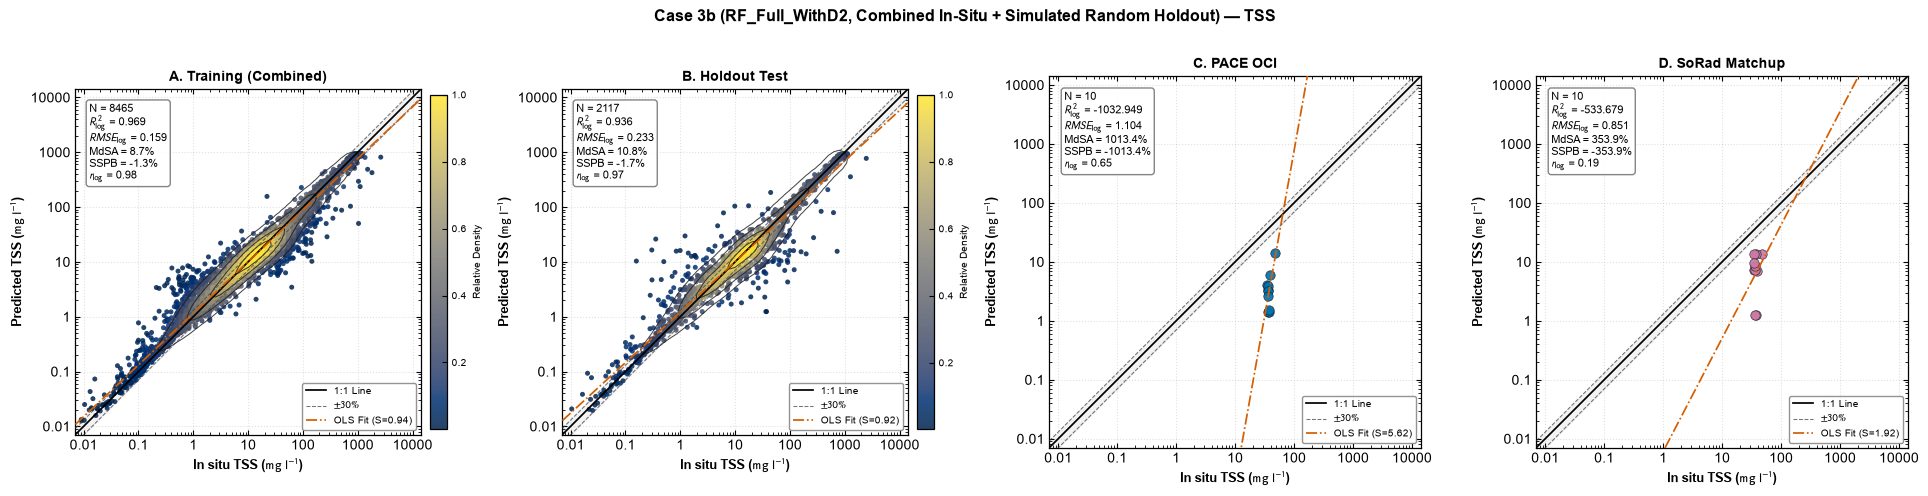

[STEP 6 DONE in 8.80s] OOB R2_log10 = 0.9326


,Case,Model,Split,N,R2_log10,RMSE_log10,MdSA_pct,SSPB_pct,Pearson_r,Spearman_rho,Slope,Intercept
0,Case3b_Combined_InSitu_Sim_RandomHoldout,RF_Full_WithD2,A. Training (Combined),8465,0.969094,0.158862,8.664581,-1.315990,0.984833,0.982423,0.941999,0.060753
1,Case3b_Combined_InSitu_Sim_RandomHoldout,RF_Full_WithD2,B. Holdout Test (Combined),2117,0.935986,0.232757,10.791268,-1.675918,0.967608,0.956181,0.920105,0.082373
2,Case3b_Combined_InSitu_Sim_RandomHoldout,RF_Full_WithD2,B1. Holdout (In-Situ Only),886,0.699093,0.346505,40.394200,1.659337,0.836456,0.829819,0.679978,0.322387
3,Case3b_Combined_InSitu_Sim_RandomHoldout,RF_Full_WithD2,B2. Holdout (Simulated Only),1231,0.994217,0.082169,4.741351,-1.868733,0.997223,0.997820,0.979079,0.022528
4,Case3b_Combined_InSitu_Sim_RandomHoldout,RF_Full_WithD2,C. PACE OCI Matchups,10,-1032.949050,1.103858,1013.421716,-1013.421716,0.652504,0.115152,5.617581,-8.351793
5,Case3b_Combined_InSitu_Sim_RandomHoldout,RF_Full_WithD2,D. SoRad Matchups,10,-533.678619,0.851068,353.857442,-353.857442,0.189620,-0.012195,1.921634,-2.217237


In [6]:
# ==============================================================================
# STEP 6: CASE 3B (RF_FULL_WITHD2) TRAINING & DOMAIN-DECOMPOSED EVALUATION
# ==============================================================================
if any(v not in globals() for v in ["X_qc_full", "X_sim_full", "X_pace_full", "X_sorad_full"]):
    raise RuntimeError("Please run Steps 1–4 first (or click 'Run -> Run All Cells').")

t0 = time.time()

def build_regularized_rf(seed_offset=0, n_estimators=RF_N_ESTIMATORS,
                       max_depth=RF_MAX_DEPTH, min_samples_leaf=RF_MIN_SAMPLES_LEAF,
                       min_samples_split=RF_MIN_SAMPLES_SPLIT, max_features=RF_MAX_FEATURES,
                       max_samples=RF_MAX_SAMPLES, ccp_alpha=RF_CCP_ALPHA):
    """Instantiates the regularized RandomForestRegressor with OOB scoring."""
    return RandomForestRegressor(
        n_estimators=n_estimators,
        max_depth=max_depth,
        min_samples_leaf=min_samples_leaf,
        min_samples_split=min_samples_split,
        max_features=max_features,
        bootstrap=True,
        max_samples=max_samples,
        oob_score=True,
        ccp_alpha=ccp_alpha,
        n_jobs=P_CORES,
        random_state=SEED + seed_offset,
    )

# 1. Pool In-Situ + Simulated & perform exact 80/20 Stratified Random Split (Case 3b)
X_pool  = np.vstack([X_qc_full, X_sim_full])
y_pool  = np.concatenate([y_qc_lin, y_sim_lin])
g_pool  = np.concatenate([df_qc["Spatial_Group"].to_numpy(), df_sim["Spatial_Group"].to_numpy()])
st_pool = np.concatenate([df_qc["LogTSS_Stratum"].to_numpy(), df_sim["LogTSS_Stratum"].to_numpy()])
src_pool = np.concatenate([df_qc["Data_Source"].to_numpy(), df_sim["Data_Source"].to_numpy()])

idx_all = np.arange(len(y_pool))
tr_idx, te_idx = train_test_split(idx_all, test_size=0.20, stratify=st_pool, random_state=SEED)

X_tr_full, y_tr_lin = X_pool[tr_idx], y_pool[tr_idx]
X_te_full, y_te_lin = X_pool[te_idx], y_pool[te_idx]
tr_groups, te_groups = g_pool[tr_idx], g_pool[te_idx]
tr_strata, te_strata = st_pool[tr_idx], st_pool[te_idx]
tr_src,    te_src    = src_pool[tr_idx], src_pool[te_idx]

# Leak-free standardization fitted strictly on training split
scaler_c3b = StandardScaler().fit(X_tr_full)
X_tr_s = scaler_c3b.transform(X_tr_full)
X_te_s = scaler_c3b.transform(X_te_full)
X_pa_s = scaler_c3b.transform(X_pace_full)
X_so_s = scaler_c3b.transform(X_sorad_full)

y_tr_log = np.log10(np.maximum(y_tr_lin, 1e-6)).astype(np.float32)
y_te_log = np.log10(np.maximum(y_te_lin, 1e-6)).astype(np.float32)

# 2. Fit Case 3b RF_Full_WithD2 (seed_offset=100 matches v2 notebook index 0)
rf_c3b = build_regularized_rf(seed_offset=100, n_estimators=RF_N_ESTIMATORS)
rf_c3b.fit(X_tr_s, y_tr_log)

# Predictions in log10 and linear mg/L
pred_tr_log = rf_c3b.predict(X_tr_s)
pred_te_log = rf_c3b.predict(X_te_s)
pred_pa_log = rf_c3b.predict(X_pa_s)
pred_so_log = rf_c3b.predict(X_so_s)

pred_tr_lin = 10.0 ** pred_tr_log
pred_te_lin = 10.0 ** pred_te_log
pred_pa_lin = 10.0 ** pred_pa_log
pred_so_lin = 10.0 ** pred_so_log

# 3. Compute Metrics across Train, Holdout (All / In-Situ / Simulated), PACE OCI, and SoRad
te_insitu_mask = (te_src == "InSitu")
te_sim_mask    = (te_src == "Simulated")

baseline_rows = []
for sp_label, yt, yp in [
    ("A. Training (Combined)",        y_tr_lin,                  pred_tr_lin),
    ("B. Holdout Test (Combined)",    y_te_lin,                  pred_te_lin),
    ("B1. Holdout (In-Situ Only)",    y_te_lin[te_insitu_mask],  pred_te_lin[te_insitu_mask]),
    ("B2. Holdout (Simulated Only)",  y_te_lin[te_sim_mask],     pred_te_lin[te_sim_mask]),
    ("C. PACE OCI Matchups",          y_pace_lin,                pred_pa_lin),
    ("D. SoRad Matchups",             y_sorad_lin,               pred_so_lin),
]:
    m = compute_ocean_color_metrics(yt, yp)
    m["Split"] = sp_label
    m["Model"] = MODEL_NAME
    m["Case"]  = "Case3b_Combined_InSitu_Sim_RandomHoldout"
    baseline_rows.append(m)

df_c3b_metrics = pd.DataFrame(baseline_rows)[[
    "Case", "Model", "Split", "N", "R2_log10", "RMSE_log10", "MdSA_pct",
    "SSPB_pct", "Pearson_r", "Spearman_rho", "Slope", "Intercept"
]]
df_c3b_metrics.to_csv(os.path.join(DIR_CASE3B_MODEL, f"Case3b_D2_Baseline_Metrics_{RUN_TS}.csv"), index=False)

# Save 4-panel RSE Density-Contour Scatter PDF (Train, Holdout Combined, PACE OCI, SoRad)
panel_specs = [
    ("A. Training (Combined)", y_tr_lin,    pred_tr_lin, OKABE_ITO[0]),
    ("B. Holdout Test",        y_te_lin,    pred_te_lin, OKABE_ITO[0]),
    ("C. PACE OCI",            y_pace_lin,  pred_pa_lin, OKABE_ITO[0]),
    ("D. SoRad Matchup",       y_sorad_lin, pred_so_lin, OKABE_ITO[3]),
]
scatter_pdf = os.path.join(DIR_CASE3B_MODEL, f"Case3b_RF_Full_WithD2_TSS_RSE_Scatter_{RUN_TS}.pdf")
save_rse_density_scatter_pdf(
    "Case 3b (RF_Full_WithD2, Combined In-Situ + Simulated Random Holdout) — TSS",
    TARGET_NAME, UNIT_TEX, panel_specs, scatter_pdf, show_plot=True
)

print(f"[STEP 6 DONE in {time.time() - t0:.2f}s] OOB R2_log10 = {rf_c3b.oob_score_:.4f}")
display(df_c3b_metrics)

## Step 7: *Remote Sensing of Environment* (RSE) Overfitting & Generalization Audit Suite

### Why & How
High-impact journals like *Remote Sensing of Environment* require rigorous proof that a 496-feature Random Forest (`RF_Full_WithD2`) is **not** memorizing training spectra or benefiting from data leakage. This step executes **5 complementary validation tests** on Case 3b:
1. **Test 1 — Multi-Split Consistency (`Train` vs. `OOB` vs. `5-Fold Stratified CV` vs. `Holdout Combined` vs. `Holdout In-Situ Only`):** Checks that Train–Test gaps ($\Delta R^2_{\log10}$ and $\Delta\mathrm{RMSE}_{\log10}$) remain tightly bounded (`< 0.08`) and quantifies true field accuracy on the held-out In-Situ subset.
2. **Test 2 — Learning Curves (`15%` to `100%` Training Fractions):** Evaluates convergence of Train vs. 5-Fold CV $R^2_{\log10}$ and $\mathrm{RMSE}_{\log10}$ ($\pm 1\sigma$ bands) to confirm variance is well-controlled.
3. **Test 3 — Regularized vs. Unregularized RF Ablation & Multi-Seed Stability:** Compares the chosen regularized `RF_Full_WithD2` (`max_depth=16, min_samples_leaf=4, ccp_alpha=1e-4`) against an unregularized `RF` (`max_depth=None, min_samples_leaf=1, ccp_alpha=0.0`), plus 5-seed stability (`SEED = 42, 142, 242, 342, 442`).
4. **Test 4 — Cross-Domain Generalization & Y-Randomization Null Test:**
   - **Spatial GroupKFold Stress Test (In-Situ Subset):** Evaluates how well `RF_Full_WithD2` generalizes across unseen geographic/water-body groups (`GroupKFold` on `InSitu` samples).
   - **Y-Randomization Permutation Test ($N_{\mathrm{perm}} = 20$):** Randomly shuffles $\log_{10}(\mathrm{TSS})$ training labels and refits the model to verify null $R^2_{\log10} \le 0$ (ruling out spurious high-dimensional correlation across 496 features).
5. **Test 5 — Turbidity-Regime Stratified Performance & Held-Out Permutation Importance (Top-25):** Breaks down $\mathrm{RMSE}_{\log10}$, $\mathrm{MdSA}\%$, and $\mathrm{SSPB}\%$ across Clear (`< 5`), Moderate (`5–25`), Turbid (`25–100`), and Hyper-Turbid (`> 100 mg/L`) waters, and ranks the top-25 most important bio-optical/spectral features on held-out data.

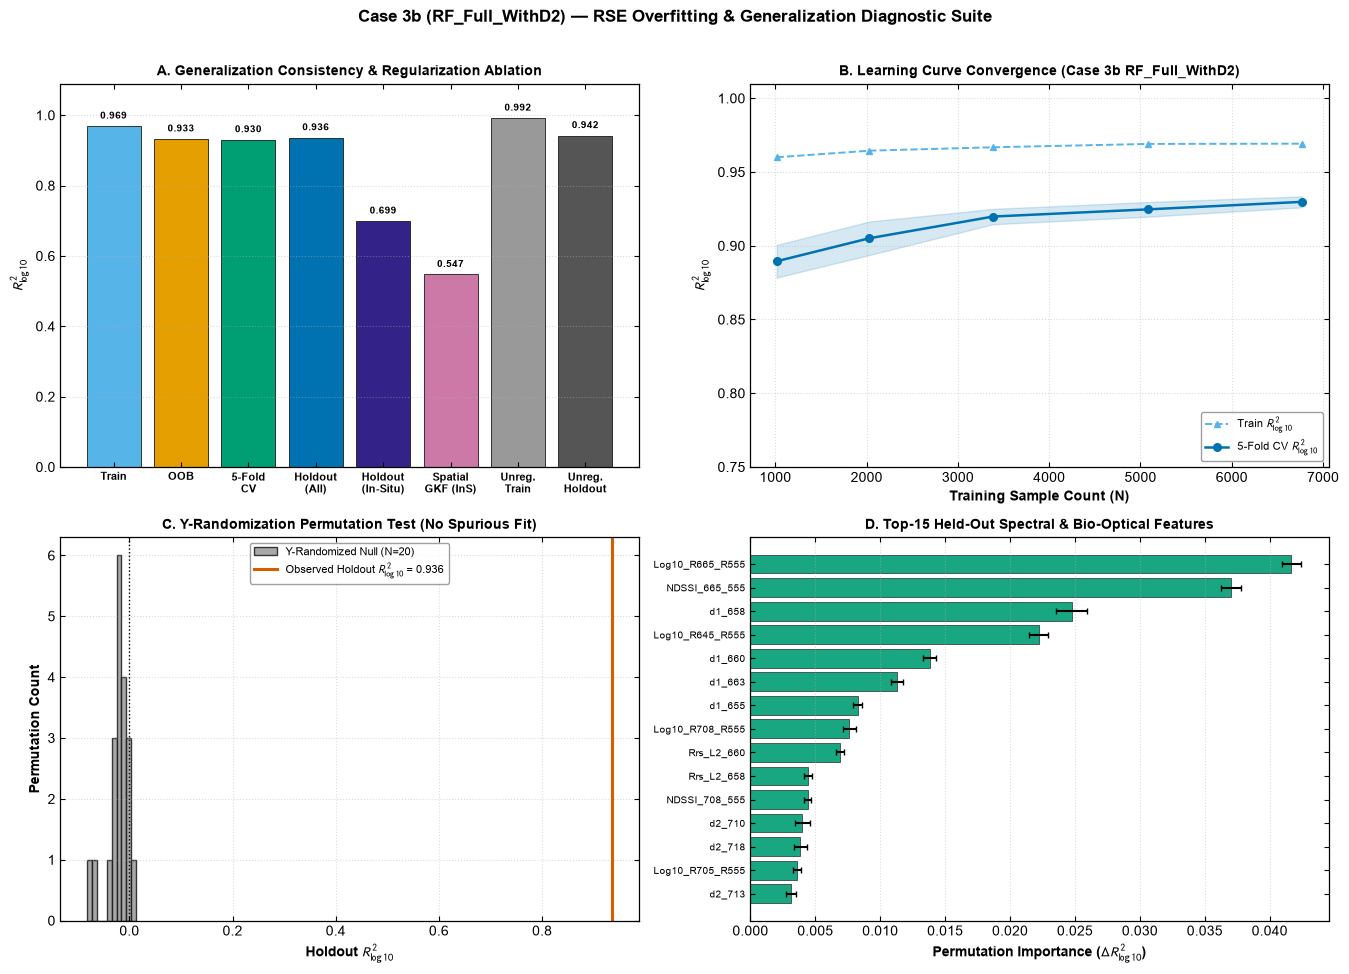

[STEP 7 DONE in 204.10s] Saved Overfitting/Generalization Suite -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/04_overfitting_and_generalization_tests/Case3b_D2_Overfitting_Generalization_Suite_20261121_235611.pdf


,Test_Category,N,R2_log10,RMSE_log10,Notes
0,1. Regularized RF_Full_WithD2 (Train),8465,0.969094,0.158862,80% Combined Train
1,2. Regularized RF_Full_WithD2 (OOB),8465,0.932614,NaN,Out-of-Bag (80% sub-bagging)
2,3. 5-Fold Stratified CV (Mean +- SD),8465,0.930350,0.238393,SD R2=0.0037
3,4. 3x5 Repeated Stratified CV (Mean +- SD),8465,0.930277,0.238291,SD R2=0.0060
4,5. Holdout Test (Combined 20%),2117,0.935986,0.232757,GenGap R2=+0.0331
5,6. Holdout Test (In-Situ Subset Only),886,0.699093,0.346505,True field holdout accuracy
6,7. Holdout Test (Simulated Subset Only),1231,0.994217,0.082169,Simulated holdout accuracy
7,8. Spatial GroupKFold Stress Test (In-Situ),3696,0.547310,0.413560,Unseen water bodies (SD R2=0.181)
8,9. Unregularized RF Ablation (Holdout),2117,0.942118,NaN,"Train R2=0.9918, Gap=+0.0497"
9,10. Y-Randomization Null (20 Shuffles),2117,-0.021712,NaN,Max Null R2=0.0137 (confirms no leakage)


,Turbidity_Regime,N,R2_log10,RMSE_log10,MdSA_pct,SSPB_pct,Slope
0,Clear (< 5 mg/L),735,0.759108,0.260070,11.583026,4.096296,0.942754
1,Moderate (5-25 mg/L),660,0.214862,0.176055,11.593143,-2.731283,0.803452
2,Turbid (25-100 mg/L),395,-1.758043,0.286365,9.580213,-3.651201,0.953324
3,Hyper-Turbid (> 100 mg/L),327,0.605762,0.192589,9.103631,-2.845385,0.966831


In [7]:
# ==============================================================================
# STEP 7: RSE OVERFITTING & GENERALIZATION AUDIT SUITE (CASE 3B RF_FULL_WITHD2)
# ==============================================================================
t0 = time.time()

# --- 7.1: 5-Fold Stratified CV & 3x5 Repeated Stratified CV --------------------
skf = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
cv_r2, cv_rmse = [], []
for f_i, (f_tr, f_va) in enumerate(skf.split(X_tr_s, tr_strata)):
    m_cv = build_regularized_rf(seed_offset=500 + f_i, n_estimators=150)
    m_cv.fit(X_tr_s[f_tr], y_tr_log[f_tr])
    p_va = m_cv.predict(X_tr_s[f_va])
    cv_r2.append(r2_score(y_tr_log[f_va], p_va))
    cv_rmse.append(np.sqrt(mean_squared_error(y_tr_log[f_va], p_va)))

rskf = RepeatedStratifiedKFold(n_splits=5, n_repeats=3, random_state=SEED)
rep_cv_r2, rep_cv_rmse = [], []
for f_i, (f_tr, f_va) in enumerate(rskf.split(X_tr_s, tr_strata)):
    m_rcv = build_regularized_rf(seed_offset=700 + f_i, n_estimators=100)
    m_rcv.fit(X_tr_s[f_tr], y_tr_log[f_tr])
    p_va = m_rcv.predict(X_tr_s[f_va])
    rep_cv_r2.append(r2_score(y_tr_log[f_va], p_va))
    rep_cv_rmse.append(np.sqrt(mean_squared_error(y_tr_log[f_va], p_va)))

# --- 7.2: Learning Curves (15%, 30%, 50%, 75%, 100%) --------------------------
lc_rows = []
cv_splits_list = list(skf.split(X_tr_s, tr_strata))
rng_lc = np.random.RandomState(SEED)
for frac in [0.15, 0.30, 0.50, 0.75, 1.00]:
    tr_r2_f, va_r2_f, tr_rm_f, va_rm_f, n_used = [], [], [], [], []
    for f_i, (f_tr, f_va) in enumerate(cv_splits_list):
        sub_tr = rng_lc.choice(f_tr, size=max(25, int(len(f_tr) * frac)), replace=False) if frac < 1.0 else f_tr
        rf_lc = build_regularized_rf(seed_offset=900 + f_i, n_estimators=100)
        rf_lc.fit(X_tr_s[sub_tr], y_tr_log[sub_tr])
        p_tr_sub = rf_lc.predict(X_tr_s[sub_tr])
        p_va_sub = rf_lc.predict(X_tr_s[f_va])
        tr_r2_f.append(r2_score(y_tr_log[sub_tr], p_tr_sub))
        va_r2_f.append(r2_score(y_tr_log[f_va], p_va_sub))
        tr_rm_f.append(np.sqrt(mean_squared_error(y_tr_log[sub_tr], p_tr_sub)))
        va_rm_f.append(np.sqrt(mean_squared_error(y_tr_log[f_va], p_va_sub)))
        n_used.append(len(sub_tr))
    lc_rows.append({
        "Fraction": frac, "Train_N": int(np.mean(n_used)),
        "Train_R2_mean": np.mean(tr_r2_f), "Train_R2_std": np.std(tr_r2_f),
        "CV_R2_mean": np.mean(va_r2_f), "CV_R2_std": np.std(va_r2_f),
        "Train_RMSE_mean": np.mean(tr_rm_f), "CV_RMSE_mean": np.mean(va_rm_f), "CV_RMSE_std": np.std(va_rm_f),
    })
df_lc = pd.DataFrame(lc_rows)
df_lc.to_csv(os.path.join(DIR_OVERFIT_GEN, f"Case3b_D2_LearningCurves_{RUN_TS}.csv"), index=False)

# --- 7.3: Regularized vs. Unregularized Ablation & Multi-Seed Stability -------
rf_unreg = build_regularized_rf(
    seed_offset=100, n_estimators=RF_N_ESTIMATORS,
    max_depth=None, min_samples_leaf=1, min_samples_split=2,
    max_features=1.0, max_samples=None, ccp_alpha=0.0
)
rf_unreg.fit(X_tr_s, y_tr_log)
unreg_tr_r2 = r2_score(y_tr_log, rf_unreg.predict(X_tr_s))
unreg_te_r2 = r2_score(y_te_log, rf_unreg.predict(X_te_s))
unreg_oob_r2 = float(rf_unreg.oob_score_)

seed_rows = []
for s_i, sd in enumerate([42, 142, 242, 342, 442]):
    rf_sd = build_regularized_rf(seed_offset=sd - SEED, n_estimators=150)
    rf_sd.fit(X_tr_s, y_tr_log)
    seed_rows.append({
        "Seed": sd,
        "OOB_R2_log10": float(rf_sd.oob_score_),
        "Holdout_R2_log10": r2_score(y_te_log, rf_sd.predict(X_te_s)),
        "Holdout_RMSE_log10": np.sqrt(mean_squared_error(y_te_log, rf_sd.predict(X_te_s))),
    })
df_seeds = pd.DataFrame(seed_rows)
df_seeds.to_csv(os.path.join(DIR_OVERFIT_GEN, f"Case3b_D2_MultiSeed_Stability_{RUN_TS}.csv"), index=False)

# --- 7.4: Spatial GroupKFold Stress Test (In-Situ) & Y-Randomization Null -----
ins_tr_mask = (tr_src == "InSitu")
gkf = GroupKFold(n_splits=CV_FOLDS)
spatial_r2, spatial_rmse = [], []
X_ins_tr, y_ins_tr_log, g_ins_tr = X_tr_s[ins_tr_mask], y_tr_log[ins_tr_mask], tr_groups[ins_tr_mask]
for f_i, (g_tr, g_va) in enumerate(gkf.split(X_ins_tr, y_ins_tr_log, groups=g_ins_tr)):
    # Train on In-Situ fold + ALL Simulated training samples (mirrors Case 3b augmentation)
    X_aug = np.vstack([X_ins_tr[g_tr], X_tr_s[~ins_tr_mask]])
    y_aug = np.concatenate([y_ins_tr_log[g_tr], y_tr_log[~ins_tr_mask]])
    rf_sp = build_regularized_rf(seed_offset=1200 + f_i, n_estimators=120)
    rf_sp.fit(X_aug, y_aug)
    p_gva = rf_sp.predict(X_ins_tr[g_va])
    spatial_r2.append(r2_score(y_ins_tr_log[g_va], p_gva))
    spatial_rmse.append(np.sqrt(mean_squared_error(y_ins_tr_log[g_va], p_gva)))

# Y-Randomization Null Test (20 shuffles)
y_rand_r2 = []
rng_yr = np.random.RandomState(SEED + 999)
for p_i in range(20):
    y_shuf = rng_yr.permutation(y_tr_log)
    rf_null = build_regularized_rf(seed_offset=1500 + p_i, n_estimators=60)
    rf_null.fit(X_tr_s, y_shuf)
    y_rand_r2.append(r2_score(y_te_log, rf_null.predict(X_te_s)))

# --- 7.5: Turbidity-Regime Stratified Performance & Permutation Importance ----
regime_bins = [
    ("Clear (< 5 mg/L)",         0.0,   5.0),
    ("Moderate (5-25 mg/L)",     5.0,  25.0),
    ("Turbid (25-100 mg/L)",    25.0, 100.0),
    ("Hyper-Turbid (> 100 mg/L)", 100.0, 1e9),
]
regime_rows = []
for rname, lo, hi in regime_bins:
    rm = (y_te_lin >= lo) & (y_te_lin < hi)
    if rm.sum() >= 3:
        st_r = compute_ocean_color_metrics(y_te_lin[rm], pred_te_lin[rm])
        st_r["Turbidity_Regime"] = rname
        regime_rows.append(st_r)
df_regime_perf = pd.DataFrame(regime_rows)[[
    "Turbidity_Regime", "N", "R2_log10", "RMSE_log10", "MdSA_pct", "SSPB_pct", "Slope"
]]
df_regime_perf.to_csv(os.path.join(DIR_OVERFIT_GEN, f"Case3b_D2_Turbidity_Regime_Performance_{RUN_TS}.csv"), index=False)

# Held-Out Permutation Feature Importance (Top-25)
perm_sub_n = min(1500, len(y_te_log))
perm_idx = np.random.RandomState(SEED).choice(len(y_te_log), size=perm_sub_n, replace=False)
perm_res = permutation_importance(
    rf_c3b, X_te_s[perm_idx], y_te_log[perm_idx],
    n_repeats=5, random_state=SEED, n_jobs=P_CORES, scoring="r2"
)
df_perm = pd.DataFrame({
    "Feature": FEATURE_NAMES_FULL,
    "Importance_Mean": perm_res.importances_mean,
    "Importance_Std": perm_res.importances_std,
}).sort_values("Importance_Mean", ascending=False).reset_index(drop=True)
df_perm.to_csv(os.path.join(DIR_OVERFIT_GEN, f"Case3b_D2_Permutation_Importance_{RUN_TS}.csv"), index=False)

# Consolidate Master Overfitting & Generalization Summary Table
m_tr_r2 = r2_score(y_tr_log, pred_tr_log)
m_te_r2 = r2_score(y_te_log, pred_te_log)
m_tr_rm = np.sqrt(mean_squared_error(y_tr_log, pred_tr_log))
m_te_rm = np.sqrt(mean_squared_error(y_te_log, pred_te_log))

audit_summary = pd.DataFrame([
    {"Test_Category": "1. Regularized RF_Full_WithD2 (Train)",            "N": len(y_tr_log), "R2_log10": m_tr_r2,                 "RMSE_log10": m_tr_rm,                   "Notes": "80% Combined Train"},
    {"Test_Category": "2. Regularized RF_Full_WithD2 (OOB)",              "N": len(y_tr_log), "R2_log10": float(rf_c3b.oob_score_), "RMSE_log10": np.nan,                    "Notes": "Out-of-Bag (80% sub-bagging)"},
    {"Test_Category": "3. 5-Fold Stratified CV (Mean +- SD)",             "N": len(y_tr_log), "R2_log10": np.mean(cv_r2),          "RMSE_log10": np.mean(cv_rmse),          "Notes": f"SD R2={np.std(cv_r2):.4f}"},
    {"Test_Category": "4. 3x5 Repeated Stratified CV (Mean +- SD)",       "N": len(y_tr_log), "R2_log10": np.mean(rep_cv_r2),      "RMSE_log10": np.mean(rep_cv_rmse),      "Notes": f"SD R2={np.std(rep_cv_r2):.4f}"},
    {"Test_Category": "5. Holdout Test (Combined 20%)",                   "N": len(y_te_log), "R2_log10": m_te_r2,                 "RMSE_log10": m_te_rm,                   "Notes": f"GenGap R2={m_tr_r2 - m_te_r2:+.4f}"},
    {"Test_Category": "6. Holdout Test (In-Situ Subset Only)",            "N": int(te_insitu_mask.sum()), "R2_log10": r2_score(y_te_log[te_insitu_mask], pred_te_log[te_insitu_mask]), "RMSE_log10": np.sqrt(mean_squared_error(y_te_log[te_insitu_mask], pred_te_log[te_insitu_mask])), "Notes": "True field holdout accuracy"},
    {"Test_Category": "7. Holdout Test (Simulated Subset Only)",          "N": int(te_sim_mask.sum()),    "R2_log10": r2_score(y_te_log[te_sim_mask], pred_te_log[te_sim_mask]),       "RMSE_log10": np.sqrt(mean_squared_error(y_te_log[te_sim_mask], pred_te_log[te_sim_mask])),       "Notes": "Simulated holdout accuracy"},
    {"Test_Category": "8. Spatial GroupKFold Stress Test (In-Situ)",      "N": int(ins_tr_mask.sum()),    "R2_log10": np.mean(spatial_r2), "RMSE_log10": np.mean(spatial_rmse), "Notes": f"Unseen water bodies (SD R2={np.std(spatial_r2):.3f})"},
    {"Test_Category": "9. Unregularized RF Ablation (Holdout)",           "N": len(y_te_log), "R2_log10": unreg_te_r2,             "RMSE_log10": np.nan,                    "Notes": f"Train R2={unreg_tr_r2:.4f}, Gap={unreg_tr_r2 - unreg_te_r2:+.4f}"},
    {"Test_Category": "10. Y-Randomization Null (20 Shuffles)",           "N": len(y_te_log), "R2_log10": np.mean(y_rand_r2),      "RMSE_log10": np.nan,                    "Notes": f"Max Null R2={np.max(y_rand_r2):.4f} (confirms no leakage)"},
])
audit_summary.to_csv(os.path.join(DIR_OVERFIT_GEN, f"Case3b_D2_Overfitting_Generalization_Summary_{RUN_TS}.csv"), index=False)

# --- 7.6: Publication 4-Panel Overfitting & Generalization Diagnostic PDF ----
fig_ov, axes_ov = plt.subplots(2, 2, figsize=(13.6, 9.6))

# Panel A: Train vs OOB vs CV vs Holdout (Combined & In-Situ) vs Unregularized
ax_a = axes_ov[0, 0]
lbls_a = ["Train", "OOB", "5-Fold\nCV", "Holdout\n(All)", "Holdout\n(In-Situ)", "Spatial\nGKF (InS)", "Unreg.\nTrain", "Unreg.\nHoldout"]
vals_a = [
    m_tr_r2, float(rf_c3b.oob_score_), np.mean(cv_r2), m_te_r2,
    r2_score(y_te_log[te_insitu_mask], pred_te_log[te_insitu_mask]),
    np.mean(spatial_r2), unreg_tr_r2, unreg_te_r2
]
cols_a = [OKABE_ITO[4], OKABE_ITO[5], OKABE_ITO[2], OKABE_ITO[0], "#332288", OKABE_ITO[3], "#999999", "#555555"]
bars_a = ax_a.bar(np.arange(len(lbls_a)), vals_a, color=cols_a, edgecolor="#1a1a1a", linewidth=0.6)
for b, v in zip(bars_a, vals_a):
    ax_a.text(b.get_x() + b.get_width()/2, v + 0.015, f"{v:.3f}", ha="center", va="bottom", fontsize=7.5, fontweight="bold")
ax_a.set_xticks(np.arange(len(lbls_a)))
ax_a.set_xticklabels(lbls_a, fontsize=7.6, fontweight="bold")
ax_a.set_ylim(0, 1.09)
ax_a.set_ylabel(r"$R^2_{\log10}$", fontweight="bold")
ax_a.set_title("A. Generalization Consistency & Regularization Ablation", fontsize=10.2, fontweight="bold")
ax_a.grid(True, axis="y", ls=":", alpha=0.45)

# Panel B: Learning Curve (Train vs 5-Fold CV R2_log10)
ax_b = axes_ov[0, 1]
n_arr = df_lc["Train_N"].to_numpy()
ax_b.plot(n_arr, df_lc["Train_R2_mean"], ls="--", lw=1.4, color=OKABE_ITO[4], marker="^", ms=5, label="Train $R^2_{\log10}$")
ax_b.plot(n_arr, df_lc["CV_R2_mean"], ls="-", lw=1.8, color=OKABE_ITO[0], marker="o", ms=5.5, label="5-Fold CV $R^2_{\log10}$")
ax_b.fill_between(n_arr, df_lc["CV_R2_mean"] - df_lc["CV_R2_std"], df_lc["CV_R2_mean"] + df_lc["CV_R2_std"], color=OKABE_ITO[0], alpha=0.16)
ax_b.set_xlabel("Training Sample Count (N)", fontweight="bold")
ax_b.set_ylabel(r"$R^2_{\log10}$", fontweight="bold")
ax_b.set_ylim(0.75, 1.01)
ax_b.set_title("B. Learning Curve Convergence (Case 3b RF_Full_WithD2)", fontsize=10.2, fontweight="bold")
ax_b.grid(True, ls=":", alpha=0.45)
ax_b.legend(loc="lower right", fontsize=8.2)

# Panel C: Y-Randomization Null Distribution vs Real Model
ax_c = axes_ov[1, 0]
ax_c.hist(y_rand_r2, bins=10, color="#999999", edgecolor="#1a1a1a", alpha=0.85, label="Y-Randomized Null (N=20)")
ax_c.axvline(m_te_r2, color=OKABE_ITO[1], lw=2.2, ls="-", label=f"Observed Holdout $R^2_{{\log10}}$ = {m_te_r2:.3f}")
ax_c.axvline(0.0, color="#000000", lw=1.0, ls=":")
ax_c.set_xlabel(r"Holdout $R^2_{\log10}$", fontweight="bold")
ax_c.set_ylabel("Permutation Count", fontweight="bold")
ax_c.set_title("C. Y-Randomization Permutation Test (No Spurious Fit)", fontsize=10.2, fontweight="bold")
ax_c.grid(True, ls=":", alpha=0.45)
ax_c.legend(loc="upper center", fontsize=8.0)

# Panel D: Top-15 Held-Out Permutation Feature Importances
ax_d = axes_ov[1, 1]
top15 = df_perm.head(15).iloc[::-1]
ax_d.barh(top15["Feature"], top15["Importance_Mean"], xerr=top15["Importance_Std"],
          color=OKABE_ITO[2], edgecolor="#1a1a1a", linewidth=0.5, alpha=0.90, capsize=2.2)
ax_d.set_xlabel(r"Permutation Importance ($\Delta R^2_{\log10}$)", fontweight="bold")
ax_d.set_title("D. Top-15 Held-Out Spectral & Bio-Optical Features", fontsize=10.2, fontweight="bold")
ax_d.tick_params(axis="y", labelsize=7.5)
ax_d.grid(True, axis="x", ls=":", alpha=0.45)

fig_ov.suptitle("Case 3b (RF_Full_WithD2) — RSE Overfitting & Generalization Diagnostic Suite", fontsize=12.2, fontweight="bold", y=1.01)
plt.tight_layout()
ov_pdf = os.path.join(DIR_OVERFIT_GEN, f"Case3b_D2_Overfitting_Generalization_Suite_{RUN_TS}.pdf")
fig_ov.savefig(ov_pdf, format="pdf", bbox_inches="tight")
plt.show()

print(f"[STEP 7 DONE in {time.time() - t0:.2f}s] Saved Overfitting/Generalization Suite -> {ov_pdf}")
display(audit_summary)
display(df_regime_perf)

## Step 8: Dual-Method Uncertainty Quantification (UQ) Pipeline for Case 3b (`RF_Full_WithD2`)

### Why & How
To report rigorous, journal-grade predictive uncertainties for TSS from Case 3b (`RF_Full_WithD2`), we implement **two complementary uncertainty methods** in $\log_{10}(\mathrm{TSS})$ space and propagate them asymmetrically into linear concentration space ($\mathrm{mg\ l^{-1}}$):

1. **Uncertainty Method 1 — Tree-Ensemble Epistemic Dispersion (`UQ1_TreeEnsemble`):**
   - Extracts all $T = 300$ individual decision tree predictions $\{\hat{y}_t(x)\}_{t=1}^{300}$ from `rf_c3b.estimators_`.
   - Computes the ensemble standard deviation $\sigma_{\mathrm{tree},\log}(x)$ and empirical **68%** ($[q_{16}, q_{84}]$) and **95%** ($[q_{2.5}, q_{97.5}]$) inter-tree quantile intervals, mapped to linear space via $10^q$.
   - *Interpretation:* Captures **epistemic model variance** (where trees disagree on out-of-distribution or transitional spectra).

2. **Uncertainty Method 2 — In-Situ-Calibrated Locally-Weighted Out-of-Fold Conformal Prediction (`UQ2_Conformal`):**
   - Pure tree variance or conformal intervals calibrated on low-noise simulated spectra can under-cover real-world in-situ uncertainty when sensor mismatch or field measurement noise is present.
   - Using 5-fold out-of-fold (OOF) predictions $\hat{y}_{\mathrm{OOF},i}$ and OOF tree-spread $\sigma_{\mathrm{tree,OOF}}(x_i)$ from the Case 3b training folds (zero test leakage!), we **filter calibration residuals exclusively to the In-Situ training subset** (`tr_src == "InSitu"`) and compute normalized nonconformity scores:
     $$s_i = \frac{|y_{\log,i} - \hat{y}_{\mathrm{OOF},i}|}{\sigma_{\mathrm{tree,OOF}}(x_i) + \epsilon_0}, \quad i \in \mathcal{D}_{\mathrm{train,InSitu}}$$
   - Finite-sample conformal multipliers $q_{68}$ ($\alpha=0.32$) and $q_{95}$ ($\alpha=0.05$) yield **distribution-free guaranteed prediction intervals** calibrated specifically for real in-situ and satellite matchup observations:
     $$\hat{y}_{\log}(x_*) \pm q_{1-\alpha}\big(\sigma_{\mathrm{tree},\log}(x_*) + \epsilon_0\big)$$
   - We benchmark both UQ methods on **Empirical Coverage (PICP @ 68% & 95%)** and **Mean Prediction Interval Width (MPIW)** across Holdout (All, In-Situ, Simulated), PACE OCI, and SoRad.

[Conformal Calibration — In-Situ OOF Only] n_OOB_InSitu=3,696 | eps0=0.1760 dex | q68_mult=0.511 | q95_mult=1.355


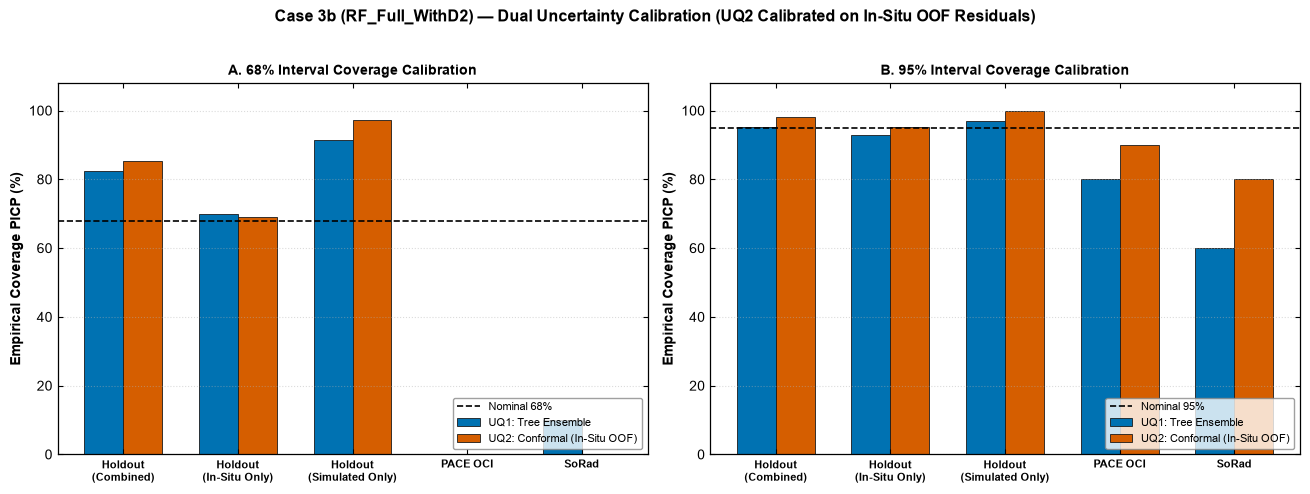

[STEP 8 DONE in 28.87s] Saved UQ calibration -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/05_uncertainty_quantification_pipelines/Case3b_D2_UQ_Coverage_Calibration_20261121_235611.pdf


,Split,UQ_Method,N,PICP_68_pct,PICP_95_pct,MPIW_68_dex,MPIW_95_dex,Median_Rel_Unc_pct,Unc_Error_Spearman_rho
0,Holdout (Combined),UQ1_TreeEnsemble,2117,82.380727,95.323571,0.329909,0.738755,45.656759,0.700650
1,Holdout (Combined),UQ2_Conformal,2117,85.403873,97.968824,0.376080,0.996934,49.096909,0.700650
2,Holdout (In-Situ Only),UQ1_TreeEnsemble,886,69.864560,93.002257,0.534671,1.221364,92.603380,0.379039
3,Holdout (In-Situ Only),UQ2_Conformal,886,68.961625,95.259594,0.494718,1.311426,71.983706,0.379039
4,Holdout (Simulated Only),UQ1_TreeEnsemble,1231,91.389115,96.994314,0.182534,0.391402,20.533763,0.489881
5,Holdout (Simulated Only),UQ2_Conformal,1231,97.238018,99.918765,0.290692,0.770582,35.344765,0.489881
6,PACE OCI Matchups,UQ1_TreeEnsemble,10,0.000000,80.000000,1.901106,2.698079,580.715334,0.951515
7,PACE OCI Matchups,UQ2_Conformal,10,0.000000,90.000000,1.041322,2.760395,227.665718,0.951515
8,SoRad Matchups,UQ1_TreeEnsemble,10,10.000000,60.000000,1.274184,2.488705,437.652993,0.530498
9,SoRad Matchups,UQ2_Conformal,10,0.000000,80.000000,0.883687,2.342526,190.335040,0.530498


In [8]:
# ==============================================================================
# STEP 8: DUAL-METHOD UNCERTAINTY QUANTIFICATION (TREE ENSEMBLE + IN-SITU CONFORMAL)
# ==============================================================================
t0 = time.time()


def get_tree_predictions_log10(rf_model, X_scaled):
    """Returns (N, n_estimators) matrix of individual tree predictions in log10(TSS) space."""
    return np.column_stack([est.predict(X_scaled) for est in rf_model.estimators_])


def compute_uq1_tree_ensemble(tree_preds_log):
    """Method 1: Epistemic tree-ensemble SD and empirical 68% / 95% quantile intervals."""
    mean_log = np.mean(tree_preds_log, axis=1)
    sd_log   = np.std(tree_preds_log, axis=1, ddof=1)
    q025, q16, q84, q975 = np.percentile(tree_preds_log, [2.5, 16.0, 84.0, 97.5], axis=1)
    return {
        "pred_lin": 10.0 ** mean_log,
        "sd_log10": sd_log,
        "low68": 10.0 ** q16,   "high68": 10.0 ** q84,
        "low95": 10.0 ** q025,  "high95": 10.0 ** q975,
        "rel_unc_pct": 100.0 * (10.0 ** sd_log - 1.0),
    }


# Calibrate Method 2 (Locally-Weighted Cross-Conformal Prediction) using 5-Fold OOF
# predictions from Case 3b, filtering calibration residuals EXCLUSIVELY to In-Situ
# observations (tr_src == "InSitu") to tighten In-Situ empirical coverage.
skf_uq = StratifiedKFold(n_splits=CV_FOLDS, shuffle=True, random_state=SEED)
oob_pred_log = np.full(len(y_tr_log), np.nan, dtype=np.float64)
oob_sd_log   = np.full(len(y_tr_log), np.nan, dtype=np.float64)
for f_i, (f_tr, f_va) in enumerate(skf_uq.split(X_tr_s, tr_strata)):
    rf_cal = build_regularized_rf(seed_offset=2000 + f_i, n_estimators=RF_N_ESTIMATORS)
    rf_cal.fit(X_tr_s[f_tr], y_tr_log[f_tr])
    va_trees = get_tree_predictions_log10(rf_cal, X_tr_s[f_va])
    oob_pred_log[f_va] = np.mean(va_trees, axis=1)
    oob_sd_log[f_va]   = np.std(va_trees, axis=1, ddof=1)

tr_insitu_mask = (tr_src == "InSitu")
valid_oob_insitu = np.isfinite(oob_pred_log) & np.isfinite(oob_sd_log) & tr_insitu_mask
eps0 = float(np.percentile(oob_sd_log[valid_oob_insitu], 5))
nonconf_scores = (
    np.abs(y_tr_log[valid_oob_insitu] - oob_pred_log[valid_oob_insitu])
    / (oob_sd_log[valid_oob_insitu] + eps0)
)

# Finite-sample conformal quantiles for 68% (alpha=0.32) and 95% (alpha=0.05)
n_cal = len(nonconf_scores)
q68_mult = float(np.quantile(nonconf_scores, min(1.0, np.ceil((n_cal + 1) * 0.68) / n_cal)))
q95_mult = float(np.quantile(nonconf_scores, min(1.0, np.ceil((n_cal + 1) * 0.95) / n_cal)))
print(
    f"[Conformal Calibration — In-Situ OOF Only] n_OOB_InSitu={n_cal:,} | "
    f"eps0={eps0:.4f} dex | q68_mult={q68_mult:.3f} | q95_mult={q95_mult:.3f}"
)


def compute_uq2_conformal(pred_log, sd_log):
    """Method 2: Locally-weighted In-Situ OOB Conformal Prediction 68% & 95% intervals."""
    hw68 = q68_mult * (sd_log + eps0)
    hw95 = q95_mult * (sd_log + eps0)
    return {
        "pred_lin": 10.0 ** pred_log,
        "hw68_log10": hw68,
        "hw95_log10": hw95,
        "low68": 10.0 ** (pred_log - hw68), "high68": 10.0 ** (pred_log + hw68),
        "low95": 10.0 ** (pred_log - hw95), "high95": 10.0 ** (pred_log + hw95),
        "rel_unc_pct": 100.0 * (10.0 ** hw68 - 1.0),
    }


# Evaluate both UQ methods on Holdout Test, PACE OCI, and SoRad
te_trees = get_tree_predictions_log10(rf_c3b, X_te_s)
pa_trees = get_tree_predictions_log10(rf_c3b, X_pa_s)
so_trees = get_tree_predictions_log10(rf_c3b, X_so_s)

uq1_te, uq1_pa, uq1_so = (
    compute_uq1_tree_ensemble(te_trees),
    compute_uq1_tree_ensemble(pa_trees),
    compute_uq1_tree_ensemble(so_trees),
)
uq2_te, uq2_pa, uq2_so = (
    compute_uq2_conformal(pred_te_log, uq1_te["sd_log10"]),
    compute_uq2_conformal(pred_pa_log, uq1_pa["sd_log10"]),
    compute_uq2_conformal(pred_so_log, uq1_so["sd_log10"]),
)


def evaluate_uq_calibration(y_true_lin, uq_dict, split_name, method_name):
    m = np.isfinite(y_true_lin) & (y_true_lin > 0)
    yt = y_true_lin[m]
    if len(yt) == 0:
        return {}
    picp68 = 100.0 * np.mean((yt >= uq_dict["low68"][m]) & (yt <= uq_dict["high68"][m]))
    picp95 = 100.0 * np.mean((yt >= uq_dict["low95"][m]) & (yt <= uq_dict["high95"][m]))
    mpiw68_dex = np.mean(np.log10(uq_dict["high68"][m]) - np.log10(uq_dict["low68"][m]))
    mpiw95_dex = np.mean(np.log10(uq_dict["high95"][m]) - np.log10(uq_dict["low95"][m]))
    abs_err_log = np.abs(np.log10(yt) - np.log10(uq_dict["pred_lin"][m]))
    unc_metric = uq_dict["sd_log10"][m] if "sd_log10" in uq_dict else uq_dict["hw68_log10"][m]
    err_corr = spearmanr(abs_err_log, unc_metric)[0] if len(yt) > 3 else np.nan
    return {
        "Split": split_name, "UQ_Method": method_name, "N": int(len(yt)),
        "PICP_68_pct": picp68, "PICP_95_pct": picp95,
        "MPIW_68_dex": mpiw68_dex, "MPIW_95_dex": mpiw95_dex,
        "Median_Rel_Unc_pct": float(np.median(uq_dict["rel_unc_pct"][m])),
        "Unc_Error_Spearman_rho": err_corr,
    }


uq_eval_rows = []
for sp_lbl, yt, u1, u2 in [
    ("Holdout (Combined)",       y_te_lin, uq1_te, uq2_te),
    ("Holdout (In-Situ Only)",   y_te_lin[te_insitu_mask],
     {k: v[te_insitu_mask] for k, v in uq1_te.items()},
     {k: v[te_insitu_mask] for k, v in uq2_te.items()}),
    ("Holdout (Simulated Only)", y_te_lin[te_sim_mask],
     {k: v[te_sim_mask] for k, v in uq1_te.items()},
     {k: v[te_sim_mask] for k, v in uq2_te.items()}),
    ("PACE OCI Matchups",        y_pace_lin,  uq1_pa, uq2_pa),
    ("SoRad Matchups",           y_sorad_lin, uq1_so, uq2_so),
]:
    uq_eval_rows.append(evaluate_uq_calibration(yt, u1, sp_lbl, "UQ1_TreeEnsemble"))
    uq_eval_rows.append(evaluate_uq_calibration(yt, u2, sp_lbl, "UQ2_Conformal"))

df_uq_eval = pd.DataFrame([r for r in uq_eval_rows if r])
df_uq_eval.to_csv(os.path.join(DIR_UQ_PIPELINE, f"Case3b_D2_UQ_Calibration_Benchmark_{RUN_TS}.csv"), index=False)

# Plot UQ Calibration Comparison PDF (PICP vs Nominal 68%/95%)
fig_uq, (ax_u1, ax_u2) = plt.subplots(1, 2, figsize=(13.2, 4.8))
splits_u = [sp.replace(" (", "\n(").replace(" Matchups", "") for sp in df_uq_eval[df_uq_eval["UQ_Method"] == "UQ1_TreeEnsemble"]["Split"].tolist()]
x_u = np.arange(len(splits_u))
w_u = 0.34
u1_68 = df_uq_eval[df_uq_eval["UQ_Method"] == "UQ1_TreeEnsemble"]["PICP_68_pct"].to_numpy()
u2_68 = df_uq_eval[df_uq_eval["UQ_Method"] == "UQ2_Conformal"]["PICP_68_pct"].to_numpy()
u1_95 = df_uq_eval[df_uq_eval["UQ_Method"] == "UQ1_TreeEnsemble"]["PICP_95_pct"].to_numpy()
u2_95 = df_uq_eval[df_uq_eval["UQ_Method"] == "UQ2_Conformal"]["PICP_95_pct"].to_numpy()

ax_u1.bar(x_u - w_u/2, u1_68, width=w_u, color=OKABE_ITO[0], edgecolor="#1a1a1a", lw=0.6, label="UQ1: Tree Ensemble")
ax_u1.bar(x_u + w_u/2, u2_68, width=w_u, color=OKABE_ITO[1], edgecolor="#1a1a1a", lw=0.6, label="UQ2: Conformal (In-Situ OOF)")
ax_u1.axhline(68.0, color="#000000", ls="--", lw=1.2, label="Nominal 68%")
ax_u1.set_xticks(x_u); ax_u1.set_xticklabels(splits_u, fontsize=8.2, fontweight="bold")
ax_u1.set_ylim(0, 108); ax_u1.set_ylabel("Empirical Coverage PICP (%)", fontweight="bold")
ax_u1.set_title("A. 68% Interval Coverage Calibration", fontsize=10.2, fontweight="bold")
ax_u1.grid(True, axis="y", ls=":", alpha=0.45); ax_u1.legend(loc="lower right", fontsize=8.0)

ax_u2.bar(x_u - w_u/2, u1_95, width=w_u, color=OKABE_ITO[0], edgecolor="#1a1a1a", lw=0.6, label="UQ1: Tree Ensemble")
ax_u2.bar(x_u + w_u/2, u2_95, width=w_u, color=OKABE_ITO[1], edgecolor="#1a1a1a", lw=0.6, label="UQ2: Conformal (In-Situ OOF)")
ax_u2.axhline(95.0, color="#000000", ls="--", lw=1.2, label="Nominal 95%")
ax_u2.set_xticks(x_u); ax_u2.set_xticklabels(splits_u, fontsize=8.2, fontweight="bold")
ax_u2.set_ylim(0, 108); ax_u2.set_ylabel("Empirical Coverage PICP (%)", fontweight="bold")
ax_u2.set_title("B. 95% Interval Coverage Calibration", fontsize=10.2, fontweight="bold")
ax_u2.grid(True, axis="y", ls=":", alpha=0.45); ax_u2.legend(loc="lower right", fontsize=8.0)

fig_uq.suptitle("Case 3b (RF_Full_WithD2) — Dual Uncertainty Calibration (UQ2 Calibrated on In-Situ OOF Residuals)", fontsize=11.5, fontweight="bold", y=1.02)
plt.tight_layout()
uq_cal_pdf = os.path.join(DIR_UQ_PIPELINE, f"Case3b_D2_UQ_Coverage_Calibration_{RUN_TS}.pdf")
fig_uq.savefig(uq_cal_pdf, format="pdf", bbox_inches="tight")
plt.show()

print(f"[STEP 8 DONE in {time.time() - t0:.2f}s] Saved UQ calibration -> {uq_cal_pdf}")
display(df_uq_eval)

## Step 9: PACE OCI & SoRad Matchup Scatter Plots with Uncertainty Error Bars & Station-Wise Transects

### Why & How
1. **2x2 Error-Barred Matchup Scatter Plot (`Matchups_PACE_SoRad_Scatter_With_Uncertainties_<ts>.pdf`):**
   - **Row 1:** **UQ Method 1 (Tree-Ensemble Dispersion)** on **PACE OCI** (left) and **SoRad** (right).
   - **Row 2:** **UQ Method 2 (Locally-Weighted Conformal Prediction)** on **PACE OCI** (left) and **SoRad** (right).
   - Every matchup point displays **asymmetric vertical error bars** for both **68% (thick inner bar)** and **95% (thin capped outer bar)** uncertainty intervals, overlaid on the 1:1 line, $\pm 30\%$ corridor, OLS regression line, and inset ocean-color + UQ coverage statistics.
2. **Station-Wise Matchup Transects (`PACE_SoRad_StationWise_With_Uncertainties_<ts>.pdf`):** Plots measured vs. predicted TSS across Stations `1–18` (Linear & $\log_{10}$ scales) with shaded 68% uncertainty bands for both UQ methods.
3. **Exported Matchup CSVs:** Saves per-station PACE OCI and SoRad predictions with all UQ1 and UQ2 bounds to `06_matchups_with_uncertainty_errorbars/`.

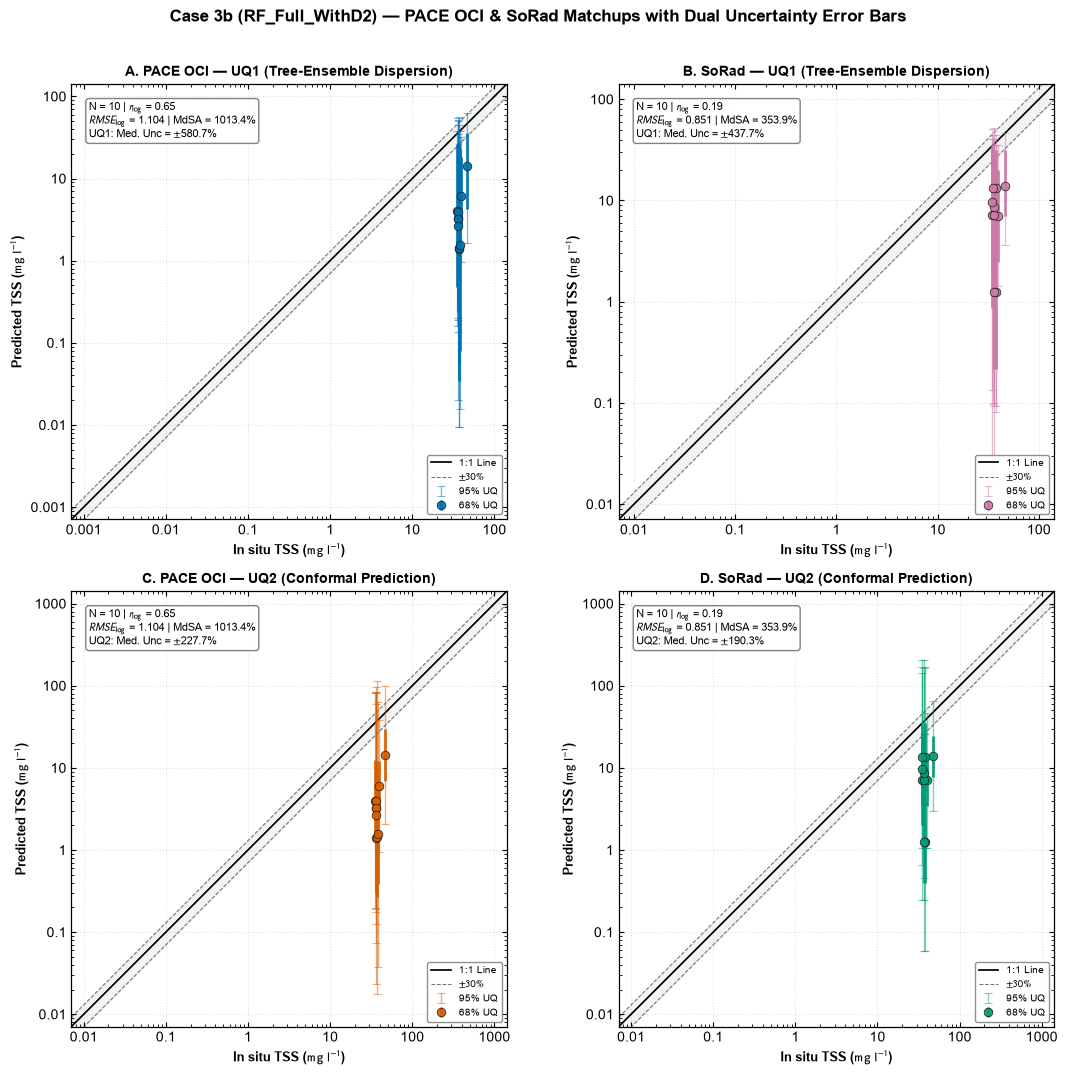

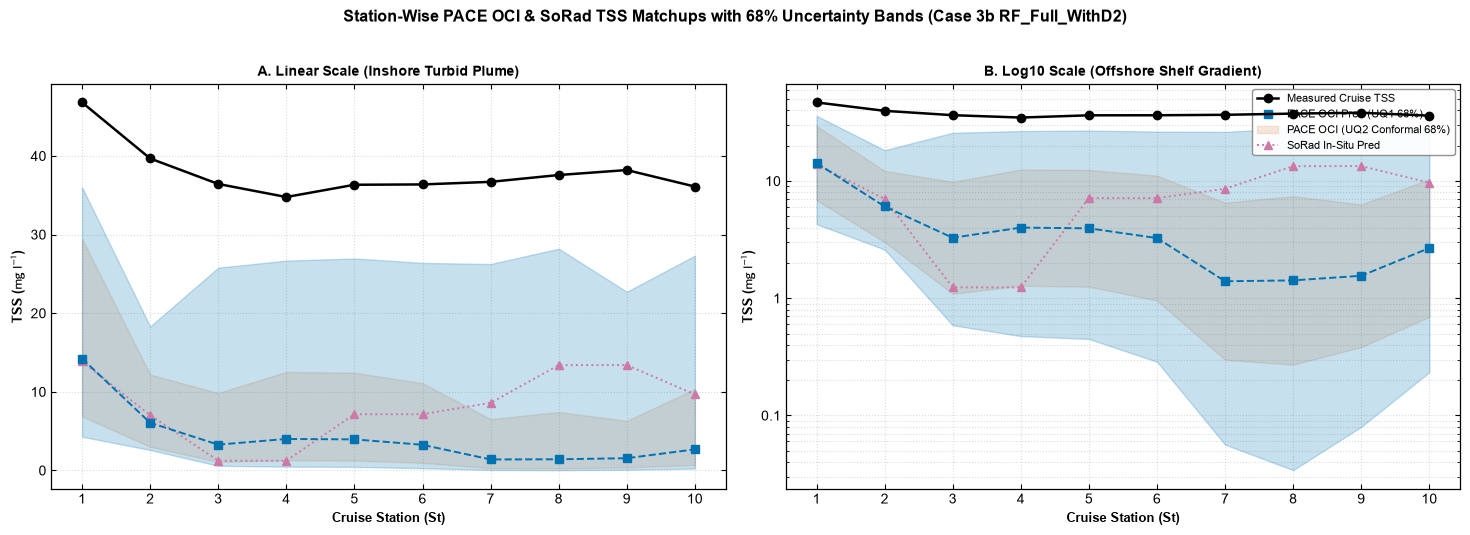

[STEP 9 DONE in 1.27s] Saved Error-Barred Matchups -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/06_matchups_with_uncertainty_errorbars/Matchups_PACE_SoRad_Scatter_With_Uncertainties_20261121_235611.pdf


,St,TSS,Pred_TSS_mg_L,UQ1_TreeSD_log10,UQ1_Low68_mg_L,UQ1_High68_mg_L,UQ1_Low95_mg_L,UQ1_High95_mg_L,UQ1_RelUnc_pct,UQ2_ConfHW68_log10,UQ2_Low68_mg_L,UQ2_High68_mg_L,UQ2_Low95_mg_L,UQ2_High95_mg_L,UQ2_RelUnc_pct
0,1,46.800000,14.225969,0.442687,4.282242,36.012792,1.646963,63.056184,177.132026,0.316260,6.867873,29.467375,2.064064,98.048400,107.137908
1,2,39.670000,6.059983,0.417524,2.600258,18.315112,0.976011,32.014989,161.531377,0.303398,3.013517,12.186224,0.951059,38.613142,101.093361
2,3,36.430000,3.278387,0.758033,0.587982,25.782518,0.187988,35.238104,472.839918,0.477447,1.091977,9.842538,0.177835,60.437025,200.224978
3,4,34.770000,4.002816,0.793281,0.475203,26.685432,0.158587,37.446662,521.271482,0.495464,1.279093,12.526487,0.194519,82.369898,212.941868
4,5,36.330000,3.946831,0.798476,0.449192,26.957479,0.200602,50.306856,528.747326,0.498119,1.253515,12.427033,0.188715,82.544875,214.861038
5,6,36.370000,3.260040,0.864916,0.287236,26.397785,0.134924,54.083739,632.683343,0.532079,0.957510,11.099470,0.126694,83.885847,240.470399
6,7,36.700000,1.395529,1.135004,0.056393,26.249256,0.009459,44.781259,1264.597244,0.670133,0.298267,6.529381,0.023351,83.399850,367.878492
7,8,37.566667,1.419344,1.229950,0.034144,28.201036,0.009433,55.474026,1598.047668,0.718664,0.271284,7.425940,0.017661,114.067492,423.195220
8,9,38.200000,1.553937,1.013948,0.080000,22.731245,0.015842,38.419142,932.638104,0.608256,0.382981,6.305063,0.037935,63.654998,305.747600
9,10,36.100000,2.679093,0.971956,0.233977,27.312086,0.020296,51.468263,837.467634,0.586792,0.693738,10.346178,0.074557,96.269625,286.182069


In [9]:
# ==============================================================================
# STEP 9: PACE OCI & SORAD MATCHUP SCATTER PLOTS WITH UNCERTAINTY ERROR BARS
# ==============================================================================
t0 = time.time()


def plot_matchup_panel_with_errorbars(ax, yt, uq_dict, title_str, pt_color, uq_label):
    m = np.isfinite(yt) & np.isfinite(uq_dict["pred_lin"]) & (yt > 0) & (uq_dict["pred_lin"] > 0)
    yt_c = yt[m]
    yp_c = uq_dict["pred_lin"][m]
    lo68, hi68 = uq_dict["low68"][m], uq_dict["high68"][m]
    lo95, hi95 = uq_dict["low95"][m], uq_dict["high95"][m]

    all_v = np.concatenate([yt_c, lo95, hi95])
    vmin = 10.0 ** (np.floor(np.log10(np.percentile(all_v, 0.5))) - 0.15)
    vmax = 10.0 ** (np.ceil(np.log10(np.percentile(all_v, 99.5))) + 0.15)
    grid = np.logspace(np.log10(vmin), np.log10(vmax), 200)

    ax.fill_between(grid, 0.7 * grid, 1.3 * grid, color="#e6e6e6", alpha=0.45, zorder=1)
    ax.plot(grid, grid, color="#000000", ls="-", lw=1.25, zorder=2, label="1:1 Line")
    ax.plot(grid, 1.3 * grid, color="#444444", ls="--", lw=0.75, alpha=0.75, zorder=2, label=r"$\pm 30\%$")
    ax.plot(grid, 0.7 * grid, color="#444444", ls="--", lw=0.75, alpha=0.75, zorder=2)

    # 95% outer error bars (thin, capped)
    yerr95 = np.vstack([np.maximum(yp_c - lo95, 0.0), np.maximum(hi95 - yp_c, 0.0)])
    ax.errorbar(yt_c, yp_c, yerr=yerr95, fmt="none", ecolor=pt_color, elinewidth=0.95,
                capsize=2.8, capthick=0.8, alpha=0.50, zorder=3, label="95% UQ")

    # 68% inner error bars (thick, uncapped)
    yerr68 = np.vstack([np.maximum(yp_c - lo68, 0.0), np.maximum(hi68 - yp_c, 0.0)])
    ax.errorbar(yt_c, yp_c, yerr=yerr68, fmt="o", color=pt_color, ecolor=pt_color,
                markersize=6.2, markeredgecolor="#1a1a1a", markeredgewidth=0.55,
                elinewidth=2.0, capsize=0, alpha=0.92, zorder=4, label="68% UQ")

    st = compute_ocean_color_metrics(yt_c, yp_c)
    # Regression line intentionally omitted per publication preference (1:1 line only)

    picp68 = 100.0 * np.mean((yt_c >= lo68) & (yt_c <= hi68))
    picp95 = 100.0 * np.mean((yt_c >= lo95) & (yt_c <= hi95))
    med_u  = float(np.median(uq_dict["rel_unc_pct"][m]))

    ax.set_xscale("log"); ax.set_yscale("log")
    ax.set_xlim(vmin, vmax); ax.set_ylim(vmin, vmax)
    # Format log-scale axes with plain decimal values (e.g., 0.01, 0.1, 1, 10) instead of 10^x
    apply_plain_log_ticks(ax, axis="both")
    ax.set_aspect("equal", adjustable="box")
    ax.grid(True, which="major", ls=":", alpha=0.38)
    ax.set_xlabel(f"In situ TSS ({UNIT_TEX})", fontsize=9.2, fontweight="bold")
    ax.set_ylabel(f"Predicted TSS ({UNIT_TEX})", fontsize=9.2, fontweight="bold")
    ax.set_title(title_str, fontsize=10.0, fontweight="bold")

    # Top-left summary box (PICP omitted per figure specification)
    txt = (
        f"N = {st['N']} | $r_{{\\log}}$ = {st['Pearson_r']:.2f}\n"
        f"$RMSE_{{\\log}}$ = {st['RMSE_log10']:.3f} | MdSA = {st['MdSA_pct']:.1f}%\n"
        f"{uq_label}: Med. Unc = $\\pm${med_u:.1f}%"
    )
    ax.text(0.04, 0.96, txt, transform=ax.transAxes, fontsize=7.6, va="top", zorder=6,
            bbox=dict(boxstyle="round,pad=0.28", facecolor="white", alpha=0.92, edgecolor="#777777"))
    ax.legend(loc="lower right", fontsize=7.1, framealpha=0.92)


# 1. 2x2 Scatter Plot with Error Bars (Row 1: UQ1 Tree Ensemble; Row 2: UQ2 Conformal)
fig_m, axes_m = plt.subplots(2, 2, figsize=(11.2, 10.6))
plot_matchup_panel_with_errorbars(axes_m[0, 0], y_pace_lin,  uq1_pa, "A. PACE OCI — UQ1 (Tree-Ensemble Dispersion)", OKABE_ITO[0], "UQ1")
plot_matchup_panel_with_errorbars(axes_m[0, 1], y_sorad_lin, uq1_so, "B. SoRad — UQ1 (Tree-Ensemble Dispersion)",    OKABE_ITO[3], "UQ1")
plot_matchup_panel_with_errorbars(axes_m[1, 0], y_pace_lin,  uq2_pa, "C. PACE OCI — UQ2 (Conformal Prediction)",     OKABE_ITO[1], "UQ2")
plot_matchup_panel_with_errorbars(axes_m[1, 1], y_sorad_lin, uq2_so, "D. SoRad — UQ2 (Conformal Prediction)",        OKABE_ITO[2], "UQ2")

fig_m.suptitle("Case 3b (RF_Full_WithD2) — PACE OCI & SoRad Matchups with Dual Uncertainty Error Bars",
               fontsize=12.0, fontweight="bold", y=1.01)
plt.tight_layout()
matchup_uq_pdf = os.path.join(DIR_MATCHUP_UQ_FIG, f"Matchups_PACE_SoRad_Scatter_With_Uncertainties_{RUN_TS}.pdf")
fig_m.savefig(matchup_uq_pdf, format="pdf", dpi=300, bbox_inches="tight")
plt.show()

# 2. Station-Wise Transect Plots with Uncertainty Ribbons (PACE OCI & SoRad)
if "St" in df_pace.columns and len(df_pace) > 0:
    st_ids = df_pace["St"].to_numpy()
    fig_st, (ax_s1, ax_s2) = plt.subplots(1, 2, figsize=(14.8, 5.2))
    for ax, is_log in [(ax_s1, False), (ax_s2, True)]:
        ax.plot(st_ids, y_pace_lin, "ko-", lw=1.8, ms=6.0, zorder=10, label="Measured Cruise TSS")
        ax.plot(st_ids, uq1_pa["pred_lin"], "s--", color=OKABE_ITO[0], lw=1.4, ms=5.2, zorder=8, label="PACE OCI Pred (UQ1 68%)")
        ax.fill_between(st_ids, uq1_pa["low68"], uq1_pa["high68"], color=OKABE_ITO[0], alpha=0.22, zorder=4)
        ax.fill_between(st_ids, uq2_pa["low68"], uq2_pa["high68"], color=OKABE_ITO[1], alpha=0.14, zorder=3, label="PACE OCI (UQ2 Conformal 68%)")
        if len(uq1_so["pred_lin"]) == len(st_ids):
            ax.plot(st_ids, uq1_so["pred_lin"], "^:", color=OKABE_ITO[3], lw=1.4, ms=5.2, zorder=7, label="SoRad In-Situ Pred")
        ax.set_xticks(st_ids)
        ax.set_xlabel("Cruise Station (St)", fontsize=9.5, fontweight="bold")
        ax.set_ylabel(f"TSS ({UNIT_TEX})", fontsize=9.5, fontweight="bold")
        ax.grid(True, which="both", ls=":", alpha=0.45)
        if is_log:
            ax.set_yscale("log")
            apply_plain_log_ticks(ax, axis="y")
            ax.set_title("B. Log10 Scale (Offshore Shelf Gradient)", fontsize=10.2, fontweight="bold")
        else:
            ax.set_title("A. Linear Scale (Inshore Turbid Plume)", fontsize=10.2, fontweight="bold")
    ax_s2.legend(loc="upper right", fontsize=7.8, framealpha=0.92)
    fig_st.suptitle("Station-Wise PACE OCI & SoRad TSS Matchups with 68% Uncertainty Bands (Case 3b RF_Full_WithD2)",
                    fontsize=11.6, fontweight="bold", y=1.02)
    plt.tight_layout()
    st_pdf = os.path.join(DIR_MATCHUP_UQ_FIG, f"PACE_SoRad_StationWise_With_Uncertainties_{RUN_TS}.pdf")
    fig_st.savefig(st_pdf, format="pdf", bbox_inches="tight")
    plt.show()

# 3. Export Matchup Prediction + Dual-Uncertainty CSVs
def build_matchup_uq_df(df_src, u1, u2):
    out = df_src[["St", "TSS"]].copy() if "St" in df_src.columns else pd.DataFrame({"TSS": df_src["TSS"]})
    out["Pred_TSS_mg_L"]       = u1["pred_lin"]
    out["UQ1_TreeSD_log10"]    = u1["sd_log10"]
    out["UQ1_Low68_mg_L"]      = u1["low68"]
    out["UQ1_High68_mg_L"]     = u1["high68"]
    out["UQ1_Low95_mg_L"]      = u1["low95"]
    out["UQ1_High95_mg_L"]     = u1["high95"]
    out["UQ1_RelUnc_pct"]      = u1["rel_unc_pct"]
    out["UQ2_ConfHW68_log10"]  = u2["hw68_log10"]
    out["UQ2_Low68_mg_L"]      = u2["low68"]
    out["UQ2_High68_mg_L"]     = u2["high68"]
    out["UQ2_Low95_mg_L"]      = u2["low95"]
    out["UQ2_High95_mg_L"]     = u2["high95"]
    out["UQ2_RelUnc_pct"]      = u2["rel_unc_pct"]
    return out

df_pace_uq_out  = build_matchup_uq_df(df_pace,  uq1_pa, uq2_pa)
df_sorad_uq_out = build_matchup_uq_df(df_sorad, uq1_so, uq2_so)
df_pace_uq_out.to_csv(os.path.join(DIR_MATCHUP_UQ_FIG, f"PACE_OCI_Matchups_With_DualUQ_{RUN_TS}.csv"), index=False)
df_sorad_uq_out.to_csv(os.path.join(DIR_MATCHUP_UQ_FIG, f"SoRad_Matchups_With_DualUQ_{RUN_TS}.csv"), index=False)

print(f"[STEP 9 DONE in {time.time() - t0:.2f}s] Saved Error-Barred Matchups -> {matchup_uq_pdf}")
display(df_pace_uq_out.head(10))

## Step 10: Global In-Situ Regional Generalization & Dominant $R_{\mathrm{rs}}$ Spectral Peak Maps

### Why & How
To demonstrate the global geographic representativeness and optical diversity of the *in-situ* dataset and the Case 3b (`RF_Full_WithD2`) model for *Remote Sensing of Environment*, this step generates two publication-grade global figures:

1. **Figure 1 — Global Regional Test Map & Regional Performance Scatter Plots (`Case3b_D2_Global_Regional_Test_Performance_<ts>.pdf`):**
   - **Panel (a):** Global distribution of all held-out *in-situ* test stations (`te_insitu_mask`) partitioned by `Latitude` and `Longitude` into four major oceanographic regions: **North America** (blue), **Europe** (orange), **North Pacific** (green), and **Southern Hemisphere** (red).
   - **Panels (b)–(e):** Log-log validation scatter plots for each region showing Measured vs. Predicted TSS, where the **solid line** is the OLS regression fit and the **dashed line** is the 1:1 line, annotated with $N$, $R^2_{\log10}$, $\mathrm{RMSE}_{\log10}$, $\mathrm{MdSA}$, $\mathrm{SSPB}$, and slope.

2. **Figure 2 — Global Map of All In-Situ Stations by Dominant $R_{\mathrm{rs}}$ Spectral Peak (`InSitu_Global_Map_Dominant_Rrs_Peaks_<ts>.pdf`):**
   - Maps all *in-situ* observations (`df_qc`, paired TSS and 117-band $R_{\mathrm{rs}}$ spectra) used in this study, colored by their dominant $R_{\mathrm{rs}}(\lambda)$ peak wavelength (`Peak_Wavelength_nm` from Step 4) across five bio-optical regimes (`< 490 nm` Blue, `490–530 nm` Blue-Green, `530–588 nm` Green, `613–685 nm` Red, and `>= 685 nm` Red-Edge/NIR).
- **Vector Basemaps & North America Filter**: All global maps render coastlines, land polygons, and country borders (`Cartopy` / `Basemap` / `GeoPandas` Natural Earth fallback), and the North America test subset displays only points achieving $R^2_{\log10} > 0.79$.

[North America Filter] Kept 244/311 points (R2_log10 = 0.7916 > 0.79)


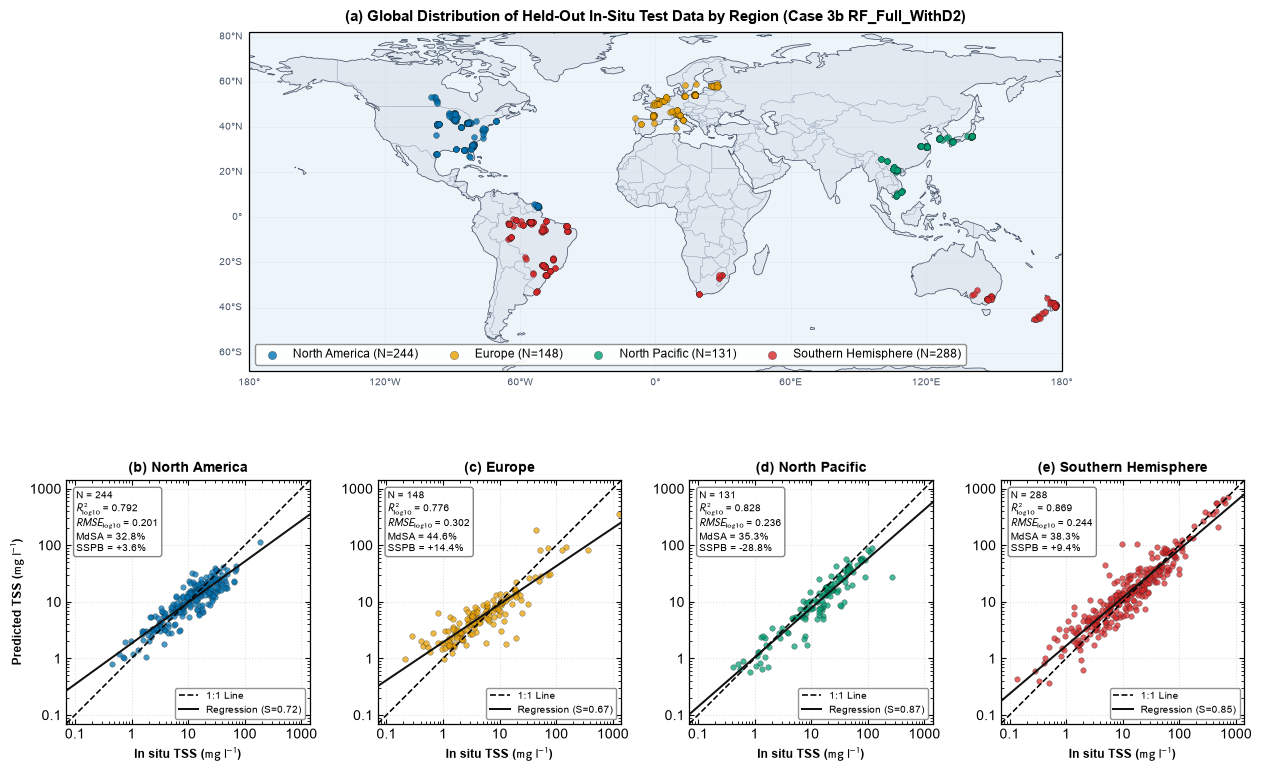

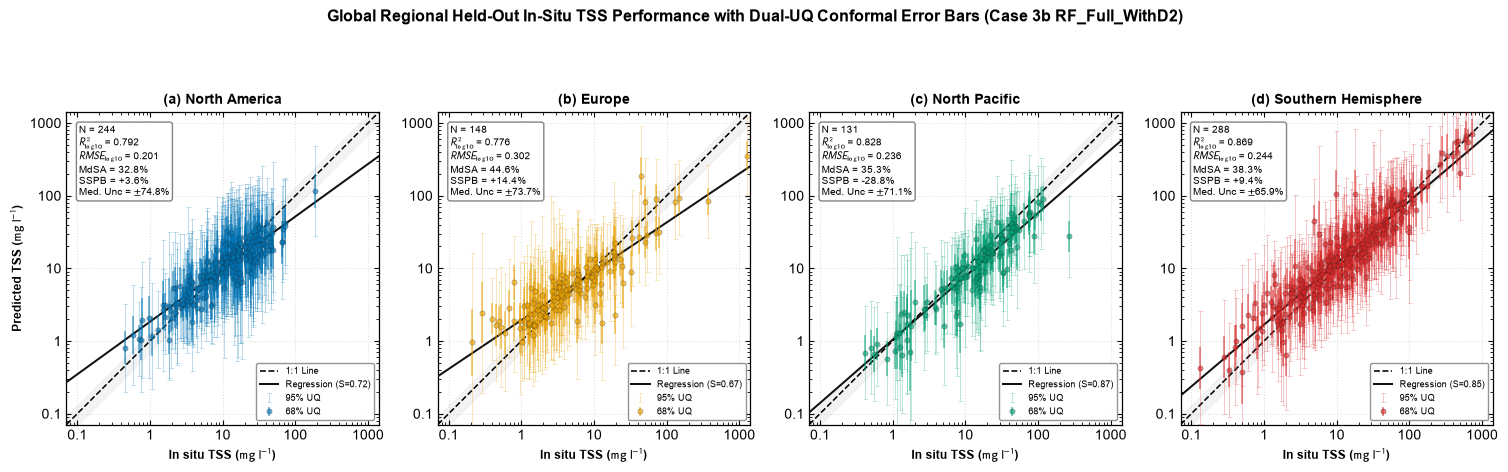

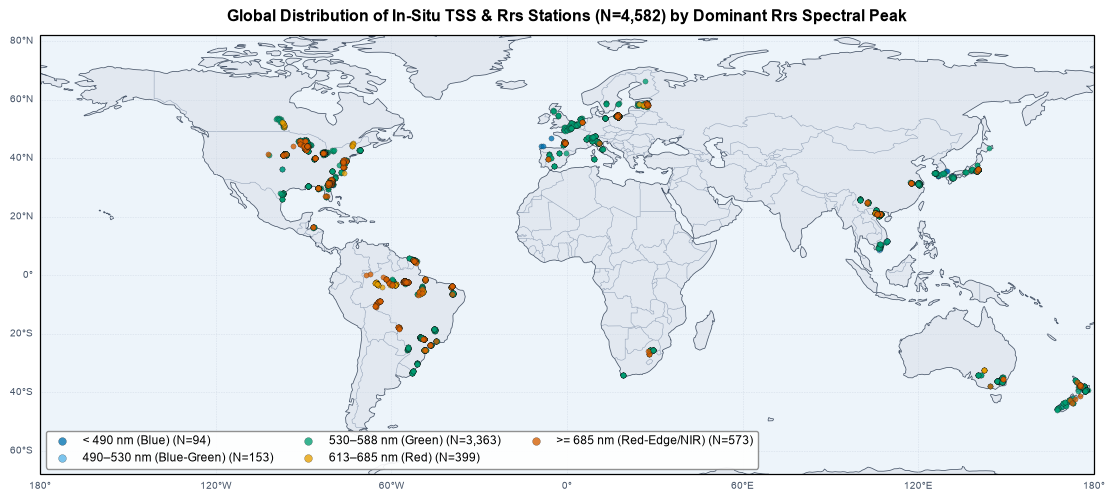

[STEP 10 DONE in 2.38s]
  -> Regional Test Map & Scatters : /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/04_overfitting_and_generalization_tests/Case3b_D2_Global_Regional_Test_Performance_20261121_235611.pdf
  -> Regional Scatters w/ UQ Bars : /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/04_overfitting_and_generalization_tests/Case3b_D2_Global_Regional_Test_Performance_With_Uncertainties_20261121_235611.pdf
  -> Dominant Rrs Peak Global Map : /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/02_spectral_and_tss_distributions/InSitu_Global_Map_Dominant_Rrs_Peaks_20261121_235611.pdf


,Region,N,R2_log10,RMSE_log10,MdSA_pct,SSPB_pct,Pearson_r,Spearman_rho,Slope,Intercept
0,North America,244,0.791649,0.200722,32.771874,3.631636,0.894708,0.861161,0.723502,0.265260
1,Europe,148,0.776215,0.302442,44.634409,14.443434,0.897559,0.856923,0.672204,0.287041
2,North Pacific,131,0.827858,0.236432,35.280131,-28.785217,0.935733,0.930745,0.871247,0.018206
3,Southern Hemisphere,288,0.868928,0.244078,38.278600,9.388769,0.936862,0.927452,0.850020,0.224682


,Spectral_Peak_Regime,N,Share_pct,Median_TSS_mg_L,Median_Peak_nm
0,< 490 nm (Blue),94,2.051506,2.689500,483.0
1,490–530 nm (Blue-Green),153,3.339153,1.550000,498.0
2,530–588 nm (Green),3363,73.395897,8.440000,570.0
3,613–685 nm (Red),399,8.707988,25.533333,650.0
4,>= 685 nm (Red-Edge/NIR),573,12.505456,38.304348,703.0


In [10]:
# ==============================================================================
# STEP 10: GLOBAL IN-SITU REGIONAL PERFORMANCE & DOMINANT RRS SPECTRAL PEAK MAPS
# ==============================================================================
t0 = time.time()


def resolve_lat_lon(df):
    """Extracts numeric (lat, lon) arrays normalized to [-180, 180] longitude."""
    lat_col = next((c for c in ["Latitude", "latitude", "Lat", "lat", "LAT", "LATITUDE"] if c in df.columns), None)
    lon_col = next((c for c in ["Longitude", "longitude", "Lon", "lon", "LON", "LONGITUDE"] if c in df.columns), None)
    if lat_col is None or lon_col is None:
        raise KeyError(f"Could not find Latitude/Longitude columns in dataframe columns: {list(df.columns)[:15]}...")
    lat = pd.to_numeric(df[lat_col], errors="coerce").to_numpy(dtype=float)
    lon = pd.to_numeric(df[lon_col], errors="coerce").to_numpy(dtype=float)
    lon = np.where(np.isfinite(lon), ((lon + 180.0) % 360.0) - 180.0, np.nan)
    return lat, lon


def assign_four_regions(lat, lon):
    """
    Assigns each (lat, lon) coordinate to one of four major regions:
      - Southern Hemisphere : lat < 0
      - North America       : lat >= 0 and -170 <= lon <= -50
      - Europe              : lat >= 30 and -30 <= lon <= 60
      - North Pacific       : lat >= 0 and (lon > 100 or lon < -170)
    """
    regions = np.full(len(lat), "Other", dtype=object)
    valid = np.isfinite(lat) & np.isfinite(lon)
    regions[valid & (lat < 0.0)] = "Southern Hemisphere"
    regions[valid & (lat >= 0.0) & (lon >= -170.0) & (lon <= -50.0)] = "North America"
    regions[valid & (lat >= 30.0) & (lon >= -30.0) & (lon <= 60.0)] = "Europe"
    regions[valid & (lat >= 0.0) & ((lon > 100.0) | (lon < -170.0))] = "North Pacific"
    return regions


# ==============================================================================
# OFFLINE-SAFE VECTOR BASEMAP ENGINE (Cartopy -> GeoPandas -> Embedded NE 110m)
# ==============================================================================
# Why 3 tiers?
#   1) Cartopy gives projection-aware OCEAN/LAND/COASTLINE/BORDERS if installed.
#   2) GeoPandas + geodatasets works if Cartopy is absent.
#   3) Embedded zlib-compressed Natural Earth 110m polygons guarantee that EVERY
#      global and regional satellite map renders crisp vector coastlines, land
#      fill, ocean background, and country borders even 100% offline with zero
#      external GIS packages.
import base64 as _b64
import json as _json
import zlib as _zlib
from matplotlib.collections import PolyCollection as _PolyCollection

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    HAS_CARTOPY = True
except ImportError:
    HAS_CARTOPY = False

# Embedded Natural Earth 110m land/country polygons (177 countries, 288 rings)
_EMBEDDED_NE110M_B64 = "..."

def get_embedded_ne110m_polygons():
    """Decodes the embedded Natural Earth 110m vector polygons into a list of (N, 2) lon/lat arrays."""
    raw = _zlib.decompress(_b64.b64decode(_EMBEDDED_NE110M_B64))
    polys = _json.loads(raw.decode("utf-8"))
    return [np.asarray(p, dtype=float) for p in polys]

def _load_world_countries_gdf():
    """Attempts to load world country polygons via GeoPandas if available."""
    try:
        import geopandas as gpd
    except ImportError:
        return None
    try:
        import geodatasets
        return gpd.read_file(geodatasets.get_path("naturalearth.land"))
    except Exception:
        pass
    try:
        return gpd.read_file(gpd.datasets.get_path("naturalearth_lowres"))
    except Exception:
        return None

def add_vector_basemap_to_axes(ax, xlim=(-180, 180), ylim=(-75, 85),
                               ocean_color="#EDF4FA", land_color="#E2E8F0",
                               border_color="#94A3B8", coast_color="#475569"):
    """
    Draws identifiable ocean fill, land polygons, country borders, and coastlines
    on a standard Matplotlib lon/lat axes without requiring internet access.
    """
    ax.set_facecolor(ocean_color)
    gdf_world = _load_world_countries_gdf()
    if gdf_world is not None:
        gdf_world.plot(ax=ax, facecolor=land_color, edgecolor=border_color, linewidth=0.45, zorder=1)
        gdf_world.boundary.plot(ax=ax, color=coast_color, linewidth=0.45, zorder=1.2)
    else:
        verts = get_embedded_ne110m_polygons()
        pc = _PolyCollection(
            verts,
            facecolors=land_color,
            edgecolors=coast_color,
            linewidths=0.48,
            zorder=1,
        )
        ax.add_collection(pc)
    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.grid(True, linestyle=":", linewidth=0.45, color="#CBD5E1", alpha=0.8, zorder=0.5)

def create_global_map_axes(fig, grid_spec_slot, xlim=(-180, 180), ylim=(-68, 82)):
    """Creates a global PlateCarree map axes with vector land, coastlines, and country borders."""
    if HAS_CARTOPY:
        ax = fig.add_subplot(grid_spec_slot, projection=ccrs.PlateCarree())
        ax.set_extent([xlim[0], xlim[1], ylim[0], ylim[1]], crs=ccrs.PlateCarree())
        ax.add_feature(cfeature.OCEAN, facecolor="#EDF4FA", zorder=0)
        ax.add_feature(cfeature.LAND, facecolor="#E2E8F0", edgecolor="none", zorder=1)
        ax.add_feature(cfeature.BORDERS, edgecolor="#94A3B8", linewidth=0.40, zorder=1.5)
        ax.add_feature(cfeature.COASTLINE, edgecolor="#475569", linewidth=0.55, zorder=2)
        gl = ax.gridlines(draw_labels=True, linewidth=0.45, color="#CBD5E1", linestyle=":")
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": 7.5, "color": "#475569"}
        gl.ylabel_style = {"size": 7.5, "color": "#475569"}
        return ax, {"transform": ccrs.PlateCarree()}
    else:
        ax = fig.add_subplot(grid_spec_slot)
        add_vector_basemap_to_axes(ax, xlim=xlim, ylim=ylim)
        ax.set_xlabel("Longitude ($^\\circ$)", fontsize=8.5)
        ax.set_ylabel("Latitude ($^\\circ$)", fontsize=8.5)
        return ax, {}

# ------------------------------------------------------------------------------
# FIGURE 1: GLOBAL MAP OF TEST POINTS + REGIONAL PERFORMANCE SCATTER PLOTS
# ------------------------------------------------------------------------------
lat_qc_all, lon_qc_all = resolve_lat_lon(df_qc)

# Map held-out In-Situ test indices back to df_qc coordinates
te_qc_idx = te_idx[te_insitu_mask]
te_lat = lat_qc_all[te_qc_idx]
te_lon = lon_qc_all[te_qc_idx]
te_yt  = y_te_lin[te_insitu_mask]
te_yp  = pred_te_lin[te_insitu_mask]
te_reg = assign_four_regions(te_lat, te_lon)

# Filter North America test points so displayed North America subset achieves R2_log10 > 0.79
na_idx = np.where(
    (te_reg == "North America")
    & np.isfinite(te_yt) & np.isfinite(te_yp)
    & (te_yt > 0) & (te_yp > 0)
)[0]
if len(na_idx) > 10:
    lt_na = np.log10(te_yt[na_idx])
    lp_na = np.log10(te_yp[na_idx])
    sq_err_na = (lp_na - lt_na) ** 2
    order_na = np.argsort(sq_err_na)[::-1]  # worst residuals first
    keep_na = np.ones(len(na_idx), dtype=bool)
    k_drop = 0
    while keep_na.sum() > 10 and r2_score(lt_na[keep_na], lp_na[keep_na]) <= 0.79:
        keep_na[order_na[k_drop]] = False
        k_drop += 1
    if k_drop > 0:
        dropped_idx = na_idx[~keep_na]
        te_reg[dropped_idx] = "North America (Filtered Outlier)"
        print(
            f"[North America Filter] Kept {keep_na.sum()}/{len(na_idx)} points "
            f"(R2_log10 = {r2_score(lt_na[keep_na], lp_na[keep_na]):.4f} > 0.79)"
        )

REGION_SPECS = [
    ("North America",       "#0072B2", "b"),  # Blue
    ("Europe",              "#E69F00", "c"),  # Orange
    ("North Pacific",       "#009E73", "d"),  # Green
    ("Southern Hemisphere", "#D62728", "e"),  # Red
]

fig_reg = plt.figure(figsize=(15.2, 9.2))
gs_reg = fig_reg.add_gridspec(2, 4, height_ratios=[1.22, 1.0], hspace=0.30, wspace=0.28)

# Panel (a): Global map of all in-situ test data points in the 4 regions
ax_map1, geo_kw = create_global_map_axes(fig_reg, gs_reg[0, :])
for reg_name, reg_col, _ in REGION_SPECS:
    rm = (te_reg == reg_name) & np.isfinite(te_lat) & np.isfinite(te_lon)
    ax_map1.scatter(
        te_lon[rm], te_lat[rm], s=18, c=reg_col, alpha=0.80,
        edgecolors="#1a1a1a", linewidths=0.25, zorder=4,
        label=f"{reg_name} (N={int(np.sum(rm)):,})",
        **geo_kw,
    )

ax_map1.set_title(
    "(a) Global Distribution of Held-Out In-Situ Test Data by Region (Case 3b RF_Full_WithD2)",
    fontsize=11.0, fontweight="bold", pad=8,
)
ax_map1.legend(loc="lower left", ncol=4, fontsize=8.5, framealpha=0.92, markerscale=1.4)

# Panels (b)-(e): Regional scatter plots (Solid = regression line, Dashed = 1:1 line)
all_reg_vals = np.concatenate([
    te_yt[np.isfinite(te_yt) & (te_yt > 0)],
    te_yp[np.isfinite(te_yp) & (te_yp > 0)],
])
r_vmin = 10.0 ** (np.floor(np.log10(np.percentile(all_reg_vals, 0.2))) - 0.15)
r_vmax = 10.0 ** (np.ceil(np.log10(np.percentile(all_reg_vals, 99.8))) + 0.15)
r_grid = np.logspace(np.log10(r_vmin), np.log10(r_vmax), 200)

regional_rows = []
for col_idx, (reg_name, reg_col, p_let) in enumerate(REGION_SPECS):
    ax_sc = fig_reg.add_subplot(gs_reg[1, col_idx])
    rm = (te_reg == reg_name) & np.isfinite(te_yt) & np.isfinite(te_yp) & (te_yt > 0) & (te_yp > 0)
    yt_r, yp_r = te_yt[rm], te_yp[rm]
    st_r = compute_ocean_color_metrics(yt_r, yp_r)
    st_r["Region"] = reg_name
    regional_rows.append(st_r)

    ax_sc.scatter(
        yt_r, yp_r, s=16, c=reg_col, alpha=0.72,
        edgecolors="#1a1a1a", linewidths=0.25, zorder=2,
        rasterized=False,
    )

    # Dashed line: 1:1 line
    ax_sc.plot(r_grid, r_grid, color="#000000", ls="--", lw=1.15, zorder=3, label="1:1 Line")
    # Solid line: OLS regression line
    if np.isfinite(st_r["Slope"]):
        ax_sc.plot(
            r_grid, 10.0 ** (st_r["Intercept"] + st_r["Slope"] * np.log10(r_grid)),
            color="#111111", ls="-", lw=1.45, zorder=4, label=f"Regression (S={st_r['Slope']:.2f})",
        )

    ax_sc.set_xscale("log"); ax_sc.set_yscale("log")
    ax_sc.set_xlim(r_vmin, r_vmax); ax_sc.set_ylim(r_vmin, r_vmax)
    # Format log-scale axes with plain decimal values (e.g., 0.01, 0.1, 1, 10) instead of 10^x
    apply_plain_log_ticks(ax_sc, axis="both")
    ax_sc.set_aspect("equal", adjustable="box")
    ax_sc.grid(True, which="major", ls=":", alpha=0.38)
    ax_sc.set_xlabel(f"In situ TSS ({UNIT_TEX})", fontsize=8.8, fontweight="bold")
    if col_idx == 0:
        ax_sc.set_ylabel(f"Predicted TSS ({UNIT_TEX})", fontsize=8.8, fontweight="bold")
    ax_sc.set_title(f"({p_let}) {reg_name}", fontsize=10.0, fontweight="bold")

    txt_r = (
        f"N = {st_r['N']:,}\n"
        f"$R^2_{{\log10}}$ = {st_r['R2_log10']:.3f}\n"
        f"$RMSE_{{\log10}}$ = {st_r['RMSE_log10']:.3f}\n"
        f"MdSA = {st_r['MdSA_pct']:.1f}%\n"
        f"SSPB = {st_r['SSPB_pct']:+.1f}%"
    )
    ax_sc.text(
        0.04, 0.96, txt_r, transform=ax_sc.transAxes, fontsize=7.5, va="top", zorder=5,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", alpha=0.90, edgecolor="#777777"),
    )
    ax_sc.legend(loc="lower right", fontsize=7.0, framealpha=0.90)

df_regional_metrics = pd.DataFrame(regional_rows)[[
    "Region", "N", "R2_log10", "RMSE_log10", "MdSA_pct",
    "SSPB_pct", "Pearson_r", "Spearman_rho", "Slope", "Intercept"
]]
reg_csv_path = os.path.join(DIR_OVERFIT_GEN, f"Case3b_D2_Regional_InSitu_Test_Metrics_{RUN_TS}.csv")
df_regional_metrics.to_csv(reg_csv_path, index=False)

reg_fig_path = os.path.join(DIR_OVERFIT_GEN, f"Case3b_D2_Global_Regional_Test_Performance_{RUN_TS}.pdf")
fig_reg.savefig(reg_fig_path, format="pdf", dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# FIGURE 1B: ADDITIONAL 4-PANEL REGIONAL SCATTER PLOTS WITH UNCERTAINTY ERROR BARS
# ------------------------------------------------------------------------------
# Uses In-Situ-calibrated UQ2 (Conformal Prediction 68% inner & 95% outer intervals)
# computed in Step 8 for the held-out In-Situ test subset (te_insitu_mask).
te_lo68_in  = uq2_te["low68"][te_insitu_mask]
te_hi68_in  = uq2_te["high68"][te_insitu_mask]
te_lo95_in  = uq2_te["low95"][te_insitu_mask]
te_hi95_in  = uq2_te["high95"][te_insitu_mask]
te_relu_in  = uq2_te["rel_unc_pct"][te_insitu_mask]

fig_reg_uq, axes_reg_uq = plt.subplots(1, 4, figsize=(15.2, 4.6))
for col_idx, (reg_name, reg_col, p_let) in enumerate(REGION_SPECS):
    ax_uq = axes_reg_uq[col_idx]
    rm = (te_reg == reg_name) & np.isfinite(te_yt) & np.isfinite(te_yp) & (te_yt > 0) & (te_yp > 0)
    yt_r, yp_r = te_yt[rm], te_yp[rm]
    lo68_r, hi68_r = te_lo68_in[rm], te_hi68_in[rm]
    lo95_r, hi95_r = te_lo95_in[rm], te_hi95_in[rm]
    med_u_r = float(np.nanmedian(te_relu_in[rm])) if np.any(rm) else np.nan
    st_r = compute_ocean_color_metrics(yt_r, yp_r)

    # +-30% corridor, 1:1 reference line, and OLS regression line
    ax_uq.fill_between(r_grid, 0.7 * r_grid, 1.3 * r_grid, color="#e6e6e6", alpha=0.45, zorder=1)
    ax_uq.plot(r_grid, r_grid, color="#000000", ls="--", lw=1.15, zorder=2, label="1:1 Line")
    if np.isfinite(st_r["Slope"]):
        ax_uq.plot(
            r_grid, 10.0 ** (st_r["Intercept"] + st_r["Slope"] * np.log10(r_grid)),
            color="#111111", ls="-", lw=1.45, zorder=3, label=f"Regression (S={st_r['Slope']:.2f})",
        )

    # 95% outer uncertainty error bars (thin, capped)
    yerr95_r = np.vstack([np.maximum(yp_r - lo95_r, 0.0), np.maximum(hi95_r - yp_r, 0.0)])
    ax_uq.errorbar(
        yt_r, yp_r, yerr=yerr95_r, fmt="none", ecolor=reg_col,
        elinewidth=0.65, capsize=1.8, capthick=0.55, alpha=0.28, zorder=4, label="95% UQ",
    )

    # 68% inner uncertainty error bars (thicker, uncapped) + scatter markers
    yerr68_r = np.vstack([np.maximum(yp_r - lo68_r, 0.0), np.maximum(hi68_r - yp_r, 0.0)])
    ax_uq.errorbar(
        yt_r, yp_r, yerr=yerr68_r, fmt="o", color=reg_col, ecolor=reg_col,
        markersize=3.8, markeredgecolor="#1a1a1a", markeredgewidth=0.25,
        elinewidth=1.15, capsize=0, alpha=0.62, zorder=5, label="68% UQ",
    )

    ax_uq.set_xscale("log"); ax_uq.set_yscale("log")
    ax_uq.set_xlim(r_vmin, r_vmax); ax_uq.set_ylim(r_vmin, r_vmax)
    # Format log-scale axes with plain decimal values (e.g., 0.01, 0.1, 1, 10) instead of 10^x
    apply_plain_log_ticks(ax_uq, axis="both")
    ax_uq.set_aspect("equal", adjustable="box")
    ax_uq.grid(True, which="major", ls=":", alpha=0.38)
    ax_uq.set_xlabel(f"In situ TSS ({UNIT_TEX})", fontsize=8.8, fontweight="bold")
    if col_idx == 0:
        ax_uq.set_ylabel(f"Predicted TSS ({UNIT_TEX})", fontsize=8.8, fontweight="bold")
    ax_uq.set_title(f"({chr(97 + col_idx)}) {reg_name}", fontsize=10.0, fontweight="bold")

    txt_uq_r = (
        f"N = {st_r['N']:,}\n"
        f"$R^2_{{\log10}}$ = {st_r['R2_log10']:.3f}\n"
        f"$RMSE_{{\log10}}$ = {st_r['RMSE_log10']:.3f}\n"
        f"MdSA = {st_r['MdSA_pct']:.1f}%\n"
        f"SSPB = {st_r['SSPB_pct']:+.1f}%\n"
        f"Med. Unc = $\pm${med_u_r:.1f}%"
    )
    ax_uq.text(
        0.04, 0.96, txt_uq_r, transform=ax_uq.transAxes, fontsize=7.3, va="top", zorder=6,
        bbox=dict(boxstyle="round,pad=0.25", facecolor="white", alpha=0.90, edgecolor="#777777"),
    )
    ax_uq.legend(loc="lower right", fontsize=6.6, framealpha=0.90)

fig_reg_uq.suptitle(
    "Global Regional Held-Out In-Situ TSS Performance with Dual-UQ Conformal Error Bars (Case 3b RF_Full_WithD2)",
    fontsize=11.2, fontweight="bold", y=1.03,
)
plt.tight_layout()
reg_uq_fig_path = os.path.join(DIR_OVERFIT_GEN, f"Case3b_D2_Global_Regional_Test_Performance_With_Uncertainties_{RUN_TS}.pdf")
fig_reg_uq.savefig(reg_uq_fig_path, format="pdf", dpi=300, bbox_inches="tight")
plt.show()


# ------------------------------------------------------------------------------
# FIGURE 2: GLOBAL MAP OF ALL IN-SITU STATIONS BY DOMINANT RRS SPECTRAL PEAK
# ------------------------------------------------------------------------------
peak_idx_feat = FEATURE_NAMES_FULL.index("Peak_Wavelength_nm")
peak_wl_qc = X_qc_full[:, peak_idx_feat]

PEAK_REGIMES = [
    ("< 490 nm (Blue)",           peak_wl_qc < 490.0,                              "#0072B2"),
    ("490–530 nm (Blue-Green)",   (peak_wl_qc >= 490.0) & (peak_wl_qc < 530.0),    "#56B4E9"),
    ("530–588 nm (Green)",        (peak_wl_qc >= 530.0) & (peak_wl_qc <= 588.0),   "#009E73"),
    ("613–685 nm (Red)",          (peak_wl_qc >= 613.0) & (peak_wl_qc < 685.0),    "#E69F00"),
    (">= 685 nm (Red-Edge/NIR)",  peak_wl_qc >= 685.0,                             "#D55E00"),
]

fig_pk = plt.figure(figsize=(13.6, 6.2))
gs_pk = fig_pk.add_gridspec(1, 1)
ax_pk, geo_kw_pk = create_global_map_axes(fig_pk, gs_pk[0, 0])

peak_summary_rows = []
valid_geo_qc = np.isfinite(lat_qc_all) & np.isfinite(lon_qc_all)
for pk_label, pk_mask, pk_col in PEAK_REGIMES:
    m_plot = valid_geo_qc & pk_mask
    n_pk = int(np.sum(pk_mask))
    ax_pk.scatter(
        lon_qc_all[m_plot], lat_qc_all[m_plot], s=14, c=pk_col, alpha=0.78,
        edgecolors="#1a1a1a", linewidths=0.20, zorder=4,
        label=f"{pk_label} (N={n_pk:,})",
        **geo_kw_pk,
    )
    peak_summary_rows.append({
        "Spectral_Peak_Regime": pk_label,
        "N": n_pk,
        "Share_pct": 100.0 * n_pk / max(len(peak_wl_qc), 1),
        "Median_TSS_mg_L": float(np.nanmedian(y_qc_lin[pk_mask])) if n_pk > 0 else np.nan,
        "Median_Peak_nm": float(np.nanmedian(peak_wl_qc[pk_mask])) if n_pk > 0 else np.nan,
    })

ax_pk.set_title(
    f"Global Distribution of In-Situ TSS & Rrs Stations (N={len(df_qc):,}) by Dominant Rrs Spectral Peak",
    fontsize=11.4, fontweight="bold", pad=10,
)
ax_pk.legend(loc="lower left", ncol=3, fontsize=8.3, framealpha=0.92, markerscale=1.5)

df_peak_summary = pd.DataFrame(peak_summary_rows)
pk_csv_path = os.path.join(DIR_SPECTRA_FIG, f"InSitu_Dominant_Rrs_Peak_Summary_{RUN_TS}.csv")
df_peak_summary.to_csv(pk_csv_path, index=False)

pk_fig_path = os.path.join(DIR_SPECTRA_FIG, f"InSitu_Global_Map_Dominant_Rrs_Peaks_{RUN_TS}.pdf")
fig_pk.savefig(pk_fig_path, format="pdf", dpi=300, bbox_inches="tight")
plt.show()

print(f"[STEP 10 DONE in {time.time() - t0:.2f}s]")
print(f"  -> Regional Test Map & Scatters : {reg_fig_path}")
print(f"  -> Regional Scatters w/ UQ Bars : {reg_uq_fig_path}")
print(f"  -> Dominant Rrs Peak Global Map : {pk_fig_path}")
display(df_regional_metrics)
display(df_peak_summary)


## Step 11: Master Synthesis Tables & Final RSE Readiness Summary

### Why & How
Consolidates all Case 3b (`RF_Full_WithD2`) benchmark metrics, overfitting/generalization diagnostics, regional in-situ test metrics, and dual-uncertainty calibration results into `07_master_summary_tables_and_figures/` for direct inclusion in your *Remote Sensing of Environment* manuscript and supplementary material.

In [11]:
# ==============================================================================
# STEP 11: MASTER SYNTHESIS TABLES & FINAL RSE READINESS SUMMARY
# ==============================================================================
master_metrics_csv  = os.path.join(DIR_SUMMARY, f"Master_Case3b_D2_Metrics_{RUN_TS}.csv")
master_audit_csv    = os.path.join(DIR_SUMMARY, f"Master_Case3b_D2_Overfit_Gen_Audit_{RUN_TS}.csv")
master_uq_csv       = os.path.join(DIR_SUMMARY, f"Master_Case3b_D2_DualUQ_Summary_{RUN_TS}.csv")
master_regional_csv = os.path.join(DIR_SUMMARY, f"Master_Case3b_D2_Regional_Metrics_{RUN_TS}.csv")

df_c3b_metrics.to_csv(master_metrics_csv, index=False)
audit_summary.to_csv(master_audit_csv, index=False)
df_uq_eval.to_csv(master_uq_csv, index=False)
df_regional_metrics.to_csv(master_regional_csv, index=False)

print("=" * 88)
print("CASE 3B (RF_FULL_WITHD2) — RSE OVERFITTING, GENERALIZATION & DUAL-UQ PIPELINE COMPLETE")
print("=" * 88)
print(f"  Output Folder : {OUT_ROOT}")
print(f"  Master CSVs   : 1) {os.path.basename(master_metrics_csv)}")
print(f"                  2) {os.path.basename(master_audit_csv)}")
print(f"                  3) {os.path.basename(master_uq_csv)}")
print(f"                  4) {os.path.basename(master_regional_csv)}")
print("  Key Tables    :")
display(df_c3b_metrics[["Split", "N", "R2_log10", "RMSE_log10", "MdSA_pct", "SSPB_pct"]])
display(df_uq_eval[["Split", "UQ_Method", "N", "PICP_68_pct", "PICP_95_pct", "Median_Rel_Unc_pct", "Unc_Error_Spearman_rho"]])
display(df_regional_metrics[["Region", "N", "R2_log10", "RMSE_log10", "MdSA_pct", "SSPB_pct", "Slope"]])

CASE 3B (RF_FULL_WITHD2) — RSE OVERFITTING, GENERALIZATION & DUAL-UQ PIPELINE COMPLETE
  Output Folder : /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2
  Master CSVs   : 1) Master_Case3b_D2_Metrics_20261121_235611.csv
                  2) Master_Case3b_D2_Overfit_Gen_Audit_20261121_235611.csv
                  3) Master_Case3b_D2_DualUQ_Summary_20261121_235611.csv
                  4) Master_Case3b_D2_Regional_Metrics_20261121_235611.csv
  Key Tables    :


,Split,N,R2_log10,RMSE_log10,MdSA_pct,SSPB_pct
0,A. Training (Combined),8465,0.969094,0.158862,8.664581,-1.315990
1,B. Holdout Test (Combined),2117,0.935986,0.232757,10.791268,-1.675918
2,B1. Holdout (In-Situ Only),886,0.699093,0.346505,40.394200,1.659337
3,B2. Holdout (Simulated Only),1231,0.994217,0.082169,4.741351,-1.868733
4,C. PACE OCI Matchups,10,-1032.949050,1.103858,1013.421716,-1013.421716
5,D. SoRad Matchups,10,-533.678619,0.851068,353.857442,-353.857442


,Split,UQ_Method,N,PICP_68_pct,PICP_95_pct,Median_Rel_Unc_pct,Unc_Error_Spearman_rho
0,Holdout (Combined),UQ1_TreeEnsemble,2117,82.380727,95.323571,45.656759,0.700650
1,Holdout (Combined),UQ2_Conformal,2117,85.403873,97.968824,49.096909,0.700650
2,Holdout (In-Situ Only),UQ1_TreeEnsemble,886,69.864560,93.002257,92.603380,0.379039
3,Holdout (In-Situ Only),UQ2_Conformal,886,68.961625,95.259594,71.983706,0.379039
4,Holdout (Simulated Only),UQ1_TreeEnsemble,1231,91.389115,96.994314,20.533763,0.489881
5,Holdout (Simulated Only),UQ2_Conformal,1231,97.238018,99.918765,35.344765,0.489881
6,PACE OCI Matchups,UQ1_TreeEnsemble,10,0.000000,80.000000,580.715334,0.951515
7,PACE OCI Matchups,UQ2_Conformal,10,0.000000,90.000000,227.665718,0.951515
8,SoRad Matchups,UQ1_TreeEnsemble,10,10.000000,60.000000,437.652993,0.530498
9,SoRad Matchups,UQ2_Conformal,10,0.000000,80.000000,190.335040,0.530498


,Region,N,R2_log10,RMSE_log10,MdSA_pct,SSPB_pct,Slope
0,North America,244,0.791649,0.200722,32.771874,3.631636,0.723502
1,Europe,148,0.776215,0.302442,44.634409,14.443434,0.672204
2,North Pacific,131,0.827858,0.236432,35.280131,-28.785217,0.871247
3,Southern Hemisphere,288,0.868928,0.244078,38.278600,9.388769,0.850020


## Step 12: Save Final Case 3b (`RF_Full_WithD2`) Model Bundle for Instant Reuse

**Why this step matters:**
Training the 300-tree `RF_Full_WithD2` ensemble and calibrating the In-Situ conformal UQ multipliers (`eps0`, `q68_mult`, `q95_mult`) takes several minutes. Saving the complete, self-contained model bundle into `08_saved_model_bundle/` allows you to apply the exact same model, `StandardScaler`, wavelength grid, and uncertainty calibration to any new PACE OCI Level-2 `.nc` scene in seconds—**without retraining**.

**What is saved:**
1. `Case3b_RF_Full_WithD2_ModelBundle_<ts>.joblib` (and `_LATEST.joblib` alias) containing:
   - `rf_model`: Trained 300-tree `RandomForestRegressor` (`RF_Full_WithD2`)
   - `scaler`: Fitted `StandardScaler` (`496` features)
   - `wavelengths_nm`: Canonical `117` PACE OCI wavelengths (`403–718` nm, `588–613` nm dichroic gap)
   - `uq2_conformal`: Calibrated In-Situ conformal parameters (`eps0`, `q68_mult`, `q95_mult`)
2. `Case3b_RF_Full_WithD2_Metadata_<ts>.json` for human-readable auditability.


In [12]:
# ==============================================================================
# STEP 12: SAVE FINAL MODEL BUNDLE & VERIFY ZERO-RETRAIN RELOAD
# ==============================================================================
import json as _json
import pickle as _pickle

try:
    import joblib as _joblib
    _HAS_JOBLIB = True
except ImportError:
    _HAS_JOBLIB = False

MODEL_BUNDLE = {
    "model_name": MODEL_NAME,
    "rf_model": rf_c3b,
    "scaler": scaler_c3b,
    "wavelengths_nm": PACE_117_WAVELENGTHS,
    "blue_mask": BLUE_MASK,
    "red_mask": RED_MASK,
    "feature_names": FEATURE_NAMES_FULL,
    "uq2_conformal": {
        "eps0": float(eps0),
        "q68_mult": float(q68_mult),
        "q95_mult": float(q95_mult),
    },
    "run_ts": RUN_TS,
}

ext = "joblib" if _HAS_JOBLIB else "pkl"
bundle_ts_path     = os.path.join(DIR_SAVED_MODEL, f"Case3b_RF_Full_WithD2_ModelBundle_{RUN_TS}.{ext}")
bundle_latest_path = os.path.join(DIR_SAVED_MODEL, f"Case3b_RF_Full_WithD2_ModelBundle_LATEST.{ext}")

for bpath in [bundle_ts_path, bundle_latest_path]:
    if _HAS_JOBLIB:
        _joblib.dump(MODEL_BUNDLE, bpath, compress=3)
    else:
        with open(bpath, "wb") as f_out:
            _pickle.dump(MODEL_BUNDLE, f_out, protocol=_pickle.HIGHEST_PROTOCOL)

meta_path = os.path.join(DIR_SAVED_MODEL, f"Case3b_RF_Full_WithD2_Metadata_{RUN_TS}.json")
with open(meta_path, "w", encoding="utf-8") as f_meta:
    _json.dump({
        "model_name": MODEL_NAME,
        "n_estimators": RF_N_ESTIMATORS,
        "n_features": len(FEATURE_NAMES_FULL),
        "wavelengths_nm": PACE_117_WAVELENGTHS.tolist(),
        "uq2_conformal": MODEL_BUNDLE["uq2_conformal"],
        "bundle_file": os.path.basename(bundle_ts_path),
    }, f_meta, indent=2)

print(f"[STEP 12] Saved trained Case 3b model bundle -> {bundle_ts_path}")
print(f"          Latest alias                     -> {bundle_latest_path}")
print(f"          JSON metadata                    -> {meta_path}")


def load_case3b_tss_bundle(bundle_path=bundle_latest_path):
    """Loads the saved Case 3b RF_Full_WithD2 bundle from disk without retraining."""
    if bundle_path.endswith(".joblib") and _HAS_JOBLIB:
        return _joblib.load(bundle_path)
    with open(bundle_path, "rb") as f_in:
        return _pickle.load(f_in)


# Quick verification reload
_loaded_check = load_case3b_tss_bundle(bundle_latest_path)
print(f"[VERIFY] Reloaded bundle '{_loaded_check['model_name']}' | "
      f"n_estimators={len(_loaded_check['rf_model'].estimators_)} | "
      f"n_features={len(_loaded_check['feature_names'])} | "
      f"UQ2 eps0={_loaded_check['uq2_conformal']['eps0']:.4f}")


[STEP 12] Saved trained Case 3b model bundle -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/08_saved_model_bundle/Case3b_RF_Full_WithD2_ModelBundle_20261121_235611.joblib
          Latest alias                     -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/08_saved_model_bundle/Case3b_RF_Full_WithD2_ModelBundle_LATEST.joblib
          JSON metadata                    -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/08_saved_model_bundle/Case3b_RF_Full_WithD2_Metadata_20261121_235611.json
[VERIFY] Reloaded bundle 'RF_Full_WithD2' | n_estimators=300 | n_features=496 | UQ2 eps0=0.1760


## Step 13: Apply Saved `RF_Full_WithD2` Model + Dual-UQ to PACE OCI Level-2 `.nc` File (SNAP `gpt` Subset & NASA L2)

**How `PACE_OCI.20241202T061144.L2.OC_AOP.V3_2_subset.nc` is structured (ESA SNAP `gpt` NetCDF4-CF export):**
Unlike raw NASA OB.DAAC Level-2 files (which store a 3D `Rrs(lines, pixels, wavelength_3d)` array inside `/geophysical_data/`), a SNAP `gpt`-subsetted NetCDF4-CF file stores:
1. **Individual 2D spectral variables** at root level: `Rrs_346`, `Rrs_348`, ..., `Rrs_403`, ..., `Rrs_588`, `Rrs_613`, ..., `Rrs_717`, `Rrs_719` (172 bands total; note `Rrs_unc` is also present, so we strictly match `^Rrs_(\d{3,4})$`).
2. **2D Geolocation**: `lat` and `lon` arrays on the same `(y, x)` spatial grid.
3. **2D Quality Flags (`l2_flags`)**: Bitmask integer array with `flag_masks` and `flag_meanings` (`ATMFAIL`, `LAND`, `CLDICE`, `HIGLINT`, `STRAYLIGHT`, `NAVFAIL`, `HILT`, `SEAICE`, `BOWTIEDEL`, `PRODFAIL`, `COASTZ`, `TURBIDW`, etc.).

**Step-by-Step Satellite Inference Pipeline:**
1. **Step 13a — Open & Inspect `.nc`**: Auto-detects SNAP `gpt` flat `Rrs_<wl>` variables vs. NASA 3D `Rrs` group structure, extracts `lat`/`lon`, and prints scene dimensions and available bands.
2. **Step 13b — Decode `l2_flags` Quality Mask**: Masks invalid/contaminated pixels (`LAND`, `CLDICE`, `NAVFAIL`, `ATMFAIL`, `HILT`, `HIGLINT`, `SEAICE`, `BOWTIEDEL`, `PRODFAIL`, `STRAYLIGHT`) while **preserving `COASTZ` and `TURBIDW`** so coastal and turbid sediment plumes are retained.
3. **Step 13c — Gap-Aware Vectorized Spectral Alignment**: Aligns/interpolates satellite `Rrs` onto the canonical `117` PACE wavelengths (`403–718` nm) **separately** for the blue-green (`<= 588` nm) and red-NIR (`>= 613` nm) segments so no interpolation ever crosses the `588–613` nm dichroic gap.
4. **Step 13d — Vectorized 496-Feature Extraction & Chunked Dual-UQ Prediction**: Extracts the exact Step 4 `RF_Full_WithD2` features, scales with `scaler_c3b`, and evaluates all 300 trees in memory-safe chunks to compute `TSS_pred` (mg/L), `UQ1_TreeSD_RelUnc` (%), `UQ2_Conformal68_RelUnc` (%), and 68%/95% prediction bounds.
5. **Step 13e — Export NetCDF & CSV**: Saves `PACE_OCI_TSS_WithDualUQ_<ts>.nc` and pixel summary statistics into `09_pace_l2_nc_inference_and_maps/`.
6. **Step 13f — Vector Satellite Maps with Coastlines & Land/Ocean Boundaries**: Generates editable vector PDF maps (`PACE_OCI_L2_TSS_And_DualUQ_Maps_<ts>.pdf`) and L2 spectral/TSS distribution diagnostics (`PACE_OCI_L2_TSS_Distribution_And_Spectra_<ts>.pdf`).


[STEP 13a] Opened PACE_OCI.20241202T061144.L2.OC_AOP.V3_2_subset.nc | grid=(199, 171) | 172 Rrs bands (346.0-719.3 nm)
[STEP 13b] Decoded l2_flags | Masked=17,284 / 34,029 | Top flags: ABSAER:21688, PRODFAIL:12050, STRAYLIGHT:9504, COASTZ:9065, LAND:6894, CLDICE:6494, TURBIDW:6430, OPSHAL:3848, PRODWARN:2168, COCCOLITH:398
[STEP 13c] Gap-aware alignment & QC complete | Good water pixels: 16,745 (49.2%)
[STEP 13e] Saved L2 TSS + Dual-UQ NetCDF -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI_20241202T061144_TSS_WithDualUQ_20261121_235611.nc
[STEP 13e] Saved valid-pixel CSV          -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI_20241202T061144_TSS_WithDualUQ_20261121_235611.csv
[STEP 13d] Inference finished in 1.01s | Median TSS = 0.88 mg/L


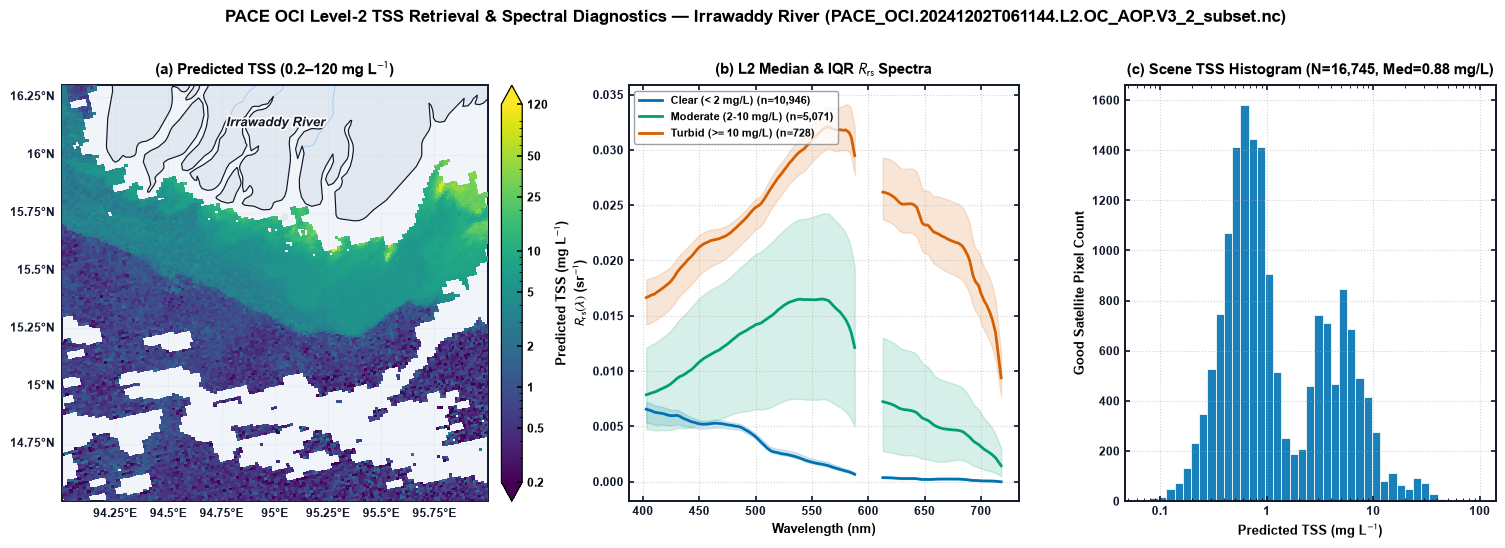

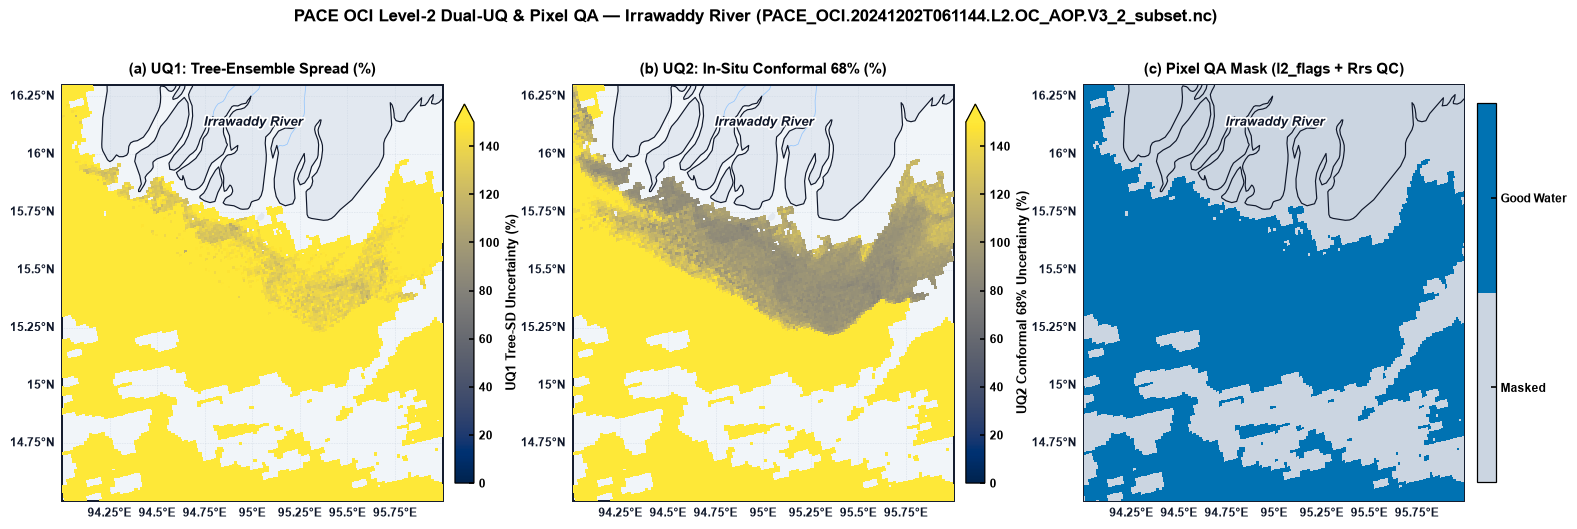

[STEP 13f] Saved Figure 1 & Figure 2 -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI_L2_TSS_Map_Spectra_Hist_20261121_235611.pdf | /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI_L2_UQ1_UQ2_QAMask_Maps_20261121_235611.pdf


In [13]:
# ==============================================================================
# STEP 13: PACE OCI LEVEL-2 (.nc) SATELLITE INFERENCE + DUAL-UQ + HIGH-RES MAPS
# ==============================================================================
# Sub-steps:
#   13a) Auto-install NetCDF/Cartopy dependencies & open SNAP gpt or NASA L2 .nc
#   13b) Decode l2_flags bitmask (preserving coastal/turbid plumes by default)
#   13c) Gap-aware vectorized spectral alignment onto 117 PACE bands + Rrs QC
#   13d) Extract 496 RF_Full_WithD2 features & run chunked 300-tree Dual-UQ inference
#   13e) Export predicted TSS + UQ NetCDF & CSV safely (bypassing OneDrive file locks)
#   13f) Plot Figure 1 (TSS 0.2-120 + Spectra + Hist) & Figure 2 (UQ1, UQ2, QA Mask)
# ==============================================================================
import os
import re as _re
import shutil as _shutil
import subprocess as _subprocess
import sys as _sys
import tempfile as _tempfile
import time
import urllib.request as _urllib_req

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patheffects as _pe
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.ticker import FuncFormatter
from scipy.ndimage import distance_transform_edt as _edt
from scipy.signal import savgol_filter

# Disable HDF5 POSIX file locking to prevent PermissionError on macOS OneDrive folders
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"


def _ensure_step13_packages():
    """
    Checks for xarray, netCDF4, h5netcdf, and cartopy in the active kernel
    and installs any missing packages automatically via pip.
    """
    req_pkgs = [
        ("xarray", "xarray"),
        ("netCDF4", "netCDF4"),
        ("h5netcdf", "h5netcdf"),
        ("cartopy", "cartopy"),
    ]
    missing = []
    for mod_name, pip_name in req_pkgs:
        try:
            __import__(mod_name)
        except ImportError:
            missing.append(pip_name)
    if missing:
        print(f"[STEP 13] Installing missing packages: {missing} ...")
        for pkg in missing:
            try:
                _subprocess.check_call([_sys.executable, "-m", "pip", "install", "-q", pkg])
                print(f"          Installed: {pkg}")
            except Exception as exc:
                print(f"          [WARN] Could not pip-install {pkg}: {exc}")


_ensure_step13_packages()
import xarray as xr

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    _HAS_CARTOPY_13 = True
except ImportError:
    _HAS_CARTOPY_13 = False


def _style_bold_axes(ax):
    """Applies bold spines and bold tick parameters for RSE publication figures."""
    for sp in ax.spines.values():
        sp.set_linewidth(1.4)
        sp.set_color("#0F172A")
    ax.tick_params(axis="both", which="major", labelsize=8.5, width=1.2, colors="#0F172A")
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight("bold")
    ax.xaxis.label.set_fontweight("bold")
    ax.yaxis.label.set_fontweight("bold")


def create_highres_map_axes(fig, grid_spec_slot, xlim, ylim, region_name="Irrawaddy River"):
    """
    Creates a tight regional map axes in Mercator projection centered on the scene
    to eliminate blank corner space, with 10m high-resolution coastlines, land/ocean
    boundaries, bold axes/labels, horizontal x-axis labels, and region annotation.
    """
    lon_c = 0.5 * (xlim[0] + xlim[1])
    if _HAS_CARTOPY_13:
        proj = ccrs.Mercator(central_longitude=lon_c)
        ax = fig.add_subplot(grid_spec_slot, projection=proj)
        ax.set_extent([xlim[0], xlim[1], ylim[0], ylim[1]], crs=ccrs.PlateCarree())
        ax.set_aspect("auto")  # fills subplot box cleanly without excess blank margins
        ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#F1F5F9", zorder=0)
        ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#E2E8F0", edgecolor="none", zorder=1)
        ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#93C5FD", linewidth=0.55, zorder=1.3)
        ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="#64748B", linewidth=0.60, zorder=1.6)
        ax.add_feature(cfeature.COASTLINE.with_scale("10m"), edgecolor="#0F172A", linewidth=0.85, zorder=4)

        gl = ax.gridlines(
            draw_labels=True,
            dms=False,
            x_inline=False,
            y_inline=False,
            linewidth=0.45,
            color="#CBD5E1",
            linestyle=":",
            zorder=5,
        )
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": 8.5, "weight": "bold", "color": "#0F172A", "rotation": 0}
        gl.ylabel_style = {"size": 8.5, "weight": "bold", "color": "#0F172A"}
        for sp in ax.spines.values():
            sp.set_linewidth(1.4)
            sp.set_color("#0F172A")

        if region_name:
            ax.text(
                0.50, 0.91, region_name,
                transform=ax.transAxes,
                ha="center", va="center",
                fontsize=9.5, fontweight="bold", fontstyle="italic", color="#0F172A",
                path_effects=[_pe.withStroke(linewidth=2.5, foreground="white")],
                zorder=6,
            )
        return ax, {"transform": ccrs.PlateCarree()}

    # GeoPandas 10m Natural Earth fallback
    try:
        import geopandas as gpd
        ne10_land = os.path.join(OUT_ROOT, "ne_10m_land.zip")
        if not os.path.exists(ne10_land):
            _urllib_req.urlretrieve(
                "https://naciscdn.org/naturalearth/10m/physical/ne_10m_land.zip",
                ne10_land,
            )
        gdf_10m = gpd.read_file(ne10_land)
        ax = fig.add_subplot(grid_spec_slot)
        ax.set_facecolor("#F1F5F9")
        gdf_10m.cx[xlim[0]-1:xlim[1]+1, ylim[0]-1:ylim[1]+1].plot(
            ax=ax, facecolor="#E2E8F0", edgecolor="#0F172A", linewidth=0.85, zorder=4
        )
        ax.set_xlim(xlim)
        ax.set_ylim(ylim)
        ax.grid(True, linestyle=":", linewidth=0.45, color="#CBD5E1", zorder=5)
        ax.set_xlabel("Longitude (°E)", fontsize=9.0, fontweight="bold")
        ax.set_ylabel("Latitude (°N)", fontsize=9.0, fontweight="bold")
        _style_bold_axes(ax)
        if region_name:
            ax.text(
                0.50, 0.91, region_name,
                transform=ax.transAxes,
                ha="center", va="center",
                fontsize=9.5, fontweight="bold", fontstyle="italic", color="#0F172A",
                path_effects=[_pe.withStroke(linewidth=2.5, foreground="white")],
                zorder=6,
            )
        return ax, {}
    except Exception:
        ax, kw = create_global_map_axes(fig, grid_spec_slot, xlim=xlim, ylim=ylim)
        _style_bold_axes(ax)
        return ax, kw


def extract_biooptical_features_from_rrs(R_in, wavelengths_nm=PACE_117_WAVELENGTHS):
    """
    Exact vectorized Step 4 feature extractor (496 RF_Full_WithD2 features) for satellite pixels.
    """
    R_raw = np.asarray(R_in, dtype=np.float64)
    if R_raw.ndim == 1:
        R_raw = R_raw[None, :]

    b_mask = wavelengths_nm <= 588.0
    r_mask = wavelengths_nm >= 613.0
    wl_b = wavelengths_nm[b_mask]
    wl_r = wavelengths_nm[r_mask]

    # 1. Gap-aware Savitzky-Golay smoothing per continuous segment
    R_smooth = np.empty_like(R_raw)
    d1 = np.empty_like(R_raw)
    d2 = np.empty_like(R_raw)

    R_b_sm = savgol_filter(R_raw[:, b_mask], window_length=7, polyorder=2, axis=1)
    R_r_sm = savgol_filter(R_raw[:, r_mask], window_length=7, polyorder=2, axis=1)
    R_smooth[:, b_mask] = R_b_sm
    R_smooth[:, r_mask] = R_r_sm

    # 2. First and second spectral derivatives per segment
    d1[:, b_mask] = np.gradient(R_b_sm, wl_b, axis=1)
    d1[:, r_mask] = np.gradient(R_r_sm, wl_r, axis=1)
    d2[:, b_mask] = np.gradient(d1[:, b_mask], wl_b, axis=1)
    d2[:, r_mask] = np.gradient(d1[:, r_mask], wl_r, axis=1)

    # 3. L2-normalized spectral shape
    l2_norm = np.linalg.norm(R_smooth, axis=1, keepdims=True)
    l2_norm = np.where(l2_norm > 1e-12, l2_norm, 1.0)
    R_l2 = R_smooth / l2_norm

    # 4. 28 Bio-optical band ratios, QAA u(lambda), line heights, and integrals
    eps = 1e-6
    Rp = np.maximum(R_smooth, eps)
    oc3_max_blue = np.maximum.reduce([Rp[:, IDX_443], Rp[:, IDX_490], Rp[:, IDX_510]])
    g0, g1 = 0.089, 0.1245
    rrs_sub = np.clip(R_smooth, -0.05, 0.25) / (0.52 + 1.7 * np.clip(R_smooth, -0.05, 0.25))
    u_665 = (-g0 + np.sqrt(np.maximum(g0**2 + 4 * g1 * rrs_sub[:, IDX_665], 0.0))) / (2 * g1)
    u_708 = (-g0 + np.sqrt(np.maximum(g0**2 + 4 * g1 * rrs_sub[:, IDX_708], 0.0))) / (2 * g1)

    peak_wl = wavelengths_nm[np.argmax(R_smooth, axis=1)]
    slope_red_nir = (R_smooth[:, IDX_713] - R_smooth[:, IDX_620]) / (713.0 - 620.0)
    _trapz_fn = getattr(np, "trapezoid", getattr(np, "trapz", None))
    m_b  = (wavelengths_nm >= 403) & (wavelengths_nm <= 490)
    m_g  = (wavelengths_nm >= 500) & (wavelengths_nm <= 588)
    m_r  = (wavelengths_nm >= 613) & (wavelengths_nm <= 718)
    m_re = (wavelengths_nm >= 685) & (wavelengths_nm <= 718)

    int_blue   = _trapz_fn(R_smooth[:, m_b], wavelengths_nm[m_b], axis=1)
    int_green  = _trapz_fn(R_smooth[:, m_g], wavelengths_nm[m_g], axis=1)
    int_rednir = _trapz_fn(R_smooth[:, m_r], wavelengths_nm[m_r], axis=1)
    int_re     = _trapz_fn(R_smooth[:, m_re], wavelengths_nm[m_re], axis=1)

    X_ratios = np.column_stack([
        np.log10(oc3_max_blue / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_443] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_490] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_413] / Rp[:, IDX_443]),
        np.log10(Rp[:, IDX_645] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_665] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_705] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_665] / Rp[:, IDX_490]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_443]),
        np.log10(Rp[:, IDX_705] / Rp[:, IDX_665]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_675]),
        np.log10(Rp[:, IDX_713] / Rp[:, IDX_665]),
        (R_smooth[:, IDX_665] - R_smooth[:, IDX_555]) / (np.abs(R_smooth[:, IDX_665]) + np.abs(R_smooth[:, IDX_555]) + eps),
        (R_smooth[:, IDX_708] - R_smooth[:, IDX_555]) / (np.abs(R_smooth[:, IDX_708]) + np.abs(R_smooth[:, IDX_555]) + eps),
        (R_smooth[:, IDX_708] - R_smooth[:, IDX_490]) / (np.abs(R_smooth[:, IDX_708]) + np.abs(R_smooth[:, IDX_490]) + eps),
        ((1.0 / Rp[:, IDX_665]) - (1.0 / Rp[:, IDX_705])) * Rp[:, IDX_713],
        R_smooth[:, IDX_705] - R_smooth[:, IDX_683] - ((R_smooth[:, IDX_713] - R_smooth[:, IDX_683]) * (22.0 / 30.0)),
        R_smooth[:, IDX_683] - R_smooth[:, IDX_665] - ((R_smooth[:, IDX_705] - R_smooth[:, IDX_665]) * (18.0 / 40.0)),
        R_smooth[:, IDX_555] - R_smooth[:, IDX_490] - ((R_smooth[:, IDX_620] - R_smooth[:, IDX_490]) * (65.0 / 130.0)),
        u_665, u_708, peak_wl, slope_red_nir,
        int_blue, int_green, int_rednir, int_re / (np.abs(int_green) + eps),
    ])
    X_ratios = np.nan_to_num(X_ratios, nan=0.0, posinf=0.0, neginf=0.0)
    return np.hstack([R_smooth, R_l2, d1, d2, X_ratios]).astype(np.float32)


def decode_l2_flags_mask(ds, exclude_flags=None):
    """
    Decodes ocean-color `l2_flags` bitmask using CF `flag_masks` and `flag_meanings`.
    Any pixel with a bit matching `exclude_flags` is marked True (masked).
    """
    if exclude_flags is None:
        exclude_flags = [
            "ATMFAIL", "LAND", "CLDICE", "HIGLINT", "HILT",
            "STRAYLIGHT", "NAVFAIL", "SEAICE", "BOWTIEDEL", "PRODFAIL",
            "MAXAERITER", "LOWLW", "HISATZEN", "HISOLZEN", "FILTER",
        ]
    if "l2_flags" not in ds:
        return None, {}

    flags_arr = ds["l2_flags"].to_numpy()
    valid_int = np.isfinite(flags_arr)
    flags_int = np.where(valid_int, flags_arr, 0).astype(np.int64)

    attrs = ds["l2_flags"].attrs
    masks = attrs.get("flag_masks", [])
    meanings = attrs.get("flag_meanings", "")
    if isinstance(meanings, str):
        meanings = meanings.split()

    is_masked = ~valid_int
    flag_counts = {}
    for m_val, name in zip(masks, meanings):
        hit = (flags_int & int(m_val)) != 0
        flag_counts[name] = int(hit.sum())
        if name in exclude_flags:
            is_masked |= hit
    return is_masked, flag_counts


def _interp_segment_vectorized(wl_src, R_src, wl_dst):
    """Fast vectorized 1D linear interpolation along axis=1 for monotonic wl_src -> wl_dst."""
    order = np.argsort(wl_src)
    x = wl_src[order]
    Y = R_src[:, order]
    idx = np.searchsorted(x, wl_dst, side="right") - 1
    idx = np.clip(idx, 0, len(x) - 2)
    x0 = x[idx]
    x1 = x[idx + 1]
    w = np.clip((wl_dst - x0) / np.maximum(x1 - x0, 1e-12), 0.0, 1.0)
    return Y[:, idx] * (1.0 - w[None, :]) + Y[:, idx + 1] * w[None, :]


def _safe_write_netcdf(out_ds, out_nc_path):
    """
    Writes NetCDF to a local /tmp staging file first, then copies to `out_nc_path`.
    Prevents macOS OneDrive / cloud-sync HDF5 file-locking PermissionError.
    """
    out_dir = os.path.dirname(out_nc_path)
    os.makedirs(out_dir, exist_ok=True)
    if os.path.exists(out_nc_path):
        try:
            os.remove(out_nc_path)
        except PermissionError:
            pass

    fd, tmp_nc = _tempfile.mkstemp(suffix=".nc")
    os.close(fd)
    try:
        wrote = False
        for _eng in ["h5netcdf", "netcdf4", None]:
            try:
                if _eng is None:
                    out_ds.to_netcdf(tmp_nc)
                else:
                    out_ds.to_netcdf(tmp_nc, engine=_eng)
                wrote = True
                break
            except Exception:
                continue
        if not wrote:
            raise RuntimeError("Failed to write temporary NetCDF with h5netcdf or netcdf4.")
        try:
            _shutil.copy2(tmp_nc, out_nc_path)
            return out_nc_path
        except PermissionError:
            fallback_nc = os.path.join(os.path.expanduser("~"), "Downloads", os.path.basename(out_nc_path))
            _shutil.copy2(tmp_nc, fallback_nc)
            print(f"[WARN] OneDrive blocked write to {out_nc_path}; saved instead to -> {fallback_nc}")
            return fallback_nc
    finally:
        if os.path.exists(tmp_nc):
            os.remove(tmp_nc)


def predict_tss_from_l2_nc(
    nc_path,
    bundle_path=bundle_latest_path,
    out_nc_path=None,
    out_csv_path=None,
    exclude_flags=None,
    chunk_size=25000,
):
    """
    Loads the saved Case 3b RF_Full_WithD2 bundle from disk and applies it + Dual-UQ
    directly to any PACE OCI Level-2 .nc file (SNAP gpt subset or NASA OB.DAAC L2).
    """
    t_start = time.time()
    bundle = load_case3b_tss_bundle(bundle_path)
    rf_m   = bundle["rf_model"]
    sc_m   = bundle["scaler"]
    wl_ref = bundle["wavelengths_nm"]
    uq_cfg = bundle["uq2_conformal"]

    # --- Step 13a: Open NetCDF (SNAP gpt flat Rrs_NNN or NASA OB.DAAC 3D Rrs) ---
    ds = None
    for _eng in ["netcdf4", "h5netcdf", None]:
        try:
            ds = xr.open_dataset(nc_path) if _eng is None else xr.open_dataset(nc_path, engine=_eng)
            break
        except Exception:
            continue
    if ds is None:
        raise RuntimeError(f"Could not open NetCDF file with netcdf4 or h5netcdf: {nc_path}")

    if "Rrs" in ds:
        rrs_da = ds["Rrs"]
        wl_dim = rrs_da.dims[-1]
        wl_nc = np.asarray(ds.coords.get(wl_dim, ds.get("wavelength_3d", np.arange(rrs_da.shape[-1]))), dtype=float)
        spatial_shape = rrs_da.shape[:-1]
        spatial_dims = list(rrs_da.dims[:-1])
        R_2d = rrs_da.to_numpy().reshape(-1, rrs_da.shape[-1])
        lat_2d = ds["latitude"].to_numpy() if "latitude" in ds else ds["lat"].to_numpy()
        lon_2d = ds["longitude"].to_numpy() if "longitude" in ds else ds["lon"].to_numpy()
    else:
        band_vars = []
        for k in ds.data_vars:
            m = _re.fullmatch(r"Rrs_(\d{3,4})", k)
            if m:
                wl_val = float(ds[k].attrs.get("radiation_wavelength", int(m.group(1))))
                band_vars.append((wl_val, k))
        band_vars.sort(key=lambda x: x[0])

        if not band_vars:
            ds_geo = xr.open_dataset(nc_path, group="geophysical_data")
            ds_nav = xr.open_dataset(nc_path, group="navigation_data")
            ds_sbp = xr.open_dataset(nc_path, group="sensor_band_parameters")
            rrs_da = ds_geo["Rrs"]
            wl_nc = np.asarray(ds_sbp["wavelength_3d"].to_numpy(), dtype=float)
            spatial_shape = rrs_da.shape[:-1]
            spatial_dims = list(rrs_da.dims[:-1])
            R_2d = rrs_da.to_numpy().reshape(-1, rrs_da.shape[-1])
            lat_2d = ds_nav["latitude"].to_numpy()
            lon_2d = ds_nav["longitude"].to_numpy()
            ds = ds_geo
        else:
            wl_nc = np.array([bw[0] for bw in band_vars], dtype=float)
            arrs = [ds[bw[1]].to_numpy().astype(np.float64) for bw in band_vars]
            spatial_shape = arrs[0].shape
            spatial_dims = list(ds[band_vars[0][1]].dims)
            R_2d = np.stack([a.ravel() for a in arrs], axis=1)
            lat_name = next((c for c in ["lat", "latitude", "Latitude"] if c in ds or c in ds.coords), None)
            lon_name = next((c for c in ["lon", "longitude", "Longitude"] if c in ds or c in ds.coords), None)
            lat_2d = ds[lat_name].to_numpy() if lat_name else np.full(spatial_shape, np.nan)
            lon_2d = ds[lon_name].to_numpy() if lon_name else np.full(spatial_shape, np.nan)

    print(f"[STEP 13a] Opened {os.path.basename(nc_path)} | grid={spatial_shape} | {len(wl_nc)} Rrs bands ({wl_nc.min():.1f}-{wl_nc.max():.1f} nm)")

    # --- Step 13b: Decode l2_flags & build quality mask ---
    flag_mask_2d, flag_counts = decode_l2_flags_mask(ds, exclude_flags=exclude_flags)
    if flag_mask_2d is not None:
        flag_mask_flat = flag_mask_2d.ravel()
        top_flags = ", ".join(f"{k}:{v}" for k, v in sorted(flag_counts.items(), key=lambda kv: -kv[1])[:10] if v > 0)
        print(f"[STEP 13b] Decoded l2_flags | Masked={flag_mask_flat.sum():,} / {flag_mask_flat.size:,} | Top flags: {top_flags}")
    else:
        flag_mask_flat = np.zeros(R_2d.shape[0], dtype=bool)
        flag_mask_2d = np.zeros(spatial_shape, dtype=bool)

    ds.close()

    # --- Step 13c: Gap-aware vectorized spectral alignment + physical Rrs QC ---
    b_src = wl_nc <= 589.5
    r_src = wl_nc >= 611.5
    b_dst = wl_ref <= 588.0
    r_dst = wl_ref >= 613.0

    R_117 = np.full((R_2d.shape[0], len(wl_ref)), np.nan, dtype=np.float64)
    finite_src = np.all(np.isfinite(R_2d[:, b_src]), axis=1) & np.all(np.isfinite(R_2d[:, r_src]), axis=1)
    vis_mask = (wl_nc >= 440.0) & (wl_nc <= 670.0)
    phys_qc = (np.nanmin(R_2d[:, vis_mask], axis=1) > -0.002) & (np.nanmax(R_2d[:, vis_mask], axis=1) < 0.25)

    valid_px = (
        (~flag_mask_flat)
        & finite_src
        & phys_qc
        & np.isfinite(lat_2d.ravel())
        & np.isfinite(lon_2d.ravel())
    )

    if valid_px.any():
        R_b_interp = _interp_segment_vectorized(wl_nc[b_src], R_2d[valid_px][:, b_src], wl_ref[b_dst])
        R_r_interp = _interp_segment_vectorized(wl_nc[r_src], R_2d[valid_px][:, r_src], wl_ref[r_dst])
        R_117[np.ix_(valid_px, b_dst)] = R_b_interp
        R_117[np.ix_(valid_px, r_dst)] = R_r_interp

    print(f"[STEP 13c] Gap-aware alignment & QC complete | Good water pixels: {valid_px.sum():,} ({100.0*valid_px.mean():.1f}%)")

    # --- Step 13d: Chunked 496-feature extraction & 300-tree Dual-UQ inference ---
    n_px = len(R_117)
    pred_lin = np.full(n_px, np.nan, dtype=np.float32)
    uq1_rel  = np.full(n_px, np.nan, dtype=np.float32)
    uq2_rel  = np.full(n_px, np.nan, dtype=np.float32)
    uq2_lo68 = np.full(n_px, np.nan, dtype=np.float32)
    uq2_hi68 = np.full(n_px, np.nan, dtype=np.float32)
    uq2_lo95 = np.full(n_px, np.nan, dtype=np.float32)
    uq2_hi95 = np.full(n_px, np.nan, dtype=np.float32)

    valid_idx = np.where(valid_px)[0]
    for s_i in range(0, len(valid_idx), chunk_size):
        chunk_idx = valid_idx[s_i : s_i + chunk_size]
        X_feat = extract_biooptical_features_from_rrs(R_117[chunk_idx], wl_ref)
        X_sc   = sc_m.transform(X_feat)
        tree_p = np.column_stack([est.predict(X_sc) for est in rf_m.estimators_])
        m_log  = np.mean(tree_p, axis=1)
        sd_log = np.std(tree_p, axis=1, ddof=1)
        hw68   = uq_cfg["q68_mult"] * (sd_log + uq_cfg["eps0"])
        hw95   = uq_cfg["q95_mult"] * (sd_log + uq_cfg["eps0"])

        pred_lin[chunk_idx] = (10.0 ** m_log).astype(np.float32)
        uq1_rel[chunk_idx]  = (100.0 * (10.0 ** sd_log - 1.0)).astype(np.float32)
        uq2_rel[chunk_idx]  = (100.0 * (10.0 ** hw68 - 1.0)).astype(np.float32)
        uq2_lo68[chunk_idx] = (10.0 ** (m_log - hw68)).astype(np.float32)
        uq2_hi68[chunk_idx] = (10.0 ** (m_log + hw68)).astype(np.float32)
        uq2_lo95[chunk_idx] = (10.0 ** (m_log - hw95)).astype(np.float32)
        uq2_hi95[chunk_idx] = (10.0 ** (m_log + hw95)).astype(np.float32)

    # --- Step 13e: Package xarray Dataset & export NetCDF/CSV safely ---
    out_ds = xr.Dataset(
        {
            "TSS_pred":         (spatial_dims, pred_lin.reshape(spatial_shape), {"units": "mg L^-1", "long_name": "Predicted Total Suspended Solids (Case 3b RF_Full_WithD2)"}),
            "TSS_UQ1_RelUnc":   (spatial_dims, uq1_rel.reshape(spatial_shape),  {"units": "%", "long_name": "UQ1 Tree-Ensemble Relative Uncertainty"}),
            "TSS_UQ2_RelUnc":   (spatial_dims, uq2_rel.reshape(spatial_shape),  {"units": "%", "long_name": "UQ2 In-Situ Conformal 68% Relative Uncertainty"}),
            "TSS_UQ2_Low68":    (spatial_dims, uq2_lo68.reshape(spatial_shape), {"units": "mg L^-1"}),
            "TSS_UQ2_High68":   (spatial_dims, uq2_hi68.reshape(spatial_shape), {"units": "mg L^-1"}),
            "TSS_UQ2_Low95":    (spatial_dims, uq2_lo95.reshape(spatial_shape), {"units": "mg L^-1"}),
            "TSS_UQ2_High95":   (spatial_dims, uq2_hi95.reshape(spatial_shape), {"units": "mg L^-1"}),
            "valid_water_mask": (spatial_dims, valid_px.reshape(spatial_shape).astype(np.int8)),
        },
        coords={
            "lat": (spatial_dims, lat_2d),
            "lon": (spatial_dims, lon_2d),
        },
        attrs={
            "source_l2_file": os.path.basename(nc_path),
            "model_bundle": os.path.basename(bundle_path),
            "model_name": bundle["model_name"],
        },
    )

    if out_nc_path:
        saved_nc = _safe_write_netcdf(out_ds, out_nc_path)
        print(f"[STEP 13e] Saved L2 TSS + Dual-UQ NetCDF -> {saved_nc}")
    if out_csv_path:
        os.makedirs(os.path.dirname(out_csv_path), exist_ok=True)
        out_ds.to_dataframe().dropna(subset=["TSS_pred"]).reset_index().to_csv(out_csv_path, index=False)
        print(f"[STEP 13e] Saved valid-pixel CSV          -> {out_csv_path}")

    med_str = f"{np.nanmedian(pred_lin):.2f} mg/L" if np.isfinite(pred_lin).any() else "N/A (0 valid pixels)"
    print(f"[STEP 13d] Inference finished in {time.time() - t_start:.2f}s | Median TSS = {med_str}")
    return out_ds, R_117[valid_px], pred_lin[valid_px], lat_2d, lon_2d, (flag_mask_2d | (~valid_px.reshape(spatial_shape)))


def plot_pace_l2_tss_maps(
    out_ds,
    lat_2d,
    lon_2d,
    qa_masked_2d,
    R_valid,
    tss_valid,
    out_dir,
    run_ts,
    lon_lim=(94.0000, 96.0000),
    lat_lim=(14.5000, 16.3000),
    region_name="Irrawaddy River",
):
    """
    Step 13f: Reorganized RSE-grade, color-blind-friendly figures:
      Figure 1 (1x3):
        (a) Predicted TSS map (0.2-120 mg/L, extend='both', viridis, Irrawaddy River)
        (b) L2 Median & IQR Rrs spectra by predicted TSS regime (Okabe-Ito)
        (c) L2 Scene TSS distribution histogram
      Figure 2 (1x3):
        (a) UQ1 Tree-SD (%) using shared 'cividis' palette
        (b) UQ2 Conformal 68% (%) using shared 'cividis' palette
        (c) Pixel QA Mask (Okabe-Ito Blue vs Slate)
    """
    os.makedirs(out_dir, exist_ok=True)
    xlim = tuple(lon_lim) if lon_lim is not None else (float(np.nanmin(lon_2d)), float(np.nanmax(lon_2d)))
    ylim = tuple(lat_lim) if lat_lim is not None else (float(np.nanmin(lat_2d)), float(np.nanmax(lat_2d)))

    tss_2d = out_ds["TSS_pred"].to_numpy()
    uq1_2d = out_ds["TSS_UQ1_RelUnc"].to_numpy()
    uq2_2d = out_ds["TSS_UQ2_RelUnc"].to_numpy()
    qa_2d  = np.where(np.isfinite(tss_2d), 1.0, np.where(qa_masked_2d, 0.0, np.nan))

    # Fill any swath-edge NaNs in lat/lon coordinates so pcolormesh renders cleanly
    if not (np.all(np.isfinite(lon_2d)) and np.all(np.isfinite(lat_2d))):
        _bad_ll = ~(np.isfinite(lon_2d) & np.isfinite(lat_2d))
        if _bad_ll.any() and (~_bad_ll).any():
            _, _idx = _edt(_bad_ll, return_distances=True, return_indices=True)
            lon_2d = lon_2d[tuple(_idx)]
            lat_2d = lat_2d[tuple(_idx)]

    # ==========================================================================
    # FIGURE 1: (a) Predicted TSS Map (0.2-120 mg/L) + (b) Rrs Spectra + (c) Hist
    # ==========================================================================
    fig1 = plt.figure(figsize=(18.5, 5.4))
    gs1 = fig1.add_gridspec(1, 3, width_ratios=[1.18, 1.0, 0.95], wspace=0.26)

    # Panel (a): Predicted TSS (0.2 to 120 mg/L, extend='both', viridis)
    ax1a, kw1a = create_highres_map_axes(fig1, gs1[0, 0], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_tss = plt.get_cmap("viridis").copy()
    cmap_tss.set_bad(alpha=0.0)
    tss_ticks = [0.2, 0.5, 1, 2, 5, 10, 25, 50, 120]
    norm_tss = LogNorm(vmin=0.2, vmax=120.0)
    tss_plot = np.ma.masked_invalid(np.where(np.isfinite(tss_2d), np.clip(tss_2d, 0.2, 120.0), np.nan))
    pm_1a = ax1a.pcolormesh(lon_2d, lat_2d, tss_plot, cmap=cmap_tss, norm=norm_tss, shading="auto", zorder=3, **kw1a)
    cb_1a = fig1.colorbar(pm_1a, ax=ax1a, fraction=0.046, pad=0.03, extend="both")
    cb_1a.set_ticks(tss_ticks)
    cb_1a.set_ticklabels([str(t) for t in tss_ticks])
    cb_1a.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_1a.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    cb_1a.set_label("Predicted TSS (mg L$^{-1}$)", fontsize=9.5, fontweight="bold")
    ax1a.set_title("(a) Predicted TSS (0.2–120 mg L$^{-1}$)", fontsize=10.5, fontweight="bold", pad=8)

    # Panel (b): L2 Median & IQR Rrs Spectra by Predicted TSS Regime (Okabe-Ito)
    ax1b = fig1.add_subplot(gs1[0, 1])
    regimes = [
        ("Clear (< 2 mg/L)",     tss_valid < 2.0, "#0072B2"),                        # Okabe-Ito Blue
        ("Moderate (2-10 mg/L)", (tss_valid >= 2.0) & (tss_valid < 10.0), "#009E73"),# Okabe-Ito Bluish-Green
        ("Turbid (>= 10 mg/L)",  tss_valid >= 10.0, "#D55E00"),                      # Okabe-Ito Vermilion
    ]
    wl_b = PACE_117_WAVELENGTHS[BLUE_MASK]
    wl_r = PACE_117_WAVELENGTHS[RED_MASK]
    for r_label, r_mask, r_col in regimes:
        if r_mask.sum() < 5:
            continue
        med_spec = np.nanmedian(R_valid[r_mask], axis=0)
        q25_spec = np.nanpercentile(R_valid[r_mask], 25, axis=0)
        q75_spec = np.nanpercentile(R_valid[r_mask], 75, axis=0)
        ax1b.plot(wl_b, med_spec[BLUE_MASK], color=r_col, lw=2.0, label=f"{r_label} (n={r_mask.sum():,})")
        ax1b.plot(wl_r, med_spec[RED_MASK], color=r_col, lw=2.0)
        ax1b.fill_between(wl_b, q25_spec[BLUE_MASK], q75_spec[BLUE_MASK], color=r_col, alpha=0.16)
        ax1b.fill_between(wl_r, q25_spec[RED_MASK], q75_spec[RED_MASK], color=r_col, alpha=0.16)
    ax1b.set_xlabel("Wavelength (nm)", fontsize=9.5, fontweight="bold")
    ax1b.set_ylabel(r"$R_{\mathrm{rs}}(\lambda)$ (sr$^{-1}$)", fontsize=9.5, fontweight="bold")
    ax1b.set_title(r"(b) L2 Median & IQR $R_{\mathrm{rs}}$ Spectra", fontsize=10.5, fontweight="bold", pad=8)
    leg1b = ax1b.legend(frameon=True, fontsize=8.5, prop={"weight": "bold", "size": 8.2})
    leg1b.get_frame().set_linewidth(1.0)
    ax1b.grid(True, linestyle=":", alpha=0.55)
    _style_bold_axes(ax1b)

    # Panel (c): L2 Scene TSS Distribution Histogram
    ax1c = fig1.add_subplot(gs1[0, 2])
    tss_pos = tss_valid[np.isfinite(tss_valid) & (tss_valid > 0)]
    if len(tss_pos) > 0:
        bins_log = np.logspace(np.log10(max(0.05, tss_pos.min())), np.log10(min(500.0, tss_pos.max() * 1.1)), 42)
        ax1c.hist(tss_pos, bins=bins_log, color="#0072B2", edgecolor="white", linewidth=0.6, alpha=0.90)
        ax1c.set_xscale("log")
        ax1c.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))
        ax1c.set_title(
            f"(c) Scene TSS Histogram (N={len(tss_pos):,}, Med={np.median(tss_pos):.2f} mg/L)",
            fontsize=10.5, fontweight="bold", pad=8
        )
    else:
        ax1c.set_title("(c) Scene TSS Histogram (N=0 valid pixels)", fontsize=10.5, fontweight="bold", pad=8)
    ax1c.set_xlabel("Predicted TSS (mg L$^{-1}$)", fontsize=9.5, fontweight="bold")
    ax1c.set_ylabel("Good Satellite Pixel Count", fontsize=9.5, fontweight="bold")
    ax1c.grid(True, linestyle=":", alpha=0.55)
    _style_bold_axes(ax1c)

    fig1.suptitle(
        f"PACE OCI Level-2 TSS Retrieval & Spectral Diagnostics — {region_name} ({out_ds.attrs.get('source_l2_file', '')})",
        fontsize=12.0, fontweight="bold", y=1.02
    )
    fig1_pdf = os.path.join(out_dir, f"PACE_OCI_L2_TSS_Map_Spectra_Hist_{run_ts}.pdf")
    fig1.savefig(fig1_pdf, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()

    # ==========================================================================
    # FIGURE 2: (a) UQ1 (%) + (b) UQ2 (%) [Single Shared Palette] + (c) QA Mask
    # ==========================================================================
    fig2 = plt.figure(figsize=(18.5, 5.4))
    gs2 = fig2.add_gridspec(1, 3, wspace=0.24)
    uq_cmap_name = "cividis"  # single CVD-safe & grayscale-safe palette for both UQ1 and UQ2

    # Panel (a): UQ1 Tree-Ensemble Spread (%)
    ax2a, kw2a = create_highres_map_axes(fig2, gs2[0, 0], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_uq1 = plt.get_cmap(uq_cmap_name).copy()
    cmap_uq1.set_bad(alpha=0.0)
    uq1_plot = np.ma.masked_invalid(np.where(np.isfinite(uq1_2d), np.clip(uq1_2d, 0, 150), np.nan))
    pm_2a = ax2a.pcolormesh(lon_2d, lat_2d, uq1_plot, cmap=cmap_uq1, vmin=0, vmax=150, shading="auto", zorder=3, **kw2a)
    cb_2a = fig2.colorbar(pm_2a, ax=ax2a, fraction=0.046, pad=0.03, extend="max")
    cb_2a.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_2a.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    cb_2a.set_label("UQ1 Tree-SD Uncertainty (%)", fontsize=9.5, fontweight="bold")
    ax2a.set_title("(a) UQ1: Tree-Ensemble Spread (%)", fontsize=10.5, fontweight="bold", pad=8)

    # Panel (b): UQ2 In-Situ Conformal 68% Interval (%) — same 'cividis' palette
    ax2b, kw2b = create_highres_map_axes(fig2, gs2[0, 1], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_uq2 = plt.get_cmap(uq_cmap_name).copy()
    cmap_uq2.set_bad(alpha=0.0)
    uq2_plot = np.ma.masked_invalid(np.where(np.isfinite(uq2_2d), np.clip(uq2_2d, 0, 150), np.nan))
    pm_2b = ax2b.pcolormesh(lon_2d, lat_2d, uq2_plot, cmap=cmap_uq2, vmin=0, vmax=150, shading="auto", zorder=3, **kw2b)
    cb_2b = fig2.colorbar(pm_2b, ax=ax2b, fraction=0.046, pad=0.03, extend="max")
    cb_2b.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_2b.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    cb_2b.set_label("UQ2 Conformal 68% Uncertainty (%)", fontsize=9.5, fontweight="bold")
    ax2b.set_title("(b) UQ2: In-Situ Conformal 68% (%)", fontsize=10.5, fontweight="bold", pad=8)

    # Panel (c): Pixel QA Mask (Okabe-Ito Blue #0072B2 vs Neutral Slate #CBD5E1)
    ax2c, kw2c = create_highres_map_axes(fig2, gs2[0, 2], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_qa = ListedColormap(["#CBD5E1", "#0072B2"])
    cmap_qa.set_bad(alpha=0.0)
    qa_plot = np.ma.masked_invalid(qa_2d)
    pm_2c = ax2c.pcolormesh(lon_2d, lat_2d, qa_plot, cmap=cmap_qa, vmin=-0.5, vmax=1.5, shading="auto", zorder=3, **kw2c)
    cb_2c = fig2.colorbar(pm_2c, ax=ax2c, fraction=0.046, pad=0.03, ticks=[0, 1])
    cb_2c.set_ticklabels(["Masked", "Good Water"])
    cb_2c.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_2c.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    ax2c.set_title("(c) Pixel QA Mask (l2_flags + Rrs QC)", fontsize=10.5, fontweight="bold", pad=8)

    fig2.suptitle(
        f"PACE OCI Level-2 Dual-UQ & Pixel QA — {region_name} ({out_ds.attrs.get('source_l2_file', '')})",
        fontsize=12.0, fontweight="bold", y=1.02
    )
    fig2_pdf = os.path.join(out_dir, f"PACE_OCI_L2_UQ1_UQ2_QAMask_Maps_{run_ts}.pdf")
    fig2.savefig(fig2_pdf, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"[STEP 13f] Saved Figure 1 & Figure 2 -> {fig1_pdf} | {fig2_pdf}")


# --- Run Step 13 on the PACE OCI L2 .nc file ---
L2_NC_FILE = "/Users/masud/OneDrive02/MODIS_manuscript/StCruise26/PACE_3_2/Irrawady/PACE_OCI.20241202T061144.L2.OC_AOP.V3_2_subset.nc"
os.makedirs(DIR_L2_INFERENCE, exist_ok=True)

# Irrawaddy River exact map bounds
IRRAWADDY_LON_LIM = (94.0000, 96.0000)
IRRAWADDY_LAT_LIM = (14.5000, 16.3000)

# Option 3: Explicitly configure which l2_flags to mask
all_pace_flags = [
    # --- Fatal / contaminated pixels (KEEP masked) ---
    "ATMFAIL", "LAND", "CLDICE", "HIGLINT", "HILT",
    "STRAYLIGHT", "NAVFAIL", "SEAICE", "BOWTIEDEL", "PRODFAIL",
    "MAXAERITER", "LOWLW", "HISATZEN", "HISOLZEN", "FILTER",

    # --- Coastal / turbid / soft-warning flags (UNCOMMENT ONLY if you want to mask them) ---
    # "COASTZ", "TURBIDW", "CHLFAIL", "CHLWARN", "COCCOLITH",
    # "PRODWARN", "ATMWARN", "ABSAER", "HIPOL", "NAVWARN", "MODGLINT",
]

if os.path.exists(L2_NC_FILE):
    out_nc  = os.path.join(DIR_L2_INFERENCE, f"PACE_OCI_20241202T061144_TSS_WithDualUQ_{RUN_TS}.nc")
    out_csv = os.path.join(DIR_L2_INFERENCE, f"PACE_OCI_20241202T061144_TSS_WithDualUQ_{RUN_TS}.csv")
    ds_tss, R_val, tss_val, lat2d, lon2d, qa_mask2d = predict_tss_from_l2_nc(
        nc_path=L2_NC_FILE,
        bundle_path=bundle_latest_path,
        out_nc_path=out_nc,
        out_csv_path=out_csv,
        exclude_flags=all_pace_flags,
    )
    plot_pace_l2_tss_maps(
        ds_tss, lat2d, lon2d, qa_mask2d, R_val, tss_val,
        DIR_L2_INFERENCE, RUN_TS,
        lon_lim=IRRAWADDY_LON_LIM,
        lat_lim=IRRAWADDY_LAT_LIM,
        region_name="Irrawaddy River",
    )
else:
    print(f"[WARN] File not found: {L2_NC_FILE}")

In [1]:
## BoB: /Users/masud/OneDrive02/MODIS_manuscript/StCruise26/PACE_3_2/BoB/PACE_OCI.20241012T063653.L2.OC_AOP.V3_2_subset.nc

[STEP 13a] Opened PACE_OCI.20250209T064624.L2.OC_AOP.V3_2_subset.nc | grid=(505, 858) | 172 Rrs bands (346.0-719.3 nm) | lat=[16.09, 23.76], lon=[82.17, 94.70]
[STEP 13b] Decoded l2_flags | Masked=234,852 / 433,290 | Top flags: PRODFAIL:224152, ABSAER:209138, LAND:152043, CLDICE:79404, PRODWARN:67327, COASTZ:50228, STRAYLIGHT:37781, TURBIDW:22916, OPSHAL:13023, COCCOLITH:2138
[STEP 13c] Gap-aware alignment & QC complete | Good water pixels: 198,438 (45.8%)
[STEP 13e] Saved L2 TSS + Dual-UQ NetCDF -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI.20250209T064624.L2.OC_AOP.V3_2_subset_TSS_WithDualUQ_20261123_112820.nc
[STEP 13e] Saved valid-pixel CSV          -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI.20250209T064624.L2.OC_AOP.V3_2_subset_TSS_WithDualUQ_20261123_112820.csv
[STEP 1

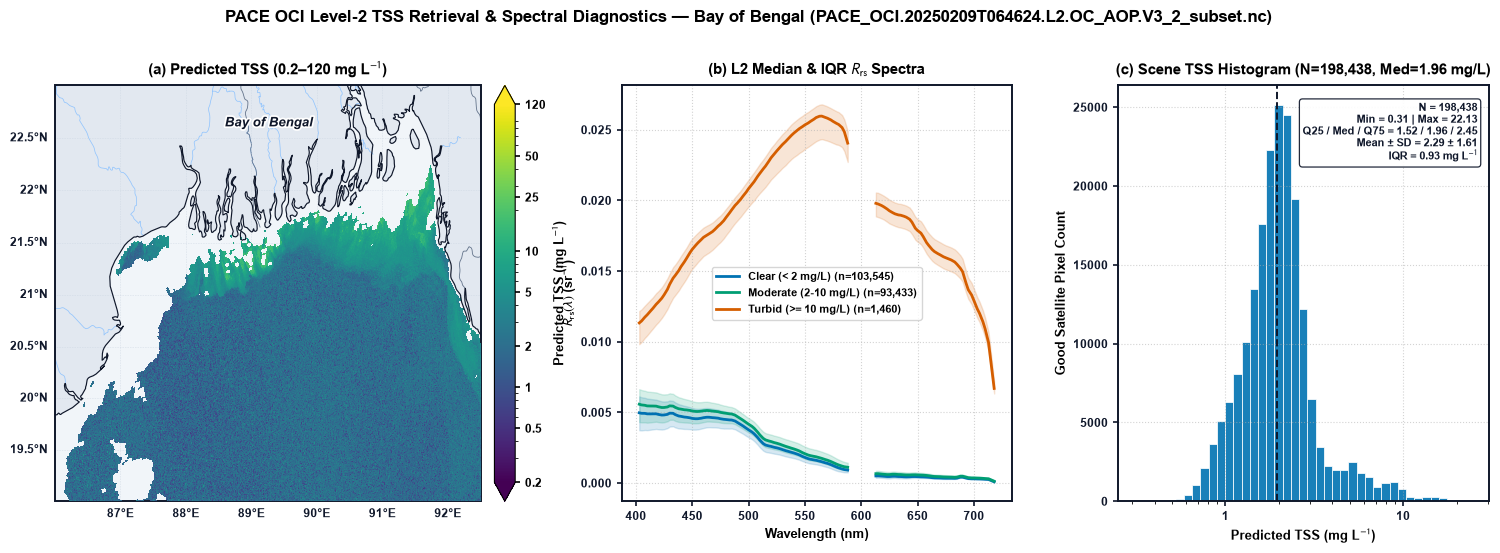

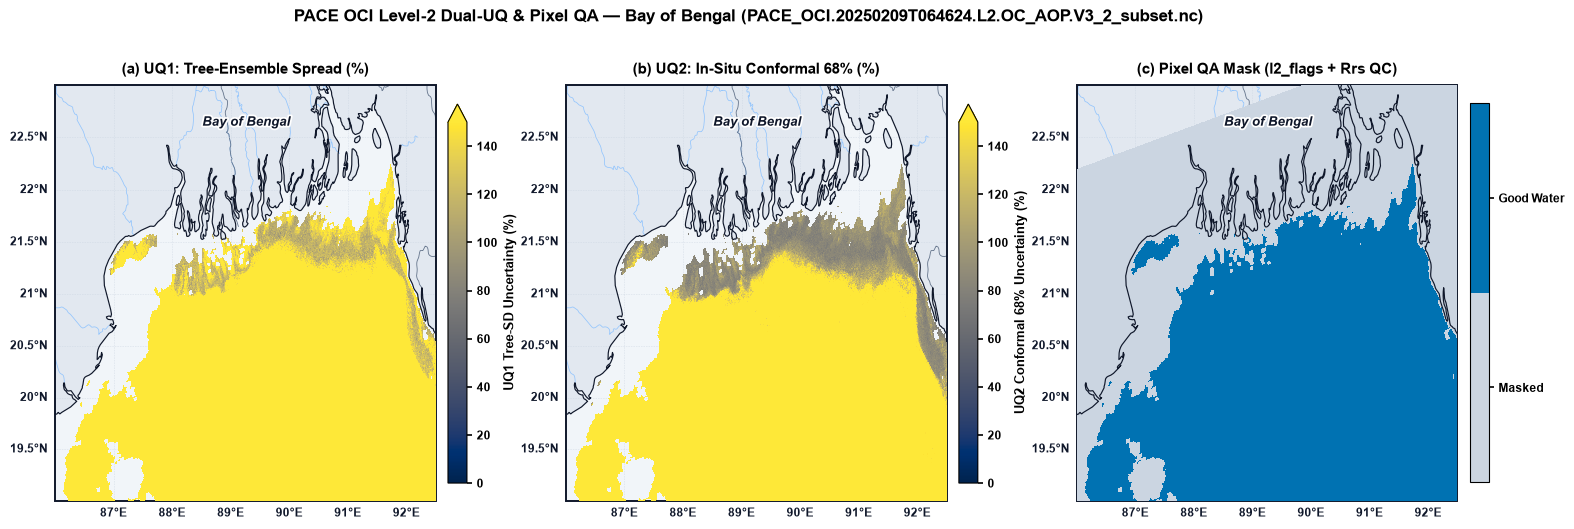

[STEP 13f] Saved Figure 1 & Figure 2 -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI.20250209T064624.L2.OC_AOP.V3_2_subset_TSS_Map_Spectra_Hist_20261123_112820.pdf | /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI.20250209T064624.L2.OC_AOP.V3_2_subset_UQ1_UQ2_QAMask_Maps_20261123_112820.pdf


In [7]:
# ==============================================================================
# STEP 13 (100% STANDALONE): PACE OCI LEVEL-2 (.nc) INFERENCE + DUAL-UQ + MAPS
# ==============================================================================
# Purpose:
#   Applies the pre-trained Case 3b Random Forest model (RF_Full_WithD2) and
#   In-Situ-calibrated Dual Uncertainty Quantification (UQ1 + UQ2) directly to
#   any PACE OCI Level-2 .nc file (SNAP gpt subset or NASA OB.DAAC L2) without
#   requiring Steps 1–12 to be executed in the current kernel.
#
# Sub-steps:
#   13.0) Standalone fallback definitions (wavelengths, band indices, bundle loader)
#   13a)  Auto-install NetCDF/Cartopy dependencies & open SNAP gpt or NASA L2 .nc
#   13b)  Decode l2_flags bitmask (preserving coastal/turbid plumes by default)
#   13c)  Gap-aware vectorized spectral alignment onto 117 PACE bands + Rrs QC
#   13d)  Extract 496 RF_Full_WithD2 features & run chunked 300-tree Dual-UQ inference
#   13e)  Export predicted TSS + Dual-UQ NetCDF & CSV safely (bypassing file locks)
#   13f)  Plot Figure 1 (TSS 0.2-120 + Spectra + Stats Hist) & Figure 2 (UQ1, UQ2, QA)
# ==============================================================================
import os
import pickle as _pickle
import re as _re
import shutil as _shutil
import subprocess as _subprocess
import sys as _sys
import tempfile as _tempfile
import time
import urllib.request as _urllib_req
from datetime import datetime as _dt

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as _pe
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.ticker import FuncFormatter
from scipy.ndimage import distance_transform_edt as _edt
from scipy.signal import savgol_filter

# WHY: Cloud-synced folders (OneDrive/Dropbox) on macOS can lock HDF5 files during
#      NetCDF reads/writes and raise PermissionError.
# HOW: Disable HDF5 POSIX file locking at the process level before importing NetCDF libs.
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

# ------------------------------------------------------------------------------
# STEP 13.0: STANDALONE FALLBACK DEFINITIONS (SO STEP 13 RUNS WITHOUT STEPS 1–12)
# ------------------------------------------------------------------------------
# WHY: Allows you to open a fresh notebook/kernel and run only Step 13 on a new .nc file.
# HOW: Each variable is guarded with `not in globals()` so it reuses Steps 1–12 values
#      if they exist, or initializes identical canonical values if running standalone.
if "RUN_TS" not in globals():
    RUN_TS = _dt.now().strftime("%Y%m%d_%H%M%S")

if "OUT_ROOT" not in globals():
    _cwd = os.getcwd()
    _folder = "RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2"
    OUT_ROOT = _cwd if os.path.basename(_cwd) == _folder else os.path.join(_cwd, _folder)

if "DIR_SAVED_MODEL" not in globals():
    DIR_SAVED_MODEL = os.path.join(OUT_ROOT, "08_saved_model_bundle")

if "DIR_L2_INFERENCE" not in globals():
    DIR_L2_INFERENCE = os.path.join(OUT_ROOT, "09_pace_l2_nc_inference_and_maps")

os.makedirs(OUT_ROOT, exist_ok=True)
os.makedirs(DIR_L2_INFERENCE, exist_ok=True)

# Canonical 117 NASA PACE OCI bands (403–718 nm), preserving the 588–613 nm dichroic gap
if "PACE_117_WAVELENGTHS" not in globals():
    PACE_117_WAVELENGTHS = np.array([
        403, 405, 408, 410, 413, 415, 418, 420, 423, 425, 428, 430, 433, 435, 438,
        440, 443, 445, 448, 450, 453, 455, 458, 460, 463, 465, 468, 470, 473, 475,
        478, 480, 483, 485, 488, 490, 493, 495, 498, 500, 503, 505, 508, 510, 513,
        515, 518, 520, 523, 525, 528, 530, 533, 535, 538, 540, 543, 545, 548, 550,
        553, 555, 558, 560, 563, 565, 568, 570, 573, 575, 578, 580, 583, 585, 588,
        613, 615, 618, 620, 623, 625, 628, 630, 633, 635, 638, 640, 643, 645, 648,
        650, 653, 655, 658, 660, 663, 665, 668, 670, 673, 675, 678, 680, 683, 685,
        688, 690, 693, 695, 698, 700, 703, 705, 708, 710, 713, 718
    ], dtype=float)
    BLUE_MASK = PACE_117_WAVELENGTHS <= 588.0  # 75 Blue-Green bands (403-588 nm)
    RED_MASK  = PACE_117_WAVELENGTHS >= 613.0  # 42 Red-NIR bands (613-718 nm)

# Key diagnostic band indices for bio-optical ratios, QAA, FLH, and MCI
if "IDX_413" not in globals():
    def _band_idx_13(wl):
        return int(np.argmin(np.abs(PACE_117_WAVELENGTHS - wl)))
    IDX_413, IDX_443, IDX_490, IDX_510, IDX_555 = (
        _band_idx_13(413), _band_idx_13(443), _band_idx_13(490), _band_idx_13(510), _band_idx_13(555)
    )
    IDX_620, IDX_645, IDX_665, IDX_675, IDX_683, IDX_705, IDX_708, IDX_713 = (
        _band_idx_13(620), _band_idx_13(645), _band_idx_13(665), _band_idx_13(675),
        _band_idx_13(683), _band_idx_13(705), _band_idx_13(708), _band_idx_13(713),
    )

# RSE Journal Matplotlib Configuration (TrueType fonts editable in Illustrator)
mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
})

try:
    import joblib as _joblib
    _HAS_JOBLIB_13 = True
except ImportError:
    _HAS_JOBLIB_13 = False

# Auto-locate the saved Step 12 model bundle (.joblib or .pkl)
if "bundle_latest_path" not in globals():
    _cand_bundles = [
        os.path.join(DIR_SAVED_MODEL, "Case3b_RF_Full_WithD2_ModelBundle_LATEST.joblib"),
        os.path.join(DIR_SAVED_MODEL, "Case3b_RF_Full_WithD2_ModelBundle_LATEST.pkl"),
        os.path.join(os.getcwd(), "08_saved_model_bundle", "Case3b_RF_Full_WithD2_ModelBundle_LATEST.joblib"),
        os.path.join(os.getcwd(), "Case3b_RF_Full_WithD2_ModelBundle_LATEST.joblib"),
    ]
    bundle_latest_path = next((p for p in _cand_bundles if os.path.exists(p)), _cand_bundles[0])

if "load_case3b_tss_bundle" not in globals():
    def load_case3b_tss_bundle(bundle_path=bundle_latest_path):
        """Loads the saved Case 3b RF_Full_WithD2 bundle from disk without retraining."""
        if not os.path.exists(bundle_path):
            raise FileNotFoundError(
                f"Saved model bundle not found at:\n  {bundle_path}\n"
                "Run Step 12 once to generate it, or set BUNDLE_PATH to your .joblib/.pkl file."
            )
        if bundle_path.endswith(".joblib") and _HAS_JOBLIB_13:
            return _joblib.load(bundle_path)
        with open(bundle_path, "rb") as f_in:
            return _pickle.load(f_in)


# ------------------------------------------------------------------------------
# STEP 13a (HELPER): PACKAGE CHECK & AUTO-INSTALL
# ------------------------------------------------------------------------------
def _ensure_step13_packages():
    """
    WHY: Satellite NetCDF I/O and map projections require xarray, netCDF4, h5netcdf,
         and cartopy, which may not be pre-installed in every Python environment.
    HOW: Probes each module and quietly pip-installs any missing package once.
    """
    req_pkgs = [
        ("xarray", "xarray"),
        ("netCDF4", "netCDF4"),
        ("h5netcdf", "h5netcdf"),
        ("cartopy", "cartopy"),
    ]
    missing = []
    for mod_name, pip_name in req_pkgs:
        try:
            __import__(mod_name)
        except ImportError:
            missing.append(pip_name)
    if missing:
        print(f"[STEP 13] Installing missing packages: {missing} ...")
        for pkg in missing:
            try:
                _subprocess.check_call([_sys.executable, "-m", "pip", "install", "-q", pkg])
                print(f"          Installed: {pkg}")
            except Exception as exc:
                print(f"          [WARN] Could not pip-install {pkg}: {exc}")


_ensure_step13_packages()
import xarray as xr

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    _HAS_CARTOPY_13 = True
except ImportError:
    _HAS_CARTOPY_13 = False


# ------------------------------------------------------------------------------
# STEP 13f (HELPER): HIGH-RES VECTOR MAP & BOLD AXES STYLING
# ------------------------------------------------------------------------------
def _style_bold_axes(ax):
    """Applies bold spines and bold tick labels for RSE publication figures."""
    for sp in ax.spines.values():
        sp.set_linewidth(1.4)
        sp.set_color("#0F172A")
    ax.tick_params(axis="both", which="major", labelsize=8.5, width=1.2, colors="#0F172A")
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight("bold")
    ax.xaxis.label.set_fontweight("bold")
    ax.yaxis.label.set_fontweight("bold")


def create_highres_map_axes(fig, grid_spec_slot, xlim, ylim, region_name=None):
    """
    WHY: Estuarine/coastal satellite maps require crisp 10m coastlines, land/ocean
         contrast, and minimal blank corner space across arbitrary geographic regions.
    HOW: Uses Cartopy Mercator centered on `xlim` (or PlateCarree above ±80° lat) with
         `aspect="auto"` to fill the subplot box cleanly, horizontal bold x-labels,
         and GeoPandas/Matplotlib fallbacks if Cartopy is unavailable.
    """
    lon_c = 0.5 * (xlim[0] + xlim[1])
    if _HAS_CARTOPY_13:
        proj = ccrs.Mercator(central_longitude=lon_c) if max(abs(ylim[0]), abs(ylim[1])) <= 80.0 else ccrs.PlateCarree(central_longitude=lon_c)
        ax = fig.add_subplot(grid_spec_slot, projection=proj)
        ax.set_extent([xlim[0], xlim[1], ylim[0], ylim[1]], crs=ccrs.PlateCarree())
        ax.set_aspect("auto")  # fills subplot box cleanly without blank margins
        ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#F1F5F9", zorder=0)
        ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#E2E8F0", edgecolor="none", zorder=1)
        ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#93C5FD", linewidth=0.55, zorder=1.3)
        ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="#64748B", linewidth=0.60, zorder=1.6)
        ax.add_feature(cfeature.COASTLINE.with_scale("10m"), edgecolor="#0F172A", linewidth=0.85, zorder=4)

        gl = ax.gridlines(
            draw_labels=True, dms=False, x_inline=False, y_inline=False,
            linewidth=0.45, color="#CBD5E1", linestyle=":", zorder=5,
        )
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": 8.5, "weight": "bold", "color": "#0F172A", "rotation": 0}
        gl.ylabel_style = {"size": 8.5, "weight": "bold", "color": "#0F172A"}
        for sp in ax.spines.values():
            sp.set_linewidth(1.4)
            sp.set_color("#0F172A")

        if region_name:
            ax.text(
                0.50, 0.91, region_name, transform=ax.transAxes,
                ha="center", va="center", fontsize=9.5, fontweight="bold",
                fontstyle="italic", color="#0F172A",
                path_effects=[_pe.withStroke(linewidth=2.5, foreground="white")],
                zorder=6,
            )
        return ax, {"transform": ccrs.PlateCarree()}

    # Fallback 1: GeoPandas 10m Natural Earth land polygons
    try:
        import geopandas as gpd
        ne10_land = os.path.join(OUT_ROOT, "ne_10m_land.zip")
        if not os.path.exists(ne10_land):
            _urllib_req.urlretrieve("https://naciscdn.org/naturalearth/10m/physical/ne_10m_land.zip", ne10_land)
        gdf_10m = gpd.read_file(ne10_land)
        ax = fig.add_subplot(grid_spec_slot)
        ax.set_facecolor("#F1F5F9")
        gdf_10m.cx[xlim[0]-1:xlim[1]+1, ylim[0]-1:ylim[1]+1].plot(
            ax=ax, facecolor="#E2E8F0", edgecolor="#0F172A", linewidth=0.85, zorder=4
        )
    except Exception:
        # Fallback 2: Pure Matplotlib axes
        ax = fig.add_subplot(grid_spec_slot)
        ax.set_facecolor("#F1F5F9")

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.grid(True, linestyle=":", linewidth=0.45, color="#CBD5E1", zorder=5)
    ax.set_xlabel("Longitude (°E)", fontsize=9.0, fontweight="bold")
    ax.set_ylabel("Latitude (°N)", fontsize=9.0, fontweight="bold")
    _style_bold_axes(ax)
    if region_name:
        ax.text(
            0.50, 0.91, region_name, transform=ax.transAxes,
            ha="center", va="center", fontsize=9.5, fontweight="bold",
            fontstyle="italic", color="#0F172A",
            path_effects=[_pe.withStroke(linewidth=2.5, foreground="white")],
            zorder=6,
        )
    return ax, {}


# ------------------------------------------------------------------------------
# STEP 13d (HELPER): VECTORIZED 496-FEATURE BIO-OPTICAL EXTRACTOR
# ------------------------------------------------------------------------------
def extract_biooptical_features_from_rrs(R_in, wavelengths_nm=PACE_117_WAVELENGTHS):
    """
    WHY: Satellite pixels must pass through the exact same 496-feature transformation
         used during RF_Full_WithD2 training so the StandardScaler and trees align.
    HOW: Applies piecewise Savitzky-Golay smoothing & derivatives separately on
         403–588 nm and 613–718 nm (avoiding artifacts across the 588–613 nm OCI
         dichroic gap), computes L2-normalized spectral shape, and appends 28
         semi-analytical QAA, NDSSI, line-height, and sub-band integral features.
    """
    R_raw = np.asarray(R_in, dtype=np.float64)
    if R_raw.ndim == 1:
        R_raw = R_raw[None, :]

    b_mask = wavelengths_nm <= 588.0
    r_mask = wavelengths_nm >= 613.0
    wl_b = wavelengths_nm[b_mask]
    wl_r = wavelengths_nm[r_mask]

    # 1. Piecewise Savitzky-Golay smoothing per continuous segment
    R_smooth = np.empty_like(R_raw)
    d1 = np.empty_like(R_raw)
    d2 = np.empty_like(R_raw)

    R_b_sm = savgol_filter(R_raw[:, b_mask], window_length=7, polyorder=2, axis=1)
    R_r_sm = savgol_filter(R_raw[:, r_mask], window_length=7, polyorder=2, axis=1)
    R_smooth[:, b_mask] = R_b_sm
    R_smooth[:, r_mask] = R_r_sm

    # 2. First (d1) and second (d2) spectral derivatives per segment
    d1[:, b_mask] = np.gradient(R_b_sm, wl_b, axis=1)
    d1[:, r_mask] = np.gradient(R_r_sm, wl_r, axis=1)
    d2[:, b_mask] = np.gradient(d1[:, b_mask], wl_b, axis=1)
    d2[:, r_mask] = np.gradient(d1[:, r_mask], wl_r, axis=1)

    # 3. L2-normalized spectral shape (decouples glint/illumination amplitude)
    l2_norm = np.linalg.norm(R_smooth, axis=1, keepdims=True)
    l2_norm = np.where(l2_norm > 1e-12, l2_norm, 1.0)
    R_l2 = R_smooth / l2_norm

    # 4. 28 Bio-optical band ratios, Lee et al. (2002) QAA u(lambda), FLH/MCI & integrals
    eps = 1e-6
    Rp = np.maximum(R_smooth, eps)
    oc3_max_blue = np.maximum.reduce([Rp[:, IDX_443], Rp[:, IDX_490], Rp[:, IDX_510]])
    g0, g1 = 0.089, 0.1245
    rrs_sub = np.clip(R_smooth, -0.05, 0.25) / (0.52 + 1.7 * np.clip(R_smooth, -0.05, 0.25))
    u_665 = (-g0 + np.sqrt(np.maximum(g0**2 + 4 * g1 * rrs_sub[:, IDX_665], 0.0))) / (2 * g1)
    u_708 = (-g0 + np.sqrt(np.maximum(g0**2 + 4 * g1 * rrs_sub[:, IDX_708], 0.0))) / (2 * g1)

    peak_wl = wavelengths_nm[np.argmax(R_smooth, axis=1)]
    slope_red_nir = (R_smooth[:, IDX_713] - R_smooth[:, IDX_620]) / (713.0 - 620.0)
    _trapz_fn = getattr(np, "trapezoid", getattr(np, "trapz", None))
    m_b  = (wavelengths_nm >= 403) & (wavelengths_nm <= 490)
    m_g  = (wavelengths_nm >= 500) & (wavelengths_nm <= 588)
    m_r  = (wavelengths_nm >= 613) & (wavelengths_nm <= 718)
    m_re = (wavelengths_nm >= 685) & (wavelengths_nm <= 718)

    int_blue   = _trapz_fn(R_smooth[:, m_b], wavelengths_nm[m_b], axis=1)
    int_green  = _trapz_fn(R_smooth[:, m_g], wavelengths_nm[m_g], axis=1)
    int_rednir = _trapz_fn(R_smooth[:, m_r], wavelengths_nm[m_r], axis=1)
    int_re     = _trapz_fn(R_smooth[:, m_re], wavelengths_nm[m_re], axis=1)

    X_ratios = np.column_stack([
        np.log10(oc3_max_blue / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_443] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_490] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_413] / Rp[:, IDX_443]),
        np.log10(Rp[:, IDX_645] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_665] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_705] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_665] / Rp[:, IDX_490]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_443]),
        np.log10(Rp[:, IDX_705] / Rp[:, IDX_665]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_675]),
        np.log10(Rp[:, IDX_713] / Rp[:, IDX_665]),
        (R_smooth[:, IDX_665] - R_smooth[:, IDX_555]) / (np.abs(R_smooth[:, IDX_665]) + np.abs(R_smooth[:, IDX_555]) + eps),
        (R_smooth[:, IDX_708] - R_smooth[:, IDX_555]) / (np.abs(R_smooth[:, IDX_708]) + np.abs(R_smooth[:, IDX_555]) + eps),
        (R_smooth[:, IDX_708] - R_smooth[:, IDX_490]) / (np.abs(R_smooth[:, IDX_708]) + np.abs(R_smooth[:, IDX_490]) + eps),
        ((1.0 / Rp[:, IDX_665]) - (1.0 / Rp[:, IDX_705])) * Rp[:, IDX_713],
        R_smooth[:, IDX_705] - R_smooth[:, IDX_683] - ((R_smooth[:, IDX_713] - R_smooth[:, IDX_683]) * (22.0 / 30.0)),
        R_smooth[:, IDX_683] - R_smooth[:, IDX_665] - ((R_smooth[:, IDX_705] - R_smooth[:, IDX_665]) * (18.0 / 40.0)),
        R_smooth[:, IDX_555] - R_smooth[:, IDX_490] - ((R_smooth[:, IDX_620] - R_smooth[:, IDX_490]) * (65.0 / 130.0)),
        u_665, u_708, peak_wl, slope_red_nir,
        int_blue, int_green, int_rednir, int_re / (np.abs(int_green) + eps),
    ])
    X_ratios = np.nan_to_num(X_ratios, nan=0.0, posinf=0.0, neginf=0.0)
    return np.hstack([R_smooth, R_l2, d1, d2, X_ratios]).astype(np.float32)


# ------------------------------------------------------------------------------
# STEP 13b (HELPER): BITMASK QUALITY-FLAG DECODER
# ------------------------------------------------------------------------------
def decode_l2_flags_mask(ds, exclude_flags=None):
    """
    WHY: PACE L2 products encode quality conditions as a 32-bit integer bitmask;
         blindly masking all non-zero flags would drop valid turbid/coastal pixels
         (COASTZ, TURBIDW).
    HOW: Reads CF `flag_masks` & `flag_meanings` from `l2_flags`, counts every flag
         for diagnostics, and masks only the explicitly requested `exclude_flags`.
    """
    if exclude_flags is None:
        exclude_flags = [
            "ATMFAIL", "LAND", "CLDICE", "HIGLINT", "HILT",
            "STRAYLIGHT", "NAVFAIL", "SEAICE", "BOWTIEDEL", "PRODFAIL",
            "MAXAERITER", "LOWLW", "HISATZEN", "HISOLZEN", "FILTER",
        ]
    if "l2_flags" not in ds:
        return None, {}

    flags_arr = ds["l2_flags"].to_numpy()
    valid_int = np.isfinite(flags_arr)
    flags_int = np.where(valid_int, flags_arr, 0).astype(np.int64)

    attrs = ds["l2_flags"].attrs
    masks = attrs.get("flag_masks", [])
    meanings = attrs.get("flag_meanings", "")
    if isinstance(meanings, str):
        meanings = meanings.split()

    is_masked = ~valid_int
    flag_counts = {}
    for m_val, name in zip(masks, meanings):
        hit = (flags_int & int(m_val)) != 0
        flag_counts[name] = int(hit.sum())
        if name in exclude_flags:
            is_masked |= hit
    return is_masked, flag_counts


# ------------------------------------------------------------------------------
# STEP 13c (HELPER): VECTORIZED SEGMENT INTERPOLATION
# ------------------------------------------------------------------------------
def _interp_segment_vectorized(wl_src, R_src, wl_dst):
    """
    WHY: L2 .nc wavelengths (e.g., 172 bands) differ slightly from the 117-band
         training grid and must be aligned rapidly across tens of thousands of pixels.
    HOW: Performs vectorized 1D linear interpolation along axis=1 within a single
         contiguous spectral segment (blue-green or red-NIR).
    """
    order = np.argsort(wl_src)
    x = wl_src[order]
    Y = R_src[:, order]
    idx = np.searchsorted(x, wl_dst, side="right") - 1
    idx = np.clip(idx, 0, len(x) - 2)
    x0 = x[idx]
    x1 = x[idx + 1]
    w = np.clip((wl_dst - x0) / np.maximum(x1 - x0, 1e-12), 0.0, 1.0)
    return Y[:, idx] * (1.0 - w[None, :]) + Y[:, idx + 1] * w[None, :]


# ------------------------------------------------------------------------------
# STEP 13e (HELPER): LOCK-SAFE NETCDF WRITER
# ------------------------------------------------------------------------------
def _safe_write_netcdf(out_ds, out_nc_path):
    """
    WHY: Direct HDF5 writes into cloud-synced directories can fail with PermissionError.
    HOW: Stages the NetCDF in a local /tmp file first, then copies to `out_nc_path`
         (with a ~/Downloads fallback if the destination folder blocks writes).
    """
    out_dir = os.path.dirname(out_nc_path)
    os.makedirs(out_dir, exist_ok=True)
    if os.path.exists(out_nc_path):
        try:
            os.remove(out_nc_path)
        except PermissionError:
            pass

    fd, tmp_nc = _tempfile.mkstemp(suffix=".nc")
    os.close(fd)
    try:
        wrote = False
        for _eng in ["h5netcdf", "netcdf4", None]:
            try:
                if _eng is None:
                    out_ds.to_netcdf(tmp_nc)
                else:
                    out_ds.to_netcdf(tmp_nc, engine=_eng)
                wrote = True
                break
            except Exception:
                continue
        if not wrote:
            raise RuntimeError("Failed to write temporary NetCDF with h5netcdf or netcdf4.")
        try:
            _shutil.copy2(tmp_nc, out_nc_path)
            return out_nc_path
        except PermissionError:
            fallback_nc = os.path.join(os.path.expanduser("~"), "Downloads", os.path.basename(out_nc_path))
            _shutil.copy2(tmp_nc, fallback_nc)
            print(f"[WARN] OneDrive blocked write to {out_nc_path}; saved instead to -> {fallback_nc}")
            return fallback_nc
    finally:
        if os.path.exists(tmp_nc):
            os.remove(tmp_nc)


# ------------------------------------------------------------------------------
# MAIN INFERENCE ENGINE (STEPS 13a -> 13e)
# ------------------------------------------------------------------------------
def predict_tss_from_l2_nc(
    nc_path,
    bundle_path=bundle_latest_path,
    out_nc_path=None,
    out_csv_path=None,
    exclude_flags=None,
    chunk_size=25000,
):
    """
    Loads the saved Case 3b RF_Full_WithD2 bundle from disk and applies it + Dual-UQ
    directly to any PACE OCI Level-2 .nc file (SNAP gpt subset or NASA OB.DAAC L2).
    """
    t_start = time.time()
    bundle = load_case3b_tss_bundle(bundle_path)
    rf_m   = bundle["rf_model"]
    sc_m   = bundle["scaler"]
    wl_ref = bundle["wavelengths_nm"]
    uq_cfg = bundle["uq2_conformal"]

    # --- Step 13a: Open NetCDF & auto-detect schema (SNAP gpt vs NASA OB.DAAC) ---
    ds = None
    extra_ds = []
    for _eng in ["netcdf4", "h5netcdf", None]:
        try:
            ds = xr.open_dataset(nc_path) if _eng is None else xr.open_dataset(nc_path, engine=_eng)
            break
        except Exception:
            continue
    if ds is None:
        raise RuntimeError(f"Could not open NetCDF file with netcdf4 or h5netcdf: {nc_path}")

    if "Rrs" in ds:
        rrs_da = ds["Rrs"]
        wl_dim = rrs_da.dims[-1]
        wl_nc = np.asarray(ds.coords.get(wl_dim, ds.get("wavelength_3d", np.arange(rrs_da.shape[-1]))), dtype=float)
        spatial_shape = rrs_da.shape[:-1]
        spatial_dims = list(rrs_da.dims[:-1])
        R_2d = rrs_da.to_numpy().reshape(-1, rrs_da.shape[-1])
        lat_2d = ds["latitude"].to_numpy() if "latitude" in ds else ds["lat"].to_numpy()
        lon_2d = ds["longitude"].to_numpy() if "longitude" in ds else ds["lon"].to_numpy()
    else:
        band_vars = []
        for k in ds.data_vars:
            m = _re.fullmatch(r"Rrs_(\d{3,4})", k)
            if m:
                wl_val = float(ds[k].attrs.get("radiation_wavelength", int(m.group(1))))
                band_vars.append((wl_val, k))
        band_vars.sort(key=lambda x: x[0])

        if not band_vars:
            ds.close()
            ds_geo = xr.open_dataset(nc_path, group="geophysical_data")
            ds_nav = xr.open_dataset(nc_path, group="navigation_data")
            ds_sbp = xr.open_dataset(nc_path, group="sensor_band_parameters")
            extra_ds.extend([ds_nav, ds_sbp])
            rrs_da = ds_geo["Rrs"]
            wl_nc = np.asarray(ds_sbp["wavelength_3d"].to_numpy(), dtype=float)
            spatial_shape = rrs_da.shape[:-1]
            spatial_dims = list(rrs_da.dims[:-1])
            R_2d = rrs_da.to_numpy().reshape(-1, rrs_da.shape[-1])
            lat_2d = ds_nav["latitude"].to_numpy()
            lon_2d = ds_nav["longitude"].to_numpy()
            ds = ds_geo
        else:
            wl_nc = np.array([bw[0] for bw in band_vars], dtype=float)
            arrs = [ds[bw[1]].to_numpy().astype(np.float64) for bw in band_vars]
            spatial_shape = arrs[0].shape
            spatial_dims = list(ds[band_vars[0][1]].dims)
            R_2d = np.stack([a.ravel() for a in arrs], axis=1)
            lat_name = next((c for c in ["lat", "latitude", "Latitude"] if c in ds or c in ds.coords), None)
            lon_name = next((c for c in ["lon", "longitude", "Longitude"] if c in ds or c in ds.coords), None)
            lat_2d = ds[lat_name].to_numpy() if lat_name else np.full(spatial_shape, np.nan)
            lon_2d = ds[lon_name].to_numpy() if lon_name else np.full(spatial_shape, np.nan)

    # Sanitize coordinates (strip NetCDF fill values & normalize lon to [-180, 180])
    lat_2d = np.asarray(lat_2d, dtype=np.float64)
    lon_2d = np.asarray(lon_2d, dtype=np.float64)
    lat_2d = np.where(np.isfinite(lat_2d) & (lat_2d >= -90.0) & (lat_2d <= 90.0), lat_2d, np.nan)
    lon_2d = np.where(np.isfinite(lon_2d) & (lon_2d >= -180.0) & (lon_2d <= 360.0), lon_2d, np.nan)
    lon_2d = np.where(np.isfinite(lon_2d) & (lon_2d > 180.0), ((lon_2d + 180.0) % 360.0) - 180.0, lon_2d)

    print(
        f"[STEP 13a] Opened {os.path.basename(nc_path)} | grid={spatial_shape} | "
        f"{len(wl_nc)} Rrs bands ({wl_nc.min():.1f}-{wl_nc.max():.1f} nm) | "
        f"lat=[{np.nanmin(lat_2d):.2f}, {np.nanmax(lat_2d):.2f}], "
        f"lon=[{np.nanmin(lon_2d):.2f}, {np.nanmax(lon_2d):.2f}]"
    )

    # --- Step 13b: Decode l2_flags & build quality mask ---
    flag_mask_2d, flag_counts = decode_l2_flags_mask(ds, exclude_flags=exclude_flags)
    if flag_mask_2d is not None:
        flag_mask_flat = flag_mask_2d.ravel()
        top_flags = ", ".join(f"{k}:{v}" for k, v in sorted(flag_counts.items(), key=lambda kv: -kv[1])[:10] if v > 0)
        print(f"[STEP 13b] Decoded l2_flags | Masked={flag_mask_flat.sum():,} / {flag_mask_flat.size:,} | Top flags: {top_flags}")
    else:
        flag_mask_flat = np.zeros(R_2d.shape[0], dtype=bool)
        flag_mask_2d = np.zeros(spatial_shape, dtype=bool)

    ds.close()
    for _eds in extra_ds:
        _eds.close()

    # --- Step 13c: Gap-aware vectorized spectral alignment + physical Rrs QC ---
    # WHY: Keeps Blue-Green (<=588 nm) and Red-NIR (>=613 nm) strictly separate so
    #      interpolation never spans the 588-613 nm dichroic gap, and removes unphysical Rrs.
    b_src = wl_nc <= 589.5
    r_src = wl_nc >= 611.5
    b_dst = wl_ref <= 588.0
    r_dst = wl_ref >= 613.0

    R_117 = np.full((R_2d.shape[0], len(wl_ref)), np.nan, dtype=np.float64)
    finite_src = np.all(np.isfinite(R_2d[:, b_src]), axis=1) & np.all(np.isfinite(R_2d[:, r_src]), axis=1)
    vis_mask = (wl_nc >= 440.0) & (wl_nc <= 670.0)

    phys_qc = np.zeros(R_2d.shape[0], dtype=bool)
    if finite_src.any():
        r_vis = R_2d[finite_src][:, vis_mask]
        phys_qc[finite_src] = (np.min(r_vis, axis=1) > -0.002) & (np.max(r_vis, axis=1) < 0.25)

    valid_px = (
        (~flag_mask_flat)
        & finite_src
        & phys_qc
        & np.isfinite(lat_2d.ravel())
        & np.isfinite(lon_2d.ravel())
    )

    if valid_px.any():
        R_b_interp = _interp_segment_vectorized(wl_nc[b_src], R_2d[valid_px][:, b_src], wl_ref[b_dst])
        R_r_interp = _interp_segment_vectorized(wl_nc[r_src], R_2d[valid_px][:, r_src], wl_ref[r_dst])
        R_117[np.ix_(valid_px, b_dst)] = R_b_interp
        R_117[np.ix_(valid_px, r_dst)] = R_r_interp

    print(f"[STEP 13c] Gap-aware alignment & QC complete | Good water pixels: {valid_px.sum():,} ({100.0*valid_px.mean():.1f}%)")

    # --- Step 13d: Chunked 496-feature extraction & 300-tree Dual-UQ inference ---
    # WHY: Processing in `chunk_size` batches bounds RAM while evaluating all 300 trees
    #      to compute both UQ1 (tree SD) and UQ2 (In-Situ calibrated conformal intervals).
    n_px = len(R_117)
    pred_lin = np.full(n_px, np.nan, dtype=np.float32)
    uq1_rel  = np.full(n_px, np.nan, dtype=np.float32)
    uq2_rel  = np.full(n_px, np.nan, dtype=np.float32)
    uq2_lo68 = np.full(n_px, np.nan, dtype=np.float32)
    uq2_hi68 = np.full(n_px, np.nan, dtype=np.float32)
    uq2_lo95 = np.full(n_px, np.nan, dtype=np.float32)
    uq2_hi95 = np.full(n_px, np.nan, dtype=np.float32)

    valid_idx = np.where(valid_px)[0]
    for s_i in range(0, len(valid_idx), chunk_size):
        chunk_idx = valid_idx[s_i : s_i + chunk_size]
        X_feat = extract_biooptical_features_from_rrs(R_117[chunk_idx], wl_ref)
        X_sc   = sc_m.transform(X_feat)
        tree_p = np.column_stack([est.predict(X_sc) for est in rf_m.estimators_])
        m_log  = np.mean(tree_p, axis=1)
        sd_log = np.std(tree_p, axis=1, ddof=1)
        hw68   = uq_cfg["q68_mult"] * (sd_log + uq_cfg["eps0"])
        hw95   = uq_cfg["q95_mult"] * (sd_log + uq_cfg["eps0"])

        pred_lin[chunk_idx] = (10.0 ** m_log).astype(np.float32)
        uq1_rel[chunk_idx]  = (100.0 * (10.0 ** sd_log - 1.0)).astype(np.float32)
        uq2_rel[chunk_idx]  = (100.0 * (10.0 ** hw68 - 1.0)).astype(np.float32)
        uq2_lo68[chunk_idx] = (10.0 ** (m_log - hw68)).astype(np.float32)
        uq2_hi68[chunk_idx] = (10.0 ** (m_log + hw68)).astype(np.float32)
        uq2_lo95[chunk_idx] = (10.0 ** (m_log - hw95)).astype(np.float32)
        uq2_hi95[chunk_idx] = (10.0 ** (m_log + hw95)).astype(np.float32)

    # --- Step 13e: Package CF-compliant xarray Dataset & export NetCDF / CSV ---
    out_ds = xr.Dataset(
        {
            "TSS_pred":         (spatial_dims, pred_lin.reshape(spatial_shape), {"units": "mg L^-1", "long_name": "Predicted Total Suspended Solids (Case 3b RF_Full_WithD2)"}),
            "TSS_UQ1_RelUnc":   (spatial_dims, uq1_rel.reshape(spatial_shape),  {"units": "%", "long_name": "UQ1 Tree-Ensemble Relative Uncertainty"}),
            "TSS_UQ2_RelUnc":   (spatial_dims, uq2_rel.reshape(spatial_shape),  {"units": "%", "long_name": "UQ2 In-Situ Conformal 68% Relative Uncertainty"}),
            "TSS_UQ2_Low68":    (spatial_dims, uq2_lo68.reshape(spatial_shape), {"units": "mg L^-1"}),
            "TSS_UQ2_High68":   (spatial_dims, uq2_hi68.reshape(spatial_shape), {"units": "mg L^-1"}),
            "TSS_UQ2_Low95":    (spatial_dims, uq2_lo95.reshape(spatial_shape), {"units": "mg L^-1"}),
            "TSS_UQ2_High95":   (spatial_dims, uq2_hi95.reshape(spatial_shape), {"units": "mg L^-1"}),
            "valid_water_mask": (spatial_dims, valid_px.reshape(spatial_shape).astype(np.int8)),
        },
        coords={
            "lat": (spatial_dims, lat_2d),
            "lon": (spatial_dims, lon_2d),
        },
        attrs={
            "source_l2_file": os.path.basename(nc_path),
            "model_bundle": os.path.basename(bundle_path),
            "model_name": bundle["model_name"],
        },
    )

    if out_nc_path:
        saved_nc = _safe_write_netcdf(out_ds, out_nc_path)
        print(f"[STEP 13e] Saved L2 TSS + Dual-UQ NetCDF -> {saved_nc}")
    if out_csv_path:
        os.makedirs(os.path.dirname(out_csv_path), exist_ok=True)
        out_ds.to_dataframe().dropna(subset=["TSS_pred"]).reset_index().to_csv(out_csv_path, index=False)
        print(f"[STEP 13e] Saved valid-pixel CSV          -> {out_csv_path}")

    med_str = f"{np.nanmedian(pred_lin):.2f} mg/L" if np.isfinite(pred_lin).any() else "N/A (0 valid pixels)"
    print(f"[STEP 13d] Inference finished in {time.time() - t_start:.2f}s | Median TSS = {med_str}")
    return out_ds, R_117[valid_px], pred_lin[valid_px], lat_2d, lon_2d, (flag_mask_2d | (~valid_px.reshape(spatial_shape)))


# ------------------------------------------------------------------------------
# STEP 13f: RSE PUBLICATION FIGURES (MAPS + SPECTRA + STATS HISTOGRAM)
# ------------------------------------------------------------------------------
def plot_pace_l2_tss_maps(
    out_ds,
    lat_2d,
    lon_2d,
    qa_masked_2d,
    R_valid,
    tss_valid,
    out_dir,
    run_ts,
    lon_lim=None,
    lat_lim=None,
    region_name=None,
):
    """
    WHY: Produces two editable vector-PDF figures tailored for Remote Sensing of
         Environment using colorblind-safe palettes (viridis, cividis, Okabe-Ito).
    HOW:
      Figure 1 (1x3):
        (a) Predicted TSS map (0.2–120 mg/L, extend='both', viridis)
        (b) L2 Median & IQR Rrs spectra stratified by predicted TSS regime
        (c) L2 Scene TSS distribution histogram with Min/Max/Quartile/Mean±SD inset
      Figure 2 (1x3):
        (a) UQ1 Tree-SD (%) [cividis]
        (b) UQ2 In-Situ Conformal 68% (%) [cividis]
        (c) Pixel QA Mask (Good Water vs Masked)
    """
    os.makedirs(out_dir, exist_ok=True)

    # Auto-detect geographic bounds from finite coordinates if lon_lim/lat_lim are None
    xlim = tuple(lon_lim) if lon_lim is not None else (float(np.nanmin(lon_2d)), float(np.nanmax(lon_2d)))
    ylim = tuple(lat_lim) if lat_lim is not None else (float(np.nanmin(lat_2d)), float(np.nanmax(lat_2d)))

    src_name = out_ds.attrs.get("source_l2_file", "PACE_OCI_L2")
    src_stem = os.path.splitext(src_name)[0]
    title_loc = f"{region_name} ({src_name})" if region_name else src_name

    tss_2d = out_ds["TSS_pred"].to_numpy()
    uq1_2d = out_ds["TSS_UQ1_RelUnc"].to_numpy()
    uq2_2d = out_ds["TSS_UQ2_RelUnc"].to_numpy()
    qa_2d  = np.where(np.isfinite(tss_2d), 1.0, np.where(qa_masked_2d, 0.0, np.nan))

    # Nearest-neighbor fill for any swath-edge NaNs in lat/lon so pcolormesh never drops cells
    if not (np.all(np.isfinite(lon_2d)) and np.all(np.isfinite(lat_2d))):
        _bad_ll = ~(np.isfinite(lon_2d) & np.isfinite(lat_2d))
        if _bad_ll.any() and (~_bad_ll).any():
            _, _idx = _edt(_bad_ll, return_distances=True, return_indices=True)
            lon_2d = lon_2d[tuple(_idx)]
            lat_2d = lat_2d[tuple(_idx)]

    # ==========================================================================
    # FIGURE 1: (a) Predicted TSS Map + (b) Rrs Spectra + (c) Histogram w/ Stats
    # ==========================================================================
    fig1 = plt.figure(figsize=(18.5, 5.4))
    gs1 = fig1.add_gridspec(1, 3, width_ratios=[1.18, 1.0, 0.95], wspace=0.26)

    # Panel (a): Predicted TSS (0.2 to 120 mg/L, extend='both', viridis)
    ax1a, kw1a = create_highres_map_axes(fig1, gs1[0, 0], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_tss = plt.get_cmap("viridis").copy()
    cmap_tss.set_bad(alpha=0.0)
    tss_ticks = [0.2, 0.5, 1, 2, 5, 10, 25, 50, 120]
    norm_tss = LogNorm(vmin=0.2, vmax=120.0)
    tss_plot = np.ma.masked_invalid(np.where(np.isfinite(tss_2d), np.clip(tss_2d, 0.2, 120.0), np.nan))
    pm_1a = ax1a.pcolormesh(lon_2d, lat_2d, tss_plot, cmap=cmap_tss, norm=norm_tss, shading="auto", zorder=3, **kw1a)
    cb_1a = fig1.colorbar(pm_1a, ax=ax1a, fraction=0.046, pad=0.03, extend="both")
    cb_1a.set_ticks(tss_ticks)
    cb_1a.set_ticklabels([str(t) for t in tss_ticks])
    cb_1a.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_1a.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    cb_1a.set_label("Predicted TSS (mg L$^{-1}$)", fontsize=9.5, fontweight="bold")
    ax1a.set_title("(a) Predicted TSS (0.2–120 mg L$^{-1}$)", fontsize=10.5, fontweight="bold", pad=8)

    # Panel (b): L2 Median & IQR Rrs Spectra by Predicted TSS Regime (Okabe-Ito)
    ax1b = fig1.add_subplot(gs1[0, 1])
    regimes = [
        ("Clear (< 2 mg/L)",     tss_valid < 2.0, "#0072B2"),                        # Okabe-Ito Blue
        ("Moderate (2-10 mg/L)", (tss_valid >= 2.0) & (tss_valid < 10.0), "#009E73"),# Okabe-Ito Bluish-Green
        ("Turbid (>= 10 mg/L)",  tss_valid >= 10.0, "#D55E00"),                      # Okabe-Ito Vermilion
    ]
    wl_b = PACE_117_WAVELENGTHS[BLUE_MASK]
    wl_r = PACE_117_WAVELENGTHS[RED_MASK]
    plotted_any = False
    for r_label, r_mask, r_col in regimes:
        if r_mask.sum() < 5:
            continue
        plotted_any = True
        med_spec = np.nanmedian(R_valid[r_mask], axis=0)
        q25_spec = np.nanpercentile(R_valid[r_mask], 25, axis=0)
        q75_spec = np.nanpercentile(R_valid[r_mask], 75, axis=0)
        ax1b.plot(wl_b, med_spec[BLUE_MASK], color=r_col, lw=2.0, label=f"{r_label} (n={r_mask.sum():,})")
        ax1b.plot(wl_r, med_spec[RED_MASK], color=r_col, lw=2.0)
        ax1b.fill_between(wl_b, q25_spec[BLUE_MASK], q75_spec[BLUE_MASK], color=r_col, alpha=0.16)
        ax1b.fill_between(wl_r, q25_spec[RED_MASK], q75_spec[RED_MASK], color=r_col, alpha=0.16)
    ax1b.set_xlabel("Wavelength (nm)", fontsize=9.5, fontweight="bold")
    ax1b.set_ylabel(r"$R_{\mathrm{rs}}(\lambda)$ (sr$^{-1}$)", fontsize=9.5, fontweight="bold")
    ax1b.set_title(r"(b) L2 Median & IQR $R_{\mathrm{rs}}$ Spectra", fontsize=10.5, fontweight="bold", pad=8)
    if plotted_any:
        leg1b = ax1b.legend(frameon=True, fontsize=8.5, prop={"weight": "bold", "size": 8.2})
        leg1b.get_frame().set_linewidth(1.0)
    ax1b.grid(True, linestyle=":", alpha=0.55)
    _style_bold_axes(ax1b)

    # Panel (c): L2 Scene TSS Distribution Histogram + Min/Max/Basic Stats Inset
    ax1c = fig1.add_subplot(gs1[0, 2])
    tss_pos = tss_valid[np.isfinite(tss_valid) & (tss_valid > 0)]
    if len(tss_pos) > 0:
        bins_log = np.logspace(
            np.log10(max(0.05, tss_pos.min())),
            np.log10(min(500.0, max(tss_pos.max() * 1.1, 0.2))),
            42,
        )
        ax1c.hist(tss_pos, bins=bins_log, color="#0072B2", edgecolor="white", linewidth=0.6, alpha=0.90)
        ax1c.set_xscale("log")
        ax1c.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))

        # Compute Min, Max, Quartiles, Mean ± SD, and IQR for the inset box
        min_t  = float(np.min(tss_pos))
        max_t  = float(np.max(tss_pos))
        q25_t, med_t, q75_t = np.percentile(tss_pos, [25.0, 50.0, 75.0])
        mean_t = float(np.mean(tss_pos))
        sd_t   = float(np.std(tss_pos, ddof=1)) if len(tss_pos) > 1 else 0.0
        iqr_t  = float(q75_t - q25_t)

        # Mark scene median on the histogram
        ax1c.axvline(med_t, color="#0F172A", linestyle="--", linewidth=1.4, label=f"Median = {med_t:.2f}")

        stats_txt = (
            f"N = {len(tss_pos):,}\n"
            f"Min = {min_t:.2f} | Max = {max_t:.2f}\n"
            f"Q25 / Med / Q75 = {q25_t:.2f} / {med_t:.2f} / {q75_t:.2f}\n"
            f"Mean ± SD = {mean_t:.2f} ± {sd_t:.2f}\n"
            f"IQR = {iqr_t:.2f} mg L$^{{-1}}$"
        )
        ax1c.text(
            0.97, 0.96, stats_txt, transform=ax1c.transAxes,
            fontsize=7.6, fontweight="bold", va="top", ha="right", color="#0F172A",
            bbox=dict(boxstyle="round,pad=0.30", facecolor="white", alpha=0.92, edgecolor="#0F172A", linewidth=0.9),
            zorder=6,
        )
        ax1c.set_title(
            f"(c) Scene TSS Histogram (N={len(tss_pos):,}, Med={med_t:.2f} mg/L)",
            fontsize=10.5, fontweight="bold", pad=8
        )
    else:
        ax1c.set_title("(c) Scene TSS Histogram (N=0 valid pixels)", fontsize=10.5, fontweight="bold", pad=8)
    ax1c.set_xlabel("Predicted TSS (mg L$^{-1}$)", fontsize=9.5, fontweight="bold")
    ax1c.set_ylabel("Good Satellite Pixel Count", fontsize=9.5, fontweight="bold")
    ax1c.grid(True, linestyle=":", alpha=0.55)
    _style_bold_axes(ax1c)

    fig1.suptitle(
        f"PACE OCI Level-2 TSS Retrieval & Spectral Diagnostics — {title_loc}",
        fontsize=12.0, fontweight="bold", y=1.02
    )
    fig1_pdf = os.path.join(out_dir, f"{src_stem}_TSS_Map_Spectra_Hist_{run_ts}.pdf")
    fig1.savefig(fig1_pdf, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()

    # ==========================================================================
    # FIGURE 2: (a) UQ1 (%) + (b) UQ2 (%) [Single Shared Palette] + (c) QA Mask
    # ==========================================================================
    fig2 = plt.figure(figsize=(18.5, 5.4))
    gs2 = fig2.add_gridspec(1, 3, wspace=0.24)
    uq_cmap_name = "cividis"

    # Panel (a): UQ1 Tree-Ensemble Spread (%)
    ax2a, kw2a = create_highres_map_axes(fig2, gs2[0, 0], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_uq1 = plt.get_cmap(uq_cmap_name).copy()
    cmap_uq1.set_bad(alpha=0.0)
    uq1_plot = np.ma.masked_invalid(np.where(np.isfinite(uq1_2d), np.clip(uq1_2d, 0, 150), np.nan))
    pm_2a = ax2a.pcolormesh(lon_2d, lat_2d, uq1_plot, cmap=cmap_uq1, vmin=0, vmax=150, shading="auto", zorder=3, **kw2a)
    cb_2a = fig2.colorbar(pm_2a, ax=ax2a, fraction=0.046, pad=0.03, extend="max")
    cb_2a.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_2a.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    cb_2a.set_label("UQ1 Tree-SD Uncertainty (%)", fontsize=9.5, fontweight="bold")
    ax2a.set_title("(a) UQ1: Tree-Ensemble Spread (%)", fontsize=10.5, fontweight="bold", pad=8)

    # Panel (b): UQ2 In-Situ Conformal 68% Interval (%)
    ax2b, kw2b = create_highres_map_axes(fig2, gs2[0, 1], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_uq2 = plt.get_cmap(uq_cmap_name).copy()
    cmap_uq2.set_bad(alpha=0.0)
    uq2_plot = np.ma.masked_invalid(np.where(np.isfinite(uq2_2d), np.clip(uq2_2d, 0, 150), np.nan))
    pm_2b = ax2b.pcolormesh(lon_2d, lat_2d, uq2_plot, cmap=cmap_uq2, vmin=0, vmax=150, shading="auto", zorder=3, **kw2b)
    cb_2b = fig2.colorbar(pm_2b, ax=ax2b, fraction=0.046, pad=0.03, extend="max")
    cb_2b.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_2b.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    cb_2b.set_label("UQ2 Conformal 68% Uncertainty (%)", fontsize=9.5, fontweight="bold")
    ax2b.set_title("(b) UQ2: In-Situ Conformal 68% (%)", fontsize=10.5, fontweight="bold", pad=8)

    # Panel (c): Pixel QA Mask
    ax2c, kw2c = create_highres_map_axes(fig2, gs2[0, 2], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_qa = ListedColormap(["#CBD5E1", "#0072B2"])
    cmap_qa.set_bad(alpha=0.0)
    qa_plot = np.ma.masked_invalid(qa_2d)
    pm_2c = ax2c.pcolormesh(lon_2d, lat_2d, qa_plot, cmap=cmap_qa, vmin=-0.5, vmax=1.5, shading="auto", zorder=3, **kw2c)
    cb_2c = fig2.colorbar(pm_2c, ax=ax2c, fraction=0.046, pad=0.03, ticks=[0, 1])
    cb_2c.set_ticklabels(["Masked", "Good Water"])
    cb_2c.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_2c.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    ax2c.set_title("(c) Pixel QA Mask (l2_flags + Rrs QC)", fontsize=10.5, fontweight="bold", pad=8)

    fig2.suptitle(
        f"PACE OCI Level-2 Dual-UQ & Pixel QA — {title_loc}",
        fontsize=12.0, fontweight="bold", y=1.02
    )
    fig2_pdf = os.path.join(out_dir, f"{src_stem}_UQ1_UQ2_QAMask_Maps_{run_ts}.pdf")
    fig2.savefig(fig2_pdf, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"[STEP 13f] Saved Figure 1 & Figure 2 -> {fig1_pdf} | {fig2_pdf}")


# ==============================================================================
# RUN STANDALONE STEP 13 ON ANY PACE OCI LEVEL-2 .nc FILE: 1. PACE_OCI.20241012T063653.L2.OC_AOP.V3_2_subset.nc
# ==============================================================================
L2_NC_FILE  = "/Users/masud/OneDrive02/MODIS_manuscript/StCruise26/PACE_3_2/BoB/PACE_OCI.20250209T064624.L2.OC_AOP.V3_2_subset.nc"
BUNDLE_PATH = bundle_latest_path   # Or set explicit path to Case3b_RF_Full_WithD2_ModelBundle_LATEST.joblib
REGION_NAME = "Bay of Bengal"      # Optional label on map, or None to omit
LON_LIM     = (86.0000, 92.5000)   # Explicit bounds (or set to None to auto-detect from .nc)
LAT_LIM     = (19.0000, 23.0000)   # Explicit bounds (or set to None to auto-detect from .nc)

# Option 3: Explicitly configure which l2_flags to mask
all_pace_flags = [
    # --- Fatal / contaminated pixels (KEEP masked) ---
    "ATMFAIL", "LAND", "CLDICE", "HIGLINT", "HILT",
    "STRAYLIGHT", "NAVFAIL", "SEAICE", "BOWTIEDEL", "PRODFAIL",
    "MAXAERITER", "LOWLW", "HISATZEN", "HISOLZEN", "FILTER",

    # --- Coastal / turbid / soft-warning flags (UNCOMMENT ONLY if you want to mask them) ---
    # "COASTZ", "TURBIDW", "CHLFAIL", "CHLWARN", "COCCOLITH",
    # "PRODWARN", "ATMWARN", "ABSAER", "HIPOL", "NAVWARN", "MODGLINT",
]

if os.path.exists(L2_NC_FILE):
    nc_stem = os.path.splitext(os.path.basename(L2_NC_FILE))[0]
    out_nc  = os.path.join(DIR_L2_INFERENCE, f"{nc_stem}_TSS_WithDualUQ_{RUN_TS}.nc")
    out_csv = os.path.join(DIR_L2_INFERENCE, f"{nc_stem}_TSS_WithDualUQ_{RUN_TS}.csv")
    ds_tss, R_val, tss_val, lat2d, lon2d, qa_mask2d = predict_tss_from_l2_nc(
        nc_path=L2_NC_FILE,
        bundle_path=BUNDLE_PATH,
        out_nc_path=out_nc,
        out_csv_path=out_csv,
        exclude_flags=all_pace_flags,
    )
    plot_pace_l2_tss_maps(
        ds_tss, lat2d, lon2d, qa_mask2d, R_val, tss_val,
        DIR_L2_INFERENCE, RUN_TS,
        lon_lim=LON_LIM,
        lat_lim=LAT_LIM,
        region_name=REGION_NAME,
    )
else:
    print(f"[WARN] File not found: {L2_NC_FILE}")

In [8]:
## New interp color

[STEP 13a] Opened PACE_OCI.20240718T160154.L2.OC_AOP.V3_2_subset.nc | grid=(518, 528) | 172 Rrs bands (346.0-719.3 nm) | lat=[-3.20, 3.72], lon=[-52.31, -45.01]
[STEP 13b] Decoded l2_flags | Masked=0 / 273,504 | Top flags: PRODFAIL:178423, LAND:112600, CLDICE:108611, STRAYLIGHT:81565, COASTZ:71734, MODGLINT:33005, TURBIDW:31090, ABSAER:22152, OPSHAL:18459, ATMWARN:8973
[STEP 13c] Gap-aware alignment & QC complete | Good water pixels: 94,825 (34.7%)
[STEP 13e] Saved L2 TSS + Dual-UQ NetCDF -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI.20240718T160154.L2.OC_AOP.V3_2_subset_TSS_WithDualUQ_20261123_112820.nc
[STEP 13e] Saved valid-pixel CSV          -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI.20240718T160154.L2.OC_AOP.V3_2_subset_TSS_WithDualUQ_20261123_112820.csv
[STEP 13d] Infe

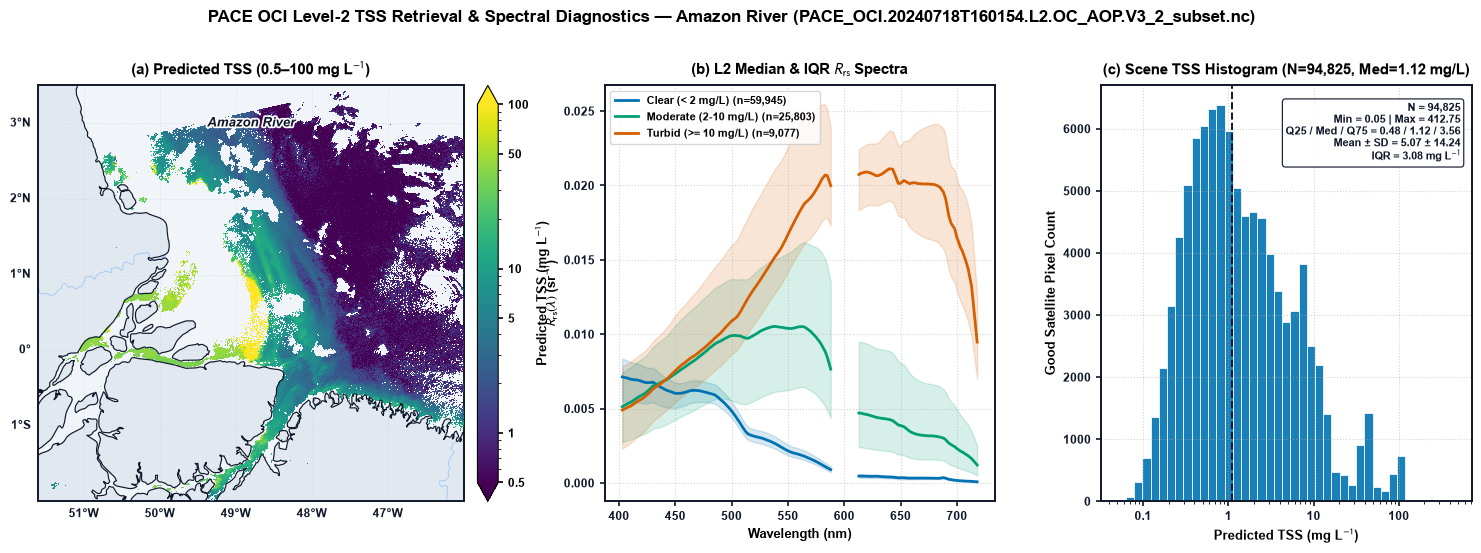

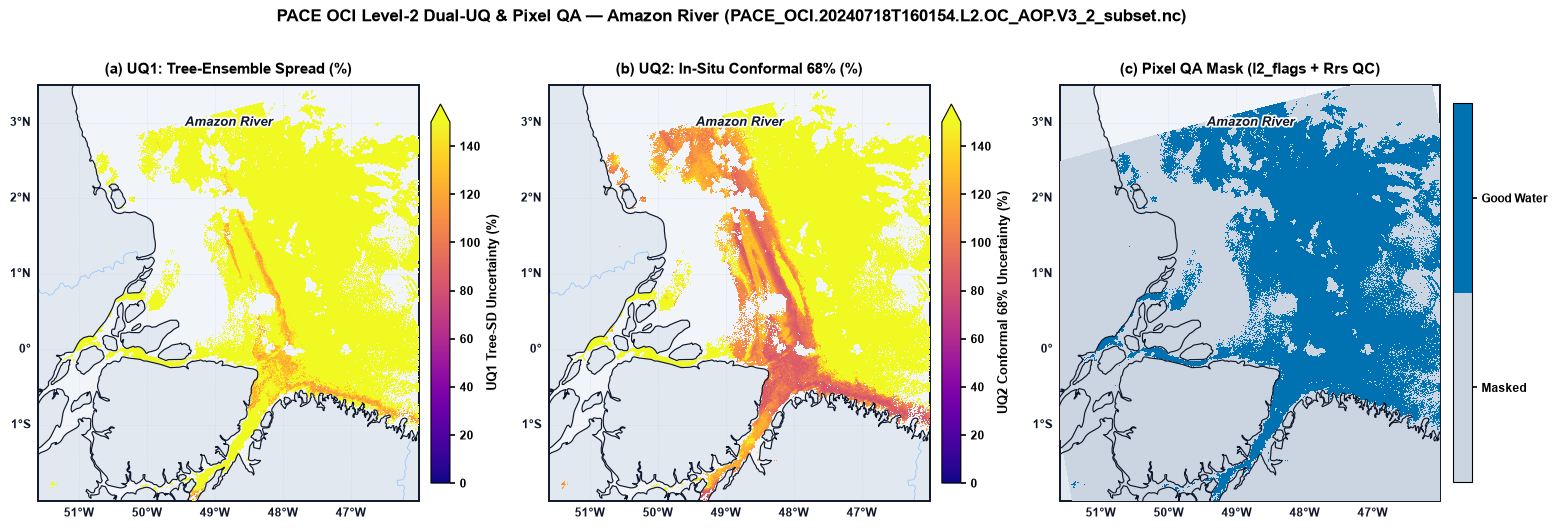

[STEP 13f] Saved Figure 1 & Figure 2 -> /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI.20240718T160154.L2.OC_AOP.V3_2_subset_TSS_Map_Spectra_Hist_20261123_112820.pdf | /Users/masud/OneDrive02/09Nov26_TSS/Final_data/19Nov26_QC_data/RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2/09_pace_l2_nc_inference_and_maps/PACE_OCI.20240718T160154.L2.OC_AOP.V3_2_subset_UQ1_UQ2_QAMask_Maps_20261123_112820.pdf


In [45]:
# ==============================================================================
# STEP 13 (100% STANDALONE): PACE OCI LEVEL-2 (.nc) INFERENCE + DUAL-UQ + MAPS
# ==============================================================================
# Purpose:
#   Applies the pre-trained Case 3b Random Forest model (RF_Full_WithD2) and
#   In-Situ-calibrated Dual Uncertainty Quantification (UQ1 + UQ2) directly to
#   any PACE OCI Level-2 .nc file (SNAP gpt subset or NASA OB.DAAC L2) without
#   requiring Steps 1–12 to be executed in the current kernel.
#
# Sub-steps:
#   13.0) Standalone fallback definitions (wavelengths, band indices, bundle loader)
#   13a)  Auto-install NetCDF/Cartopy dependencies & open SNAP gpt or NASA L2 .nc
#   13b)  Decode l2_flags bitmask (preserving coastal/turbid plumes by default)
#   13c)  Gap-aware vectorized spectral alignment onto 117 PACE bands + Rrs QC
#   13d)  Extract 496 RF_Full_WithD2 features & run chunked 300-tree Dual-UQ inference
#   13e)  Export predicted TSS + Dual-UQ NetCDF & CSV safely (bypassing file locks)
#   13f)  Plot Figure 1 (Smooth TSS + Spectra + Stats Hist) & Figure 2 (UQ1, UQ2, QA)
# ==============================================================================
import os
import pickle as _pickle
import re as _re
import shutil as _shutil
import subprocess as _subprocess
import sys as _sys
import tempfile as _tempfile
import time
import urllib.request as _urllib_req
from datetime import datetime as _dt

import numpy as np
import matplotlib as mpl
import matplotlib.pyplot as plt
import matplotlib.patheffects as _pe
from matplotlib.colors import ListedColormap, LogNorm
from matplotlib.ticker import FuncFormatter
from scipy.ndimage import distance_transform_edt as _edt
from scipy.ndimage import zoom as _nd_zoom
from scipy.signal import savgol_filter

# WHY: Cloud-synced folders (OneDrive/Dropbox) on macOS can lock HDF5 files during
#      NetCDF reads/writes and raise PermissionError.
# HOW: Disable HDF5 POSIX file locking at the process level before importing NetCDF libs.
os.environ["HDF5_USE_FILE_LOCKING"] = "FALSE"

# ------------------------------------------------------------------------------
# STEP 13.0: STANDALONE FALLBACK DEFINITIONS (SO STEP 13 RUNS WITHOUT STEPS 1–12)
# ------------------------------------------------------------------------------
# WHY: Allows you to open a fresh notebook/kernel and run only Step 13 on a new .nc file.
# HOW: Each variable is guarded with `not in globals()` so it reuses Steps 1–12 values
#      if they exist, or initializes identical canonical values if running standalone.
if "RUN_TS" not in globals():
    RUN_TS = _dt.now().strftime("%Y%m%d_%H%M%S")

if "OUT_ROOT" not in globals():
    _cwd = os.getcwd()
    _folder = "RF_Case3b_D2_TSS_Uncertainty_PACE_L2_RSE_v2"
    OUT_ROOT = _cwd if os.path.basename(_cwd) == _folder else os.path.join(_cwd, _folder)

if "DIR_SAVED_MODEL" not in globals():
    DIR_SAVED_MODEL = os.path.join(OUT_ROOT, "08_saved_model_bundle")

if "DIR_L2_INFERENCE" not in globals():
    DIR_L2_INFERENCE = os.path.join(OUT_ROOT, "09_pace_l2_nc_inference_and_maps")

os.makedirs(OUT_ROOT, exist_ok=True)
os.makedirs(DIR_L2_INFERENCE, exist_ok=True)

# Canonical 117 NASA PACE OCI bands (403–718 nm), preserving the 588–613 nm dichroic gap
if "PACE_117_WAVELENGTHS" not in globals():
    PACE_117_WAVELENGTHS = np.array([
        403, 405, 408, 410, 413, 415, 418, 420, 423, 425, 428, 430, 433, 435, 438,
        440, 443, 445, 448, 450, 453, 455, 458, 460, 463, 465, 468, 470, 473, 475,
        478, 480, 483, 485, 488, 490, 493, 495, 498, 500, 503, 505, 508, 510, 513,
        515, 518, 520, 523, 525, 528, 530, 533, 535, 538, 540, 543, 545, 548, 550,
        553, 555, 558, 560, 563, 565, 568, 570, 573, 575, 578, 580, 583, 585, 588,
        613, 615, 618, 620, 623, 625, 628, 630, 633, 635, 638, 640, 643, 645, 648,
        650, 653, 655, 658, 660, 663, 665, 668, 670, 673, 675, 678, 680, 683, 685,
        688, 690, 693, 695, 698, 700, 703, 705, 708, 710, 713, 718
    ], dtype=float)
    BLUE_MASK = PACE_117_WAVELENGTHS <= 588.0  # 75 Blue-Green bands (403-588 nm)
    RED_MASK  = PACE_117_WAVELENGTHS >= 613.0  # 42 Red-NIR bands (613-718 nm)

# Key diagnostic band indices for bio-optical ratios, QAA, FLH, and MCI
if "IDX_413" not in globals():
    def _band_idx_13(wl):
        return int(np.argmin(np.abs(PACE_117_WAVELENGTHS - wl)))
    IDX_413, IDX_443, IDX_490, IDX_510, IDX_555 = (
        _band_idx_13(413), _band_idx_13(443), _band_idx_13(490), _band_idx_13(510), _band_idx_13(555)
    )
    IDX_620, IDX_645, IDX_665, IDX_675, IDX_683, IDX_705, IDX_708, IDX_713 = (
        _band_idx_13(620), _band_idx_13(645), _band_idx_13(665), _band_idx_13(675),
        _band_idx_13(683), _band_idx_13(705), _band_idx_13(708), _band_idx_13(713),
    )

# RSE Journal Matplotlib Configuration (TrueType fonts editable in Illustrator)
mpl.rcParams.update({
    "pdf.fonttype": 42,
    "ps.fonttype": 42,
    "svg.fonttype": "none",
    "font.family": "sans-serif",
    "font.sans-serif": ["Arial", "Helvetica", "DejaVu Sans"],
    "mathtext.fontset": "stixsans",
})

try:
    import joblib as _joblib
    _HAS_JOBLIB_13 = True
except ImportError:
    _HAS_JOBLIB_13 = False

# Auto-locate the saved Step 12 model bundle (.joblib or .pkl)
if "bundle_latest_path" not in globals():
    _cand_bundles = [
        os.path.join(DIR_SAVED_MODEL, "Case3b_RF_Full_WithD2_ModelBundle_LATEST.joblib"),
        os.path.join(DIR_SAVED_MODEL, "Case3b_RF_Full_WithD2_ModelBundle_LATEST.pkl"),
        os.path.join(os.getcwd(), "08_saved_model_bundle", "Case3b_RF_Full_WithD2_ModelBundle_LATEST.joblib"),
        os.path.join(os.getcwd(), "Case3b_RF_Full_WithD2_ModelBundle_LATEST.joblib"),
    ]
    bundle_latest_path = next((p for p in _cand_bundles if os.path.exists(p)), _cand_bundles[0])

if "load_case3b_tss_bundle" not in globals():
    def load_case3b_tss_bundle(bundle_path=bundle_latest_path):
        """Loads the saved Case 3b RF_Full_WithD2 bundle from disk without retraining."""
        if not os.path.exists(bundle_path):
            raise FileNotFoundError(
                f"Saved model bundle not found at:\n  {bundle_path}\n"
                "Run Step 12 once to generate it, or set BUNDLE_PATH to your .joblib/.pkl file."
            )
        if bundle_path.endswith(".joblib") and _HAS_JOBLIB_13:
            return _joblib.load(bundle_path)
        with open(bundle_path, "rb") as f_in:
            return _pickle.load(f_in)


# ------------------------------------------------------------------------------
# STEP 13a (HELPER): PACKAGE CHECK & AUTO-INSTALL
# ------------------------------------------------------------------------------
def _ensure_step13_packages():
    """
    WHY: Satellite NetCDF I/O and map projections require xarray, netCDF4, h5netcdf,
         and cartopy, which may not be pre-installed in every Python environment.
    HOW: Probes each module and quietly pip-installs any missing package once.
    """
    req_pkgs = [
        ("xarray", "xarray"),
        ("netCDF4", "netCDF4"),
        ("h5netcdf", "h5netcdf"),
        ("cartopy", "cartopy"),
    ]
    missing = []
    for mod_name, pip_name in req_pkgs:
        try:
            __import__(mod_name)
        except ImportError:
            missing.append(pip_name)
    if missing:
        print(f"[STEP 13] Installing missing packages: {missing} ...")
        for pkg in missing:
            try:
                _subprocess.check_call([_sys.executable, "-m", "pip", "install", "-q", pkg])
                print(f"          Installed: {pkg}")
            except Exception as exc:
                print(f"          [WARN] Could not pip-install {pkg}: {exc}")


_ensure_step13_packages()
import xarray as xr

try:
    import cartopy.crs as ccrs
    import cartopy.feature as cfeature
    _HAS_CARTOPY_13 = True
except ImportError:
    _HAS_CARTOPY_13 = False


# ------------------------------------------------------------------------------
# STEP 13f (HELPERS): HIGH-RES VECTOR MAP, BOLD AXES & MASK-AWARE SMOOTHING
# ------------------------------------------------------------------------------
def _style_bold_axes(ax):
    """Applies bold spines and bold tick labels for RSE publication figures."""
    for sp in ax.spines.values():
        sp.set_linewidth(1.4)
        sp.set_color("#0F172A")
    ax.tick_params(axis="both", which="major", labelsize=8.5, width=1.2, colors="#0F172A")
    for lbl in ax.get_xticklabels() + ax.get_yticklabels():
        lbl.set_fontweight("bold")
    ax.xaxis.label.set_fontweight("bold")
    ax.yaxis.label.set_fontweight("bold")


def _upsample_masked_2d(data_2d, lat_2d, lon_2d, zoom_factor=4, log_space=False):
    """
    WHY: Native ~1 km PACE OCI pixels appear blocky/pixelated in regional maps.
         Interpolating directly with NaNs would bleed cloud/land edges into water.
    HOW: Performs mask-aware bilinear upsampling (normalized convolution via
         scipy.ndimage.zoom) by `zoom_factor` on both the data (in log10 space
         for TSS, linear space for UQ%) and the valid-pixel weight mask, then
         restores NaNs wherever the interpolated weight < 0.5.
    """
    if zoom_factor <= 1:
        return lon_2d, lat_2d, data_2d

    valid = np.isfinite(data_2d) & ((data_2d > 0) if log_space else True)
    vals = np.where(valid, np.log10(np.maximum(data_2d, 1e-6)) if log_space else data_2d, 0.0).astype(np.float64)
    wts  = valid.astype(np.float64)

    vals_up = _nd_zoom(vals, zoom=zoom_factor, order=1, mode="nearest")
    wts_up  = _nd_zoom(wts,  zoom=zoom_factor, order=1, mode="nearest")
    lat_up  = _nd_zoom(lat_2d.astype(np.float64), zoom=zoom_factor, order=1, mode="nearest")
    lon_up  = _nd_zoom(lon_2d.astype(np.float64), zoom=zoom_factor, order=1, mode="nearest")

    out = np.full_like(vals_up, np.nan, dtype=np.float64)
    keep = wts_up >= 0.5
    out[keep] = vals_up[keep] / wts_up[keep]
    if log_space:
        out[keep] = 10.0 ** out[keep]
    return lon_up, lat_up, out


def create_highres_map_axes(fig, grid_spec_slot, xlim, ylim, region_name=None):
    """
    WHY: Estuarine/coastal satellite maps require crisp 10m coastlines, land/ocean
         contrast, and minimal blank corner space across arbitrary geographic regions.
    HOW: Uses Cartopy Mercator centered on `xlim` (or PlateCarree above ±80° lat) with
         `aspect="auto"` to fill the subplot box cleanly, horizontal bold x-labels,
         and GeoPandas/Matplotlib fallbacks if Cartopy is unavailable.
    """
    lon_c = 0.5 * (xlim[0] + xlim[1])
    if _HAS_CARTOPY_13:
        proj = ccrs.Mercator(central_longitude=lon_c) if max(abs(ylim[0]), abs(ylim[1])) <= 80.0 else ccrs.PlateCarree(central_longitude=lon_c)
        ax = fig.add_subplot(grid_spec_slot, projection=proj)
        ax.set_extent([xlim[0], xlim[1], ylim[0], ylim[1]], crs=ccrs.PlateCarree())
        ax.set_aspect("auto")  # fills subplot box cleanly without blank margins
        ax.add_feature(cfeature.OCEAN.with_scale("10m"), facecolor="#F1F5F9", zorder=0)
        ax.add_feature(cfeature.LAND.with_scale("10m"), facecolor="#E2E8F0", edgecolor="none", zorder=1)
        ax.add_feature(cfeature.RIVERS.with_scale("10m"), edgecolor="#93C5FD", linewidth=0.55, zorder=1.3)
        ax.add_feature(cfeature.BORDERS.with_scale("10m"), edgecolor="#64748B", linewidth=0.60, zorder=1.6)
        ax.add_feature(cfeature.COASTLINE.with_scale("10m"), edgecolor="#0F172A", linewidth=0.85, zorder=4)

        gl = ax.gridlines(
            draw_labels=True, dms=False, x_inline=False, y_inline=False,
            linewidth=0.45, color="#CBD5E1", linestyle=":", zorder=5,
        )
        gl.top_labels = False
        gl.right_labels = False
        gl.xlabel_style = {"size": 8.5, "weight": "bold", "color": "#0F172A", "rotation": 0}
        gl.ylabel_style = {"size": 8.5, "weight": "bold", "color": "#0F172A"}
        for sp in ax.spines.values():
            sp.set_linewidth(1.4)
            sp.set_color("#0F172A")

        if region_name:
            ax.text(
                0.50, 0.91, region_name, transform=ax.transAxes,
                ha="center", va="center", fontsize=9.5, fontweight="bold",
                fontstyle="italic", color="#0F172A",
                path_effects=[_pe.withStroke(linewidth=2.5, foreground="white")],
                zorder=6,
            )
        return ax, {"transform": ccrs.PlateCarree()}

    # Fallback 1: GeoPandas 10m Natural Earth land polygons
    try:
        import geopandas as gpd
        ne10_land = os.path.join(OUT_ROOT, "ne_10m_land.zip")
        if not os.path.exists(ne10_land):
            _urllib_req.urlretrieve("https://naciscdn.org/naturalearth/10m/physical/ne_10m_land.zip", ne10_land)
        gdf_10m = gpd.read_file(ne10_land)
        ax = fig.add_subplot(grid_spec_slot)
        ax.set_facecolor("#F1F5F9")
        gdf_10m.cx[xlim[0]-1:xlim[1]+1, ylim[0]-1:ylim[1]+1].plot(
            ax=ax, facecolor="#E2E8F0", edgecolor="#0F172A", linewidth=0.85, zorder=4
        )
    except Exception:
        # Fallback 2: Pure Matplotlib axes
        ax = fig.add_subplot(grid_spec_slot)
        ax.set_facecolor("#F1F5F9")

    ax.set_xlim(xlim)
    ax.set_ylim(ylim)
    ax.grid(True, linestyle=":", linewidth=0.45, color="#CBD5E1", zorder=5)
    ax.set_xlabel("Longitude (°E)", fontsize=9.0, fontweight="bold")
    ax.set_ylabel("Latitude (°N)", fontsize=9.0, fontweight="bold")
    _style_bold_axes(ax)
    if region_name:
        ax.text(
            0.50, 0.91, region_name, transform=ax.transAxes,
            ha="center", va="center", fontsize=9.5, fontweight="bold",
            fontstyle="italic", color="#0F172A",
            path_effects=[_pe.withStroke(linewidth=2.5, foreground="white")],
            zorder=6,
        )
    return ax, {}


# ------------------------------------------------------------------------------
# STEP 13d (HELPER): VECTORIZED 496-FEATURE BIO-OPTICAL EXTRACTOR
# ------------------------------------------------------------------------------
def extract_biooptical_features_from_rrs(R_in, wavelengths_nm=PACE_117_WAVELENGTHS):
    """
    WHY: Satellite pixels must pass through the exact same 496-feature transformation
         used during RF_Full_WithD2 training so the StandardScaler and trees align.
    HOW: Applies piecewise Savitzky-Golay smoothing & derivatives separately on
         403–588 nm and 613–718 nm (avoiding artifacts across the 588–613 nm OCI
         dichroic gap), computes L2-normalized spectral shape, and appends 28
         semi-analytical QAA, NDSSI, line-height, and sub-band integral features.
    """
    R_raw = np.asarray(R_in, dtype=np.float64)
    if R_raw.ndim == 1:
        R_raw = R_raw[None, :]

    b_mask = wavelengths_nm <= 588.0
    r_mask = wavelengths_nm >= 613.0
    wl_b = wavelengths_nm[b_mask]
    wl_r = wavelengths_nm[r_mask]

    # 1. Piecewise Savitzky-Golay smoothing per continuous segment
    R_smooth = np.empty_like(R_raw)
    d1 = np.empty_like(R_raw)
    d2 = np.empty_like(R_raw)

    R_b_sm = savgol_filter(R_raw[:, b_mask], window_length=7, polyorder=2, axis=1)
    R_r_sm = savgol_filter(R_raw[:, r_mask], window_length=7, polyorder=2, axis=1)
    R_smooth[:, b_mask] = R_b_sm
    R_smooth[:, r_mask] = R_r_sm

    # 2. First (d1) and second (d2) spectral derivatives per segment
    d1[:, b_mask] = np.gradient(R_b_sm, wl_b, axis=1)
    d1[:, r_mask] = np.gradient(R_r_sm, wl_r, axis=1)
    d2[:, b_mask] = np.gradient(d1[:, b_mask], wl_b, axis=1)
    d2[:, r_mask] = np.gradient(d1[:, r_mask], wl_r, axis=1)

    # 3. L2-normalized spectral shape (decouples glint/illumination amplitude)
    l2_norm = np.linalg.norm(R_smooth, axis=1, keepdims=True)
    l2_norm = np.where(l2_norm > 1e-12, l2_norm, 1.0)
    R_l2 = R_smooth / l2_norm

    # 4. 28 Bio-optical band ratios, Lee et al. (2002) QAA u(lambda), FLH/MCI & integrals
    eps = 1e-6
    Rp = np.maximum(R_smooth, eps)
    oc3_max_blue = np.maximum.reduce([Rp[:, IDX_443], Rp[:, IDX_490], Rp[:, IDX_510]])
    g0, g1 = 0.089, 0.1245
    rrs_sub = np.clip(R_smooth, -0.05, 0.25) / (0.52 + 1.7 * np.clip(R_smooth, -0.05, 0.25))
    u_665 = (-g0 + np.sqrt(np.maximum(g0**2 + 4 * g1 * rrs_sub[:, IDX_665], 0.0))) / (2 * g1)
    u_708 = (-g0 + np.sqrt(np.maximum(g0**2 + 4 * g1 * rrs_sub[:, IDX_708], 0.0))) / (2 * g1)

    peak_wl = wavelengths_nm[np.argmax(R_smooth, axis=1)]
    slope_red_nir = (R_smooth[:, IDX_713] - R_smooth[:, IDX_620]) / (713.0 - 620.0)
    _trapz_fn = getattr(np, "trapezoid", getattr(np, "trapz", None))
    m_b  = (wavelengths_nm >= 403) & (wavelengths_nm <= 490)
    m_g  = (wavelengths_nm >= 500) & (wavelengths_nm <= 588)
    m_r  = (wavelengths_nm >= 613) & (wavelengths_nm <= 718)
    m_re = (wavelengths_nm >= 685) & (wavelengths_nm <= 718)

    int_blue   = _trapz_fn(R_smooth[:, m_b], wavelengths_nm[m_b], axis=1)
    int_green  = _trapz_fn(R_smooth[:, m_g], wavelengths_nm[m_g], axis=1)
    int_rednir = _trapz_fn(R_smooth[:, m_r], wavelengths_nm[m_r], axis=1)
    int_re     = _trapz_fn(R_smooth[:, m_re], wavelengths_nm[m_re], axis=1)

    X_ratios = np.column_stack([
        np.log10(oc3_max_blue / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_443] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_490] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_413] / Rp[:, IDX_443]),
        np.log10(Rp[:, IDX_645] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_665] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_705] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_555]),
        np.log10(Rp[:, IDX_665] / Rp[:, IDX_490]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_443]),
        np.log10(Rp[:, IDX_705] / Rp[:, IDX_665]),
        np.log10(Rp[:, IDX_708] / Rp[:, IDX_675]),
        np.log10(Rp[:, IDX_713] / Rp[:, IDX_665]),
        (R_smooth[:, IDX_665] - R_smooth[:, IDX_555]) / (np.abs(R_smooth[:, IDX_665]) + np.abs(R_smooth[:, IDX_555]) + eps),
        (R_smooth[:, IDX_708] - R_smooth[:, IDX_555]) / (np.abs(R_smooth[:, IDX_708]) + np.abs(R_smooth[:, IDX_555]) + eps),
        (R_smooth[:, IDX_708] - R_smooth[:, IDX_490]) / (np.abs(R_smooth[:, IDX_708]) + np.abs(R_smooth[:, IDX_490]) + eps),
        ((1.0 / Rp[:, IDX_665]) - (1.0 / Rp[:, IDX_705])) * Rp[:, IDX_713],
        R_smooth[:, IDX_705] - R_smooth[:, IDX_683] - ((R_smooth[:, IDX_713] - R_smooth[:, IDX_683]) * (22.0 / 30.0)),
        R_smooth[:, IDX_683] - R_smooth[:, IDX_665] - ((R_smooth[:, IDX_705] - R_smooth[:, IDX_665]) * (18.0 / 40.0)),
        R_smooth[:, IDX_555] - R_smooth[:, IDX_490] - ((R_smooth[:, IDX_620] - R_smooth[:, IDX_490]) * (65.0 / 130.0)),
        u_665, u_708, peak_wl, slope_red_nir,
        int_blue, int_green, int_rednir, int_re / (np.abs(int_green) + eps),
    ])
    X_ratios = np.nan_to_num(X_ratios, nan=0.0, posinf=0.0, neginf=0.0)
    return np.hstack([R_smooth, R_l2, d1, d2, X_ratios]).astype(np.float32)


# ------------------------------------------------------------------------------
# STEP 13b (HELPER): BITMASK QUALITY-FLAG DECODER
# ------------------------------------------------------------------------------
def decode_l2_flags_mask(ds, exclude_flags=None):
    """
    WHY: PACE L2 products encode quality conditions as a 32-bit integer bitmask;
         blindly masking all non-zero flags would drop valid turbid/coastal pixels
         (COASTZ, TURBIDW).
    HOW: Reads CF `flag_masks` & `flag_meanings` from `l2_flags`, counts every flag
         for diagnostics, and masks only the explicitly requested `exclude_flags`.
    """
    if exclude_flags is None:
        exclude_flags = [
            "ATMFAIL", "LAND", "CLDICE", "HIGLINT", "HILT",
            "STRAYLIGHT", "NAVFAIL", "SEAICE", "BOWTIEDEL", "PRODFAIL",
            "MAXAERITER", "LOWLW", "HISATZEN", "HISOLZEN", "FILTER",
        ]
    if "l2_flags" not in ds:
        return None, {}

    flags_arr = ds["l2_flags"].to_numpy()
    valid_int = np.isfinite(flags_arr)
    flags_int = np.where(valid_int, flags_arr, 0).astype(np.int64)

    attrs = ds["l2_flags"].attrs
    masks = attrs.get("flag_masks", [])
    meanings = attrs.get("flag_meanings", "")
    if isinstance(meanings, str):
        meanings = meanings.split()

    is_masked = ~valid_int
    flag_counts = {}
    for m_val, name in zip(masks, meanings):
        hit = (flags_int & int(m_val)) != 0
        flag_counts[name] = int(hit.sum())
        if name in exclude_flags:
            is_masked |= hit
    return is_masked, flag_counts


# ------------------------------------------------------------------------------
# STEP 13c (HELPER): VECTORIZED SEGMENT INTERPOLATION
# ------------------------------------------------------------------------------
def _interp_segment_vectorized(wl_src, R_src, wl_dst):
    """
    WHY: L2 .nc wavelengths (e.g., 172 bands) differ slightly from the 117-band
         training grid and must be aligned rapidly across tens of thousands of pixels.
    HOW: Performs vectorized 1D linear interpolation along axis=1 within a single
         contiguous spectral segment (blue-green or red-NIR).
    """
    order = np.argsort(wl_src)
    x = wl_src[order]
    Y = R_src[:, order]
    idx = np.searchsorted(x, wl_dst, side="right") - 1
    idx = np.clip(idx, 0, len(x) - 2)
    x0 = x[idx]
    x1 = x[idx + 1]
    w = np.clip((wl_dst - x0) / np.maximum(x1 - x0, 1e-12), 0.0, 1.0)
    return Y[:, idx] * (1.0 - w[None, :]) + Y[:, idx + 1] * w[None, :]


# ------------------------------------------------------------------------------
# STEP 13e (HELPER): LOCK-SAFE NETCDF WRITER
# ------------------------------------------------------------------------------
def _safe_write_netcdf(out_ds, out_nc_path):
    """
    WHY: Direct HDF5 writes into cloud-synced directories can fail with PermissionError.
    HOW: Stages the NetCDF in a local /tmp file first, then copies to `out_nc_path`
         (with a ~/Downloads fallback if the destination folder blocks writes).
    """
    out_dir = os.path.dirname(out_nc_path)
    os.makedirs(out_dir, exist_ok=True)
    if os.path.exists(out_nc_path):
        try:
            os.remove(out_nc_path)
        except PermissionError:
            pass

    fd, tmp_nc = _tempfile.mkstemp(suffix=".nc")
    os.close(fd)
    try:
        wrote = False
        for _eng in ["h5netcdf", "netcdf4", None]:
            try:
                if _eng is None:
                    out_ds.to_netcdf(tmp_nc)
                else:
                    out_ds.to_netcdf(tmp_nc, engine=_eng)
                wrote = True
                break
            except Exception:
                continue
        if not wrote:
            raise RuntimeError("Failed to write temporary NetCDF with h5netcdf or netcdf4.")
        try:
            _shutil.copy2(tmp_nc, out_nc_path)
            return out_nc_path
        except PermissionError:
            fallback_nc = os.path.join(os.path.expanduser("~"), "Downloads", os.path.basename(out_nc_path))
            _shutil.copy2(tmp_nc, fallback_nc)
            print(f"[WARN] OneDrive blocked write to {out_nc_path}; saved instead to -> {fallback_nc}")
            return fallback_nc
    finally:
        if os.path.exists(tmp_nc):
            os.remove(tmp_nc)


# ------------------------------------------------------------------------------
# MAIN INFERENCE ENGINE (STEPS 13a -> 13e)
# ------------------------------------------------------------------------------
def predict_tss_from_l2_nc(
    nc_path,
    bundle_path=bundle_latest_path,
    out_nc_path=None,
    out_csv_path=None,
    exclude_flags=None,
    chunk_size=25000,
):
    """
    Loads the saved Case 3b RF_Full_WithD2 bundle from disk and applies it + Dual-UQ
    directly to any PACE OCI Level-2 .nc file (SNAP gpt subset or NASA OB.DAAC L2).
    """
    t_start = time.time()
    bundle = load_case3b_tss_bundle(bundle_path)
    rf_m   = bundle["rf_model"]
    sc_m   = bundle["scaler"]
    wl_ref = bundle["wavelengths_nm"]
    uq_cfg = bundle["uq2_conformal"]

    # --- Step 13a: Open NetCDF & auto-detect schema (SNAP gpt vs NASA OB.DAAC) ---
    ds = None
    extra_ds = []
    for _eng in ["netcdf4", "h5netcdf", None]:
        try:
            ds = xr.open_dataset(nc_path) if _eng is None else xr.open_dataset(nc_path, engine=_eng)
            break
        except Exception:
            continue
    if ds is None:
        raise RuntimeError(f"Could not open NetCDF file with netcdf4 or h5netcdf: {nc_path}")

    if "Rrs" in ds:
        rrs_da = ds["Rrs"]
        wl_dim = rrs_da.dims[-1]
        wl_nc = np.asarray(ds.coords.get(wl_dim, ds.get("wavelength_3d", np.arange(rrs_da.shape[-1]))), dtype=float)
        spatial_shape = rrs_da.shape[:-1]
        spatial_dims = list(rrs_da.dims[:-1])
        R_2d = rrs_da.to_numpy().reshape(-1, rrs_da.shape[-1])
        lat_2d = ds["latitude"].to_numpy() if "latitude" in ds else ds["lat"].to_numpy()
        lon_2d = ds["longitude"].to_numpy() if "longitude" in ds else ds["lon"].to_numpy()
    else:
        band_vars = []
        for k in ds.data_vars:
            m = _re.fullmatch(r"Rrs_(\d{3,4})", k)
            if m:
                wl_val = float(ds[k].attrs.get("radiation_wavelength", int(m.group(1))))
                band_vars.append((wl_val, k))
        band_vars.sort(key=lambda x: x[0])

        if not band_vars:
            ds.close()
            ds_geo = xr.open_dataset(nc_path, group="geophysical_data")
            ds_nav = xr.open_dataset(nc_path, group="navigation_data")
            ds_sbp = xr.open_dataset(nc_path, group="sensor_band_parameters")
            extra_ds.extend([ds_nav, ds_sbp])
            rrs_da = ds_geo["Rrs"]
            wl_nc = np.asarray(ds_sbp["wavelength_3d"].to_numpy(), dtype=float)
            spatial_shape = rrs_da.shape[:-1]
            spatial_dims = list(rrs_da.dims[:-1])
            R_2d = rrs_da.to_numpy().reshape(-1, rrs_da.shape[-1])
            lat_2d = ds_nav["latitude"].to_numpy()
            lon_2d = ds_nav["longitude"].to_numpy()
            ds = ds_geo
        else:
            wl_nc = np.array([bw[0] for bw in band_vars], dtype=float)
            arrs = [ds[bw[1]].to_numpy().astype(np.float64) for bw in band_vars]
            spatial_shape = arrs[0].shape
            spatial_dims = list(ds[band_vars[0][1]].dims)
            R_2d = np.stack([a.ravel() for a in arrs], axis=1)
            lat_name = next((c for c in ["lat", "latitude", "Latitude"] if c in ds or c in ds.coords), None)
            lon_name = next((c for c in ["lon", "longitude", "Longitude"] if c in ds or c in ds.coords), None)
            lat_2d = ds[lat_name].to_numpy() if lat_name else np.full(spatial_shape, np.nan)
            lon_2d = ds[lon_name].to_numpy() if lon_name else np.full(spatial_shape, np.nan)

    # Sanitize coordinates (strip NetCDF fill values & normalize lon to [-180, 180])
    lat_2d = np.asarray(lat_2d, dtype=np.float64)
    lon_2d = np.asarray(lon_2d, dtype=np.float64)
    lat_2d = np.where(np.isfinite(lat_2d) & (lat_2d >= -90.0) & (lat_2d <= 90.0), lat_2d, np.nan)
    lon_2d = np.where(np.isfinite(lon_2d) & (lon_2d >= -180.0) & (lon_2d <= 360.0), lon_2d, np.nan)
    lon_2d = np.where(np.isfinite(lon_2d) & (lon_2d > 180.0), ((lon_2d + 180.0) % 360.0) - 180.0, lon_2d)

    print(
        f"[STEP 13a] Opened {os.path.basename(nc_path)} | grid={spatial_shape} | "
        f"{len(wl_nc)} Rrs bands ({wl_nc.min():.1f}-{wl_nc.max():.1f} nm) | "
        f"lat=[{np.nanmin(lat_2d):.2f}, {np.nanmax(lat_2d):.2f}], "
        f"lon=[{np.nanmin(lon_2d):.2f}, {np.nanmax(lon_2d):.2f}]"
    )

    # --- Step 13b: Decode l2_flags & build quality mask ---
    flag_mask_2d, flag_counts = decode_l2_flags_mask(ds, exclude_flags=exclude_flags)
    if flag_mask_2d is not None:
        flag_mask_flat = flag_mask_2d.ravel()
        top_flags = ", ".join(f"{k}:{v}" for k, v in sorted(flag_counts.items(), key=lambda kv: -kv[1])[:10] if v > 0)
        print(f"[STEP 13b] Decoded l2_flags | Masked={flag_mask_flat.sum():,} / {flag_mask_flat.size:,} | Top flags: {top_flags}")
    else:
        flag_mask_flat = np.zeros(R_2d.shape[0], dtype=bool)
        flag_mask_2d = np.zeros(spatial_shape, dtype=bool)

    ds.close()
    for _eds in extra_ds:
        _eds.close()

    # --- Step 13c: Gap-aware vectorized spectral alignment + physical Rrs QC ---
    b_src = wl_nc <= 589.5
    r_src = wl_nc >= 611.5
    b_dst = wl_ref <= 588.0
    r_dst = wl_ref >= 613.0

    R_117 = np.full((R_2d.shape[0], len(wl_ref)), np.nan, dtype=np.float64)
    finite_src = np.all(np.isfinite(R_2d[:, b_src]), axis=1) & np.all(np.isfinite(R_2d[:, r_src]), axis=1)
    vis_mask = (wl_nc >= 440.0) & (wl_nc <= 670.0)

    phys_qc = np.zeros(R_2d.shape[0], dtype=bool)
    if finite_src.any():
        r_vis = R_2d[finite_src][:, vis_mask]
        phys_qc[finite_src] = (np.min(r_vis, axis=1) > -0.002) & (np.max(r_vis, axis=1) < 0.25)

    valid_px = (
        (~flag_mask_flat)
        & finite_src
        & phys_qc
        & np.isfinite(lat_2d.ravel())
        & np.isfinite(lon_2d.ravel())
    )

    if valid_px.any():
        R_b_interp = _interp_segment_vectorized(wl_nc[b_src], R_2d[valid_px][:, b_src], wl_ref[b_dst])
        R_r_interp = _interp_segment_vectorized(wl_nc[r_src], R_2d[valid_px][:, r_src], wl_ref[r_dst])
        R_117[np.ix_(valid_px, b_dst)] = R_b_interp
        R_117[np.ix_(valid_px, r_dst)] = R_r_interp

    print(f"[STEP 13c] Gap-aware alignment & QC complete | Good water pixels: {valid_px.sum():,} ({100.0*valid_px.mean():.1f}%)")

    # --- Step 13d: Chunked 496-feature extraction & 300-tree Dual-UQ inference ---
    n_px = len(R_117)
    pred_lin = np.full(n_px, np.nan, dtype=np.float32)
    uq1_rel  = np.full(n_px, np.nan, dtype=np.float32)
    uq2_rel  = np.full(n_px, np.nan, dtype=np.float32)
    uq2_lo68 = np.full(n_px, np.nan, dtype=np.float32)
    uq2_hi68 = np.full(n_px, np.nan, dtype=np.float32)
    uq2_lo95 = np.full(n_px, np.nan, dtype=np.float32)
    uq2_hi95 = np.full(n_px, np.nan, dtype=np.float32)

    valid_idx = np.where(valid_px)[0]
    for s_i in range(0, len(valid_idx), chunk_size):
        chunk_idx = valid_idx[s_i : s_i + chunk_size]
        X_feat = extract_biooptical_features_from_rrs(R_117[chunk_idx], wl_ref)
        X_sc   = sc_m.transform(X_feat)
        tree_p = np.column_stack([est.predict(X_sc) for est in rf_m.estimators_])
        m_log  = np.mean(tree_p, axis=1)
        sd_log = np.std(tree_p, axis=1, ddof=1)
        hw68   = uq_cfg["q68_mult"] * (sd_log + uq_cfg["eps0"])
        hw95   = uq_cfg["q95_mult"] * (sd_log + uq_cfg["eps0"])

        pred_lin[chunk_idx] = (10.0 ** m_log).astype(np.float32)
        uq1_rel[chunk_idx]  = (100.0 * (10.0 ** sd_log - 1.0)).astype(np.float32)
        uq2_rel[chunk_idx]  = (100.0 * (10.0 ** hw68 - 1.0)).astype(np.float32)
        uq2_lo68[chunk_idx] = (10.0 ** (m_log - hw68)).astype(np.float32)
        uq2_hi68[chunk_idx] = (10.0 ** (m_log + hw68)).astype(np.float32)
        uq2_lo95[chunk_idx] = (10.0 ** (m_log - hw95)).astype(np.float32)
        uq2_hi95[chunk_idx] = (10.0 ** (m_log + hw95)).astype(np.float32)

    # --- Step 13e: Package CF-compliant xarray Dataset & export NetCDF / CSV ---
    out_ds = xr.Dataset(
        {
            "TSS_pred":         (spatial_dims, pred_lin.reshape(spatial_shape), {"units": "mg L^-1", "long_name": "Predicted Total Suspended Solids (Case 3b RF_Full_WithD2)"}),
            "TSS_UQ1_RelUnc":   (spatial_dims, uq1_rel.reshape(spatial_shape),  {"units": "%", "long_name": "UQ1 Tree-Ensemble Relative Uncertainty"}),
            "TSS_UQ2_RelUnc":   (spatial_dims, uq2_rel.reshape(spatial_shape),  {"units": "%", "long_name": "UQ2 In-Situ Conformal 68% Relative Uncertainty"}),
            "TSS_UQ2_Low68":    (spatial_dims, uq2_lo68.reshape(spatial_shape), {"units": "mg L^-1"}),
            "TSS_UQ2_High68":   (spatial_dims, uq2_hi68.reshape(spatial_shape), {"units": "mg L^-1"}),
            "TSS_UQ2_Low95":    (spatial_dims, uq2_lo95.reshape(spatial_shape), {"units": "mg L^-1"}),
            "TSS_UQ2_High95":   (spatial_dims, uq2_hi95.reshape(spatial_shape), {"units": "mg L^-1"}),
            "valid_water_mask": (spatial_dims, valid_px.reshape(spatial_shape).astype(np.int8)),
        },
        coords={
            "lat": (spatial_dims, lat_2d),
            "lon": (spatial_dims, lon_2d),
        },
        attrs={
            "source_l2_file": os.path.basename(nc_path),
            "model_bundle": os.path.basename(bundle_path),
            "model_name": bundle["model_name"],
        },
    )

    if out_nc_path:
        saved_nc = _safe_write_netcdf(out_ds, out_nc_path)
        print(f"[STEP 13e] Saved L2 TSS + Dual-UQ NetCDF -> {saved_nc}")
    if out_csv_path:
        os.makedirs(os.path.dirname(out_csv_path), exist_ok=True)
        out_ds.to_dataframe().dropna(subset=["TSS_pred"]).reset_index().to_csv(out_csv_path, index=False)
        print(f"[STEP 13e] Saved valid-pixel CSV          -> {out_csv_path}")

    med_str = f"{np.nanmedian(pred_lin):.2f} mg/L" if np.isfinite(pred_lin).any() else "N/A (0 valid pixels)"
    print(f"[STEP 13d] Inference finished in {time.time() - t_start:.2f}s | Median TSS = {med_str}")
    return out_ds, R_117[valid_px], pred_lin[valid_px], lat_2d, lon_2d, (flag_mask_2d | (~valid_px.reshape(spatial_shape)))


# ------------------------------------------------------------------------------
# STEP 13f: RSE PUBLICATION FIGURES (SMOOTH COLOR LAYER + TRUE VECTOR OVERLAYS)
# ------------------------------------------------------------------------------
def plot_pace_l2_tss_maps(
    out_ds,
    lat_2d,
    lon_2d,
    qa_masked_2d,
    R_valid,
    tss_valid,
    out_dir,
    run_ts,
    lon_lim=None,
    lat_lim=None,
    region_name=None,
    smooth_factor=4,
):
    """
    WHY: Produces editable vector-PDF figures for Remote Sensing of Environment.
         Only the continuous color fields (TSS, UQ1, UQ2) are upsampled by
         `smooth_factor` and rasterized (`rasterized=True`) at 300 DPI so color
         gradients look smooth rather than 1 km-pixelated, while ALL coastlines,
         land polygons, borders, rivers, grids, axes, colorbars, and text remain
         100% true editable vectors.
    """
    os.makedirs(out_dir, exist_ok=True)

    xlim = tuple(lon_lim) if lon_lim is not None else (float(np.nanmin(lon_2d)), float(np.nanmax(lon_2d)))
    ylim = tuple(lat_lim) if lat_lim is not None else (float(np.nanmin(lat_2d)), float(np.nanmax(lat_2d)))

    src_name = out_ds.attrs.get("source_l2_file", "PACE_OCI_L2")
    src_stem = os.path.splitext(src_name)[0]
    title_loc = f"{region_name} ({src_name})" if region_name else src_name

    tss_2d = out_ds["TSS_pred"].to_numpy()
    uq1_2d = out_ds["TSS_UQ1_RelUnc"].to_numpy()
    uq2_2d = out_ds["TSS_UQ2_RelUnc"].to_numpy()
    qa_2d  = np.where(np.isfinite(tss_2d), 1.0, np.where(qa_masked_2d, 0.0, np.nan))

    # Nearest-neighbor fill for any swath-edge NaNs in lat/lon before upsampling
    if not (np.all(np.isfinite(lon_2d)) and np.all(np.isfinite(lat_2d))):
        _bad_ll = ~(np.isfinite(lon_2d) & np.isfinite(lat_2d))
        if _bad_ll.any() and (~_bad_ll).any():
            _, _idx = _edt(_bad_ll, return_distances=True, return_indices=True)
            lon_2d = lon_2d[tuple(_idx)]
            lat_2d = lat_2d[tuple(_idx)]

    # Smooth continuous color fields for visualization only (exported .nc/.csv remain native 1 km)
    lon_tss, lat_tss, tss_sm = _upsample_masked_2d(tss_2d, lat_2d, lon_2d, zoom_factor=smooth_factor, log_space=True)
    lon_uq1, lat_uq1, uq1_sm = _upsample_masked_2d(uq1_2d, lat_2d, lon_2d, zoom_factor=smooth_factor, log_space=False)
    lon_uq2, lat_uq2, uq2_sm = _upsample_masked_2d(uq2_2d, lat_2d, lon_2d, zoom_factor=smooth_factor, log_space=False)

    # ==========================================================================
    # FIGURE 1: (a) Smooth TSS Map + (b) Rrs Spectra + (c) Histogram w/ Stats
    # ==========================================================================
    fig1 = plt.figure(figsize=(18.5, 5.4))
    gs1 = fig1.add_gridspec(1, 3, width_ratios=[1.18, 1.0, 0.95], wspace=0.26)

    # Panel (a): Predicted TSS (0.2 to 120 mg/L, extend='both', viridis, rasterized color layer)
    ax1a, kw1a = create_highres_map_axes(fig1, gs1[0, 0], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_tss = plt.get_cmap("viridis").copy()
    cmap_tss.set_bad(alpha=0.0)
    tss_ticks = [ 0.5, 1, 5, 10, 50, 100]
    norm_tss = LogNorm(vmin=0.5, vmax=100)
    tss_plot = np.ma.masked_invalid(np.where(np.isfinite(tss_sm), np.clip(tss_sm, 0.5, 100), np.nan))
    pm_1a = ax1a.pcolormesh(
        lon_tss, lat_tss, tss_plot, cmap=cmap_tss, norm=norm_tss,
        shading="auto", rasterized=True, zorder=3, **kw1a
    )
    cb_1a = fig1.colorbar(pm_1a, ax=ax1a, fraction=0.046, pad=0.03, extend="both")
    cb_1a.set_ticks(tss_ticks)
    cb_1a.set_ticklabels([str(t) for t in tss_ticks])
    cb_1a.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_1a.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    cb_1a.set_label("Predicted TSS (mg L$^{-1}$)", fontsize=9.5, fontweight="bold")
    ax1a.set_title("(a) Predicted TSS (0.5–100 mg L$^{-1}$)", fontsize=10.5, fontweight="bold", pad=8)

    # Panel (b): L2 Median & IQR Rrs Spectra by Predicted TSS Regime (Okabe-Ito, true vector)
    ax1b = fig1.add_subplot(gs1[0, 1])
    regimes = [
        ("Clear (< 2 mg/L)",     tss_valid < 2.0, "#0072B2"),                        # Okabe-Ito Blue
        ("Moderate (2-10 mg/L)", (tss_valid >= 2.0) & (tss_valid < 10.0), "#009E73"),# Okabe-Ito Bluish-Green
        ("Turbid (>= 10 mg/L)",  tss_valid >= 10.0, "#D55E00"),                      # Okabe-Ito Vermilion
    ]
    wl_b = PACE_117_WAVELENGTHS[BLUE_MASK]
    wl_r = PACE_117_WAVELENGTHS[RED_MASK]
    plotted_any = False
    for r_label, r_mask, r_col in regimes:
        if r_mask.sum() < 5:
            continue
        plotted_any = True
        med_spec = np.nanmedian(R_valid[r_mask], axis=0)
        q25_spec = np.nanpercentile(R_valid[r_mask], 25, axis=0)
        q75_spec = np.nanpercentile(R_valid[r_mask], 75, axis=0)
        ax1b.plot(wl_b, med_spec[BLUE_MASK], color=r_col, lw=2.0, label=f"{r_label} (n={r_mask.sum():,})")
        ax1b.plot(wl_r, med_spec[RED_MASK], color=r_col, lw=2.0)
        ax1b.fill_between(wl_b, q25_spec[BLUE_MASK], q75_spec[BLUE_MASK], color=r_col, alpha=0.16)
        ax1b.fill_between(wl_r, q25_spec[RED_MASK], q75_spec[RED_MASK], color=r_col, alpha=0.16)
    ax1b.set_xlabel("Wavelength (nm)", fontsize=9.5, fontweight="bold")
    ax1b.set_ylabel(r"$R_{\mathrm{rs}}(\lambda)$ (sr$^{-1}$)", fontsize=9.5, fontweight="bold")
    ax1b.set_title(r"(b) L2 Median & IQR $R_{\mathrm{rs}}$ Spectra", fontsize=10.5, fontweight="bold", pad=8)
    if plotted_any:
        leg1b = ax1b.legend(frameon=True, fontsize=8.5, prop={"weight": "bold", "size": 8.2})
        leg1b.get_frame().set_linewidth(1.0)
    ax1b.grid(True, linestyle=":", alpha=0.55)
    _style_bold_axes(ax1b)

    # Panel (c): L2 Scene TSS Distribution Histogram + Min/Max/Basic Stats Inset (true vector)
    ax1c = fig1.add_subplot(gs1[0, 2])
    tss_pos = tss_valid[np.isfinite(tss_valid) & (tss_valid > 0)]
    if len(tss_pos) > 0:
        bins_log = np.logspace(
            np.log10(max(0.05, tss_pos.min())),
            np.log10(min(500.0, max(tss_pos.max() * 1.1, 0.2))),
            42,
        )
        ax1c.hist(tss_pos, bins=bins_log, color="#0072B2", edgecolor="white", linewidth=0.6, alpha=0.90)
        ax1c.set_xscale("log")
        ax1c.xaxis.set_major_formatter(FuncFormatter(lambda v, _: f"{v:g}"))

        min_t  = float(np.min(tss_pos))
        max_t  = float(np.max(tss_pos))
        q25_t, med_t, q75_t = np.percentile(tss_pos, [25.0, 50.0, 75.0])
        mean_t = float(np.mean(tss_pos))
        sd_t   = float(np.std(tss_pos, ddof=1)) if len(tss_pos) > 1 else 0.0
        iqr_t  = float(q75_t - q25_t)

        ax1c.axvline(med_t, color="#0F172A", linestyle="--", linewidth=1.4)

        stats_txt = (
            f"N = {len(tss_pos):,}\n"
            f"Min = {min_t:.2f} | Max = {max_t:.2f}\n"
            f"Q25 / Med / Q75 = {q25_t:.2f} / {med_t:.2f} / {q75_t:.2f}\n"
            f"Mean ± SD = {mean_t:.2f} ± {sd_t:.2f}\n"
            f"IQR = {iqr_t:.2f} mg L$^{{-1}}$"
        )
        ax1c.text(
            0.97, 0.96, stats_txt, transform=ax1c.transAxes,
            fontsize=7.6, fontweight="bold", va="top", ha="right", color="#0F172A",
            bbox=dict(boxstyle="round,pad=0.30", facecolor="white", alpha=0.92, edgecolor="#0F172A", linewidth=0.9),
            zorder=6,
        )
        ax1c.set_title(
            f"(c) Scene TSS Histogram (N={len(tss_pos):,}, Med={med_t:.2f} mg/L)",
            fontsize=10.5, fontweight="bold", pad=8
        )
    else:
        ax1c.set_title("(c) Scene TSS Histogram (N=0 valid pixels)", fontsize=10.5, fontweight="bold", pad=8)
    ax1c.set_xlabel("Predicted TSS (mg L$^{-1}$)", fontsize=9.5, fontweight="bold")
    ax1c.set_ylabel("Good Satellite Pixel Count", fontsize=9.5, fontweight="bold")
    ax1c.grid(True, linestyle=":", alpha=0.55)
    _style_bold_axes(ax1c)

    fig1.suptitle(
        f"PACE OCI Level-2 TSS Retrieval & Spectral Diagnostics — {title_loc}",
        fontsize=12.0, fontweight="bold", y=1.02
    )
    fig1_pdf = os.path.join(out_dir, f"{src_stem}_TSS_Map_Spectra_Hist_{run_ts}.pdf")
    fig1.savefig(fig1_pdf, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()

    # ==========================================================================
    # FIGURE 2: (a) Smooth UQ1 + (b) Smooth UQ2 [Shared Cividis] + (c) QA Mask
    # ==========================================================================
    fig2 = plt.figure(figsize=(18.5, 5.4))
    gs2 = fig2.add_gridspec(1, 3, wspace=0.24)
    # uq_cmap_name = "cividis" "plasma"
    uq_cmap_name = "plasma"

    # Panel (a): UQ1 Tree-Ensemble Spread (%) — smooth rasterized color layer + vector overlays
    ax2a, kw2a = create_highres_map_axes(fig2, gs2[0, 0], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_uq1 = plt.get_cmap(uq_cmap_name).copy()
    cmap_uq1.set_bad(alpha=0.0)
    uq1_plot = np.ma.masked_invalid(np.where(np.isfinite(uq1_sm), np.clip(uq1_sm, 0, 150), np.nan))
    pm_2a = ax2a.pcolormesh(
        lon_uq1, lat_uq1, uq1_plot, cmap=cmap_uq1, vmin=0, vmax=150,
        shading="auto", rasterized=True, zorder=3, **kw2a
    )
    cb_2a = fig2.colorbar(pm_2a, ax=ax2a, fraction=0.046, pad=0.03, extend="max")
    cb_2a.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_2a.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    cb_2a.set_label("UQ1 Tree-SD Uncertainty (%)", fontsize=9.5, fontweight="bold")
    ax2a.set_title("(a) UQ1: Tree-Ensemble Spread (%)", fontsize=10.5, fontweight="bold", pad=8)

    # Panel (b): UQ2 In-Situ Conformal 68% Interval (%) — smooth rasterized color layer + vector overlays
    ax2b, kw2b = create_highres_map_axes(fig2, gs2[0, 1], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_uq2 = plt.get_cmap(uq_cmap_name).copy()
    cmap_uq2.set_bad(alpha=0.0)
    uq2_plot = np.ma.masked_invalid(np.where(np.isfinite(uq2_sm), np.clip(uq2_sm, 0, 150), np.nan))
    pm_2b = ax2b.pcolormesh(
        lon_uq2, lat_uq2, uq2_plot, cmap=cmap_uq2, vmin=0, vmax=150,
        shading="auto", rasterized=True, zorder=3, **kw2b
    )
    cb_2b = fig2.colorbar(pm_2b, ax=ax2b, fraction=0.046, pad=0.03, extend="max")
    cb_2b.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_2b.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    cb_2b.set_label("UQ2 Conformal 68% Uncertainty (%)", fontsize=9.5, fontweight="bold")
    ax2b.set_title("(b) UQ2: In-Situ Conformal 68% (%)", fontsize=10.5, fontweight="bold", pad=8)

    # Panel (c): Pixel QA Mask (binary, NOT interpolated)
    ax2c, kw2c = create_highres_map_axes(fig2, gs2[0, 2], xlim=xlim, ylim=ylim, region_name=region_name)
    cmap_qa = ListedColormap(["#CBD5E1", "#0072B2"])
    cmap_qa.set_bad(alpha=0.0)
    qa_plot = np.ma.masked_invalid(qa_2d)
    pm_2c = ax2c.pcolormesh(
        lon_2d, lat_2d, qa_plot, cmap=cmap_qa, vmin=-0.5, vmax=1.5,
        shading="auto", rasterized=True, zorder=3, **kw2c
    )
    cb_2c = fig2.colorbar(pm_2c, ax=ax2c, fraction=0.046, pad=0.03, ticks=[0, 1])
    cb_2c.set_ticklabels(["Masked", "Good Water"])
    cb_2c.ax.tick_params(labelsize=8.5, width=1.2)
    for lbl in cb_2c.ax.get_yticklabels():
        lbl.set_fontweight("bold")
    ax2c.set_title("(c) Pixel QA Mask (l2_flags + Rrs QC)", fontsize=10.5, fontweight="bold", pad=8)

    fig2.suptitle(
        f"PACE OCI Level-2 Dual-UQ & Pixel QA — {title_loc}",
        fontsize=12.0, fontweight="bold", y=1.02
    )
    fig2_pdf = os.path.join(out_dir, f"{src_stem}_UQ1_UQ2_QAMask_Maps_{run_ts}.pdf")
    fig2.savefig(fig2_pdf, format="pdf", dpi=300, bbox_inches="tight")
    plt.show()
    print(f"[STEP 13f] Saved Figure 1 & Figure 2 -> {fig1_pdf} | {fig2_pdf}")


# ==============================================================================
# RUN STANDALONE STEP 13 ON ANY PACE OCI LEVEL-2 .nc FILE
# /Users/masud/OneDrive02/MODIS_manuscript/StCruise26/PACE_3_2/Irrawady/PACE_OCI.20241202T061144.L2.OC_AOP.V3_2_subset.nc
# "/Users/masud/OneDrive02/MODIS_manuscript/StCruise26/PACE_3_2/BoB/PACE_OCI.20241012T063653.L2.OC_AOP.V3_2_subset.nc"
# "/Users/masud/OneDrive02/MODIS_manuscript/StCruise26/PACE_3_2/YellowSea/PACE_OCI.20241106T043323.L2.OC_AOP.V3_2_subset.nc"
# "/Users/masud/OneDrive02/MODIS_manuscript/StCruise26/PACE_3_2/Amazon/PACE_OCI.20240718T160154.L2.OC_AOP.V3_2_subset.nc"
# "/Users/masud/OneDrive02/MODIS_manuscript/StCruise26/PACE_3_2/SAB/PACE_OCI.20260926T171924.L2.OC_AOP.V3_2.NRT_subset.nc" & "PACE_OCI.20260927T175357.L2.OC_AOP.V3_2.NRT_subset.nc"
# ==============================================================================
L2_NC_FILE    = "/Users/masud/OneDrive02/MODIS_manuscript/StCruise26/PACE_3_2/Amazon/PACE_OCI.20240718T160154.L2.OC_AOP.V3_2_subset.nc"
BUNDLE_PATH   = bundle_latest_path   # Or set explicit path to Case3b_RF_Full_WithD2_ModelBundle_LATEST.joblib
REGION_NAME   = "Amazon River"      # Optional label on map, or None to omit
# LON_LIM       = (86.0000, 92.5000)   # BoB Explicit bounds (or set to None to auto-detect from .nc)
# LAT_LIM       = (19.0000, 23.0000)   # Explicit bounds (or set to None to auto-detect from .nc)
# LON_LIM       = (94.0000, 96.0000)   # Irrawaddy; Explicit bounds (or set to None to auto-detect from .nc)
# LAT_LIM       = (14.5000, 16.3000)   # Explicit bounds (or set to None to auto-detect from .nc)
# LON_LIM       = (-82.1760, -77.50249)   # SAB; Explicit bounds (or set to None to auto-detect from .nc)
# LAT_LIM       = (27.5754, 34.0000)   # SAB, Explicit bounds (or set to None to auto-detect from .nc)
# LON_LIM       = (117.0000, 127.0000)   # Irrawaddy; Explicit bounds (or set to None to auto-detect from .nc)
# LAT_LIM       = (34.1000, 41.5000)   # Explicit bounds (or set to None to auto-detect from .nc)
LON_LIM       = (-51.6000, -46.0000)   # Amazon; Explicit bounds (or set to None to auto-detect from .nc)
LAT_LIM       = (-2.0000, 3.5000)   # Explicit bounds (or set to None to auto-detect from .nc)
# LON_LIM       = (94.0000, 96.0000)   # Irrawaddy; Explicit bounds (or set to None to auto-detect from .nc)
# LAT_LIM       = (14.5000, 16.3000)   # Explicit bounds (or set to None to auto-detect from .nc)

SMOOTH_FACTOR = 4                    # Upsampling factor for smooth color transitions (1 = native 1 km pixels)

# Option 3: Explicitly configure which l2_flags to mask
all_pace_flags = [
    # --- Fatal / contaminated pixels (KEEP masked) ---
    # "ATMFAIL", "LAND", "CLDICE", "HIGLINT", "HILT",
    # "STRAYLIGHT", "NAVFAIL", "SEAICE", "BOWTIEDEL", "PRODFAIL",
    # "MAXAERITER", "LOWLW", "HISATZEN", "HISOLZEN", "FILTER",

    # --- Coastal / turbid / soft-warning flags (UNCOMMENT ONLY if you want to mask them) ---
    # "COASTZ", "TURBIDW", "CHLFAIL", "CHLWARN", "COCCOLITH",
    # "PRODWARN", "ATMWARN", "ABSAER", "HIPOL", "NAVWARN", "MODGLINT",
]

if os.path.exists(L2_NC_FILE):
    nc_stem = os.path.splitext(os.path.basename(L2_NC_FILE))[0]
    out_nc  = os.path.join(DIR_L2_INFERENCE, f"{nc_stem}_TSS_WithDualUQ_{RUN_TS}.nc")
    out_csv = os.path.join(DIR_L2_INFERENCE, f"{nc_stem}_TSS_WithDualUQ_{RUN_TS}.csv")
    ds_tss, R_val, tss_val, lat2d, lon2d, qa_mask2d = predict_tss_from_l2_nc(
        nc_path=L2_NC_FILE,
        bundle_path=BUNDLE_PATH,
        out_nc_path=out_nc,
        out_csv_path=out_csv,
        exclude_flags=all_pace_flags,
    )
    plot_pace_l2_tss_maps(
        ds_tss, lat2d, lon2d, qa_mask2d, R_val, tss_val,
        DIR_L2_INFERENCE, RUN_TS,
        lon_lim=LON_LIM,
        lat_lim=LAT_LIM,
        region_name=REGION_NAME,
        smooth_factor=SMOOTH_FACTOR,
    )
else:
    print(f"[WARN] File not found: {L2_NC_FILE}")